In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together


from minmax_opt_class_mgnn import MinMaxOptProb

In [2]:
def u0(x):
    return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0
t_max = 1
x_min = -1
x_max = 1

In [3]:
notes = '''This notebook is for computing Burgers equation with sin init, \n
featured with initial gamma = 0.1, f_opt_kh = 1, use_a = True, and L1reg = 0.1.\n
We use warmup_exponential_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 1.
In this copy, we train 5000 epoches. '''
print(notes)

This notebook is for computing Burgers equation with sin init, 

featured with initial gamma = 0.1, f_opt_kh = 1, use_a = True, and L1reg = 0.1.

We use warmup_exponential_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 1.
In this copy, we train 5000 epoches. 


In [4]:
N_t = 8
N_x = 17
seq_trainer = SeqMinMaxOptProb(
    num_segments=2,
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
    N_t=N_t, N_x=N_x, N_bc=2048, N_ic=4096, pre_epochs=0,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_opt_kh=1,
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="seq_minmax_burgers_sin_wave",
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes=notes, lambda_tv=0, N_t_pnts = N_t, N_x_pnts = N_x,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, total_grade=1, k=0, f_plot=1000, plt_err_dist=True, plt_mesh=True, partition='rect',
    set_wandb=False
)


Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Plotting before training segment [0.0000, 0.5000]


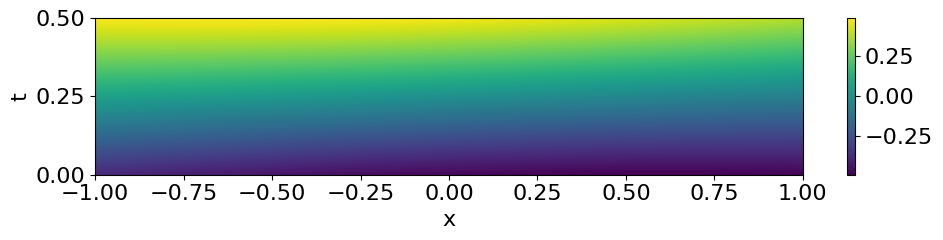

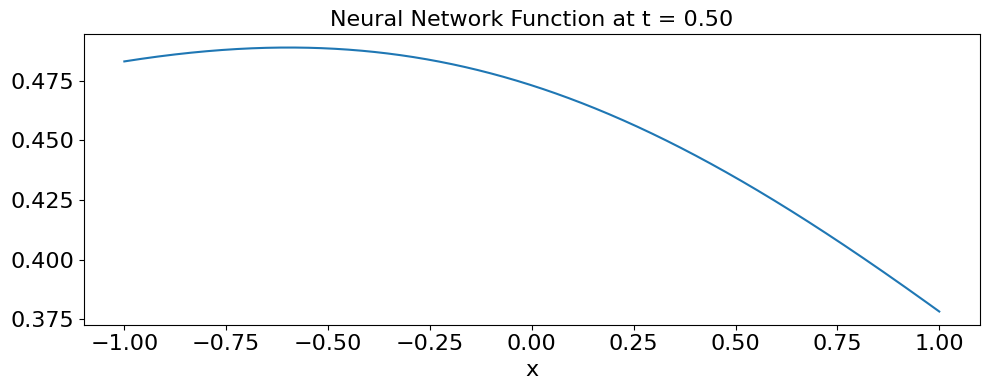


Training segment [0.0000, 0.5000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 6.352427
Grade 0, Iter 0, lambda_ic: 9.618529, lambda_bc: 9.953506, lambda_eqn: 1.036342
Grade 0, Iter 0, loss_eqn: 1.831945, loss_eqn_from_kh: 1.831943, loss_l1: 1.831943, loss_ibc: 0.812924
The largest W^{1,inf} norm of k_h coeffs is 7.918732


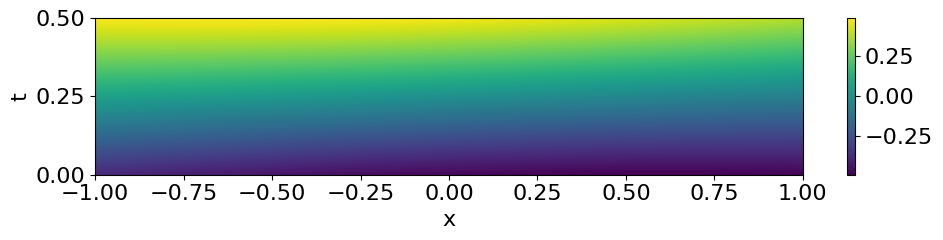

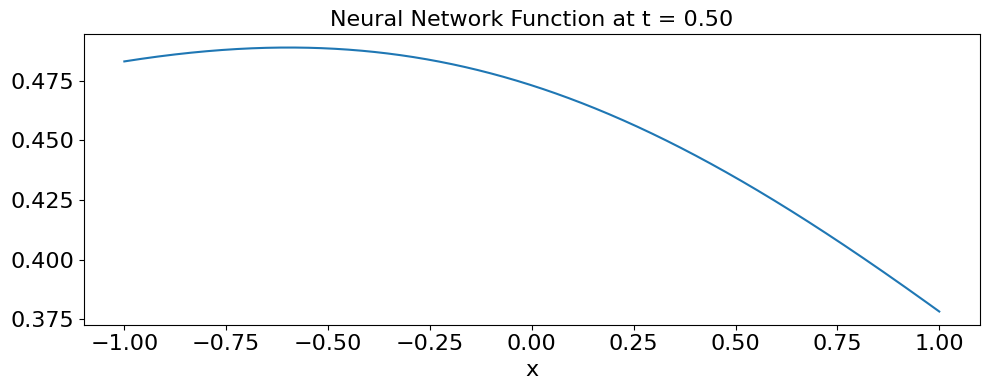

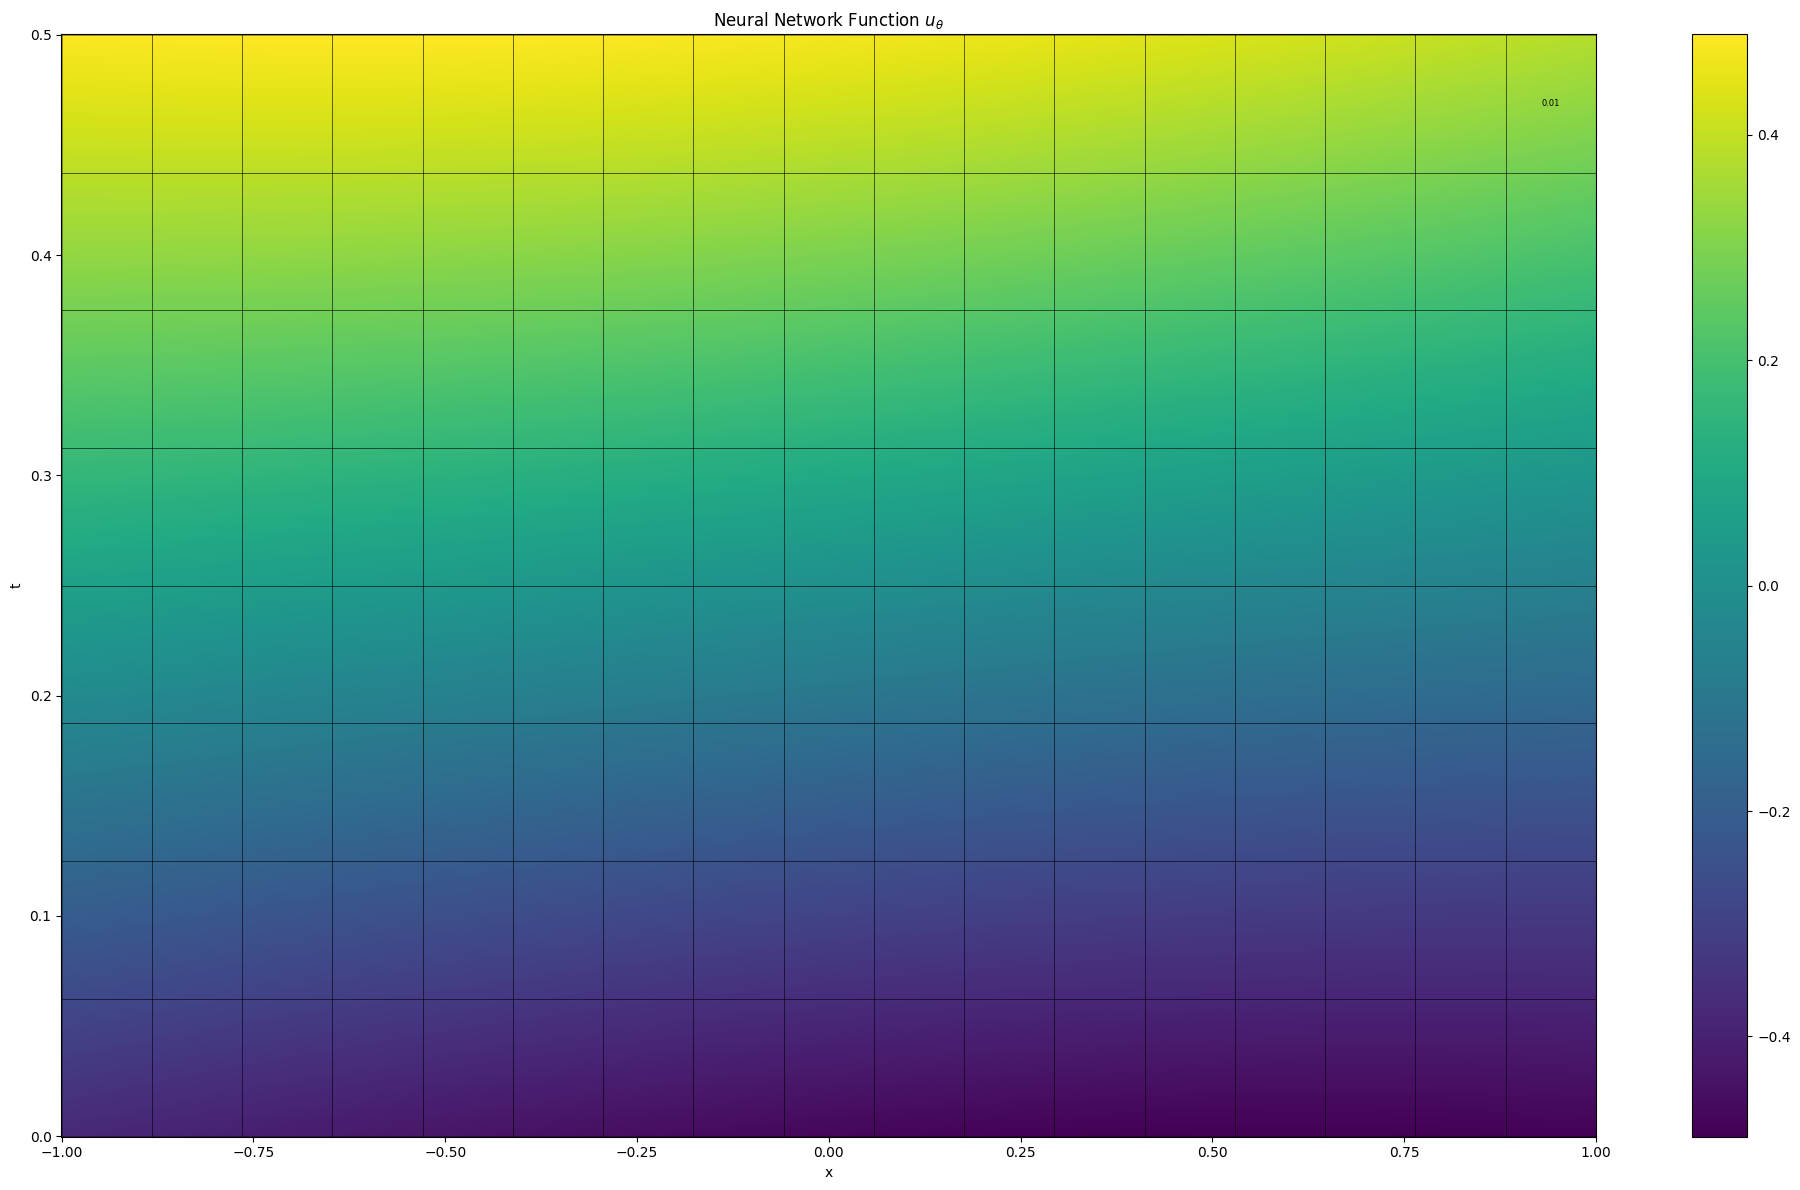

Grade 0, Iter 100, loss_eqn: 0.019114, loss_eqn_from_kh: 0.019114, loss_l1: 0.019115, loss_ibc: 0.442897
The largest W^{1,inf} norm of k_h coeffs is 9.886005
Grade 0, Iter 200, loss_eqn: 0.526596, loss_eqn_from_kh: 0.526596, loss_l1: 0.526612, loss_ibc: 0.026936
The largest W^{1,inf} norm of k_h coeffs is 9.881420
Grade 0, Iter 300, loss_eqn: 0.473196, loss_eqn_from_kh: 0.473196, loss_l1: 0.473196, loss_ibc: 0.020624
The largest W^{1,inf} norm of k_h coeffs is 9.884661
Grade 0, Iter 400, loss_eqn: 0.470689, loss_eqn_from_kh: 0.470689, loss_l1: 0.470689, loss_ibc: 0.015217
The largest W^{1,inf} norm of k_h coeffs is 9.900305
Grade 0, Iter 500, loss_eqn: 0.408724, loss_eqn_from_kh: 0.408724, loss_l1: 0.408728, loss_ibc: 0.009790
The largest W^{1,inf} norm of k_h coeffs is 9.972479
Grade 0, Iter 600, loss_eqn: 0.281631, loss_eqn_from_kh: 0.281631, loss_l1: 0.281633, loss_ibc: 0.006145
The largest W^{1,inf} norm of k_h coeffs is 9.888306
Grade 0, Iter 700, loss_eqn: 0.178077, loss_eqn_from

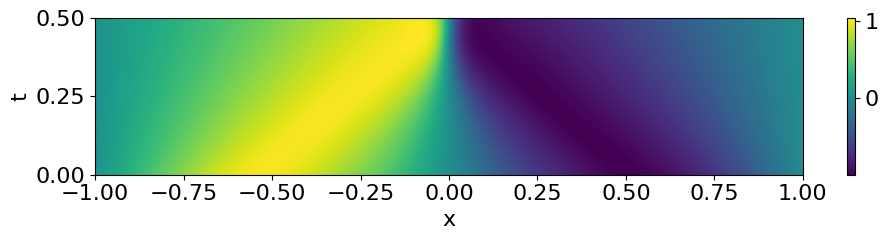

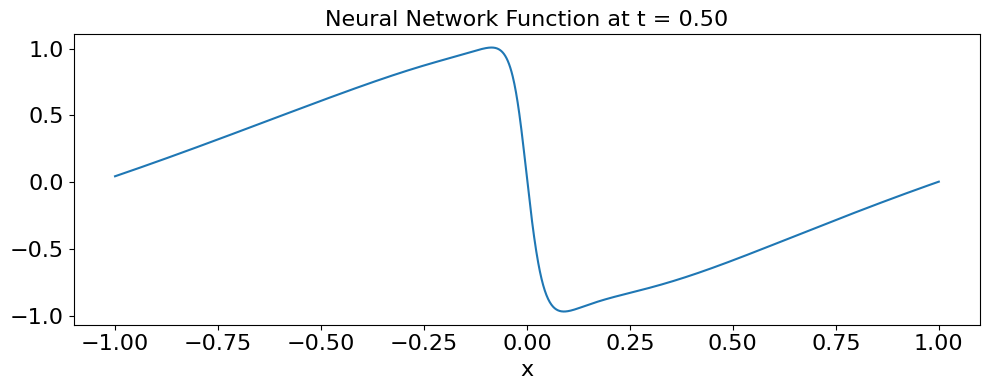

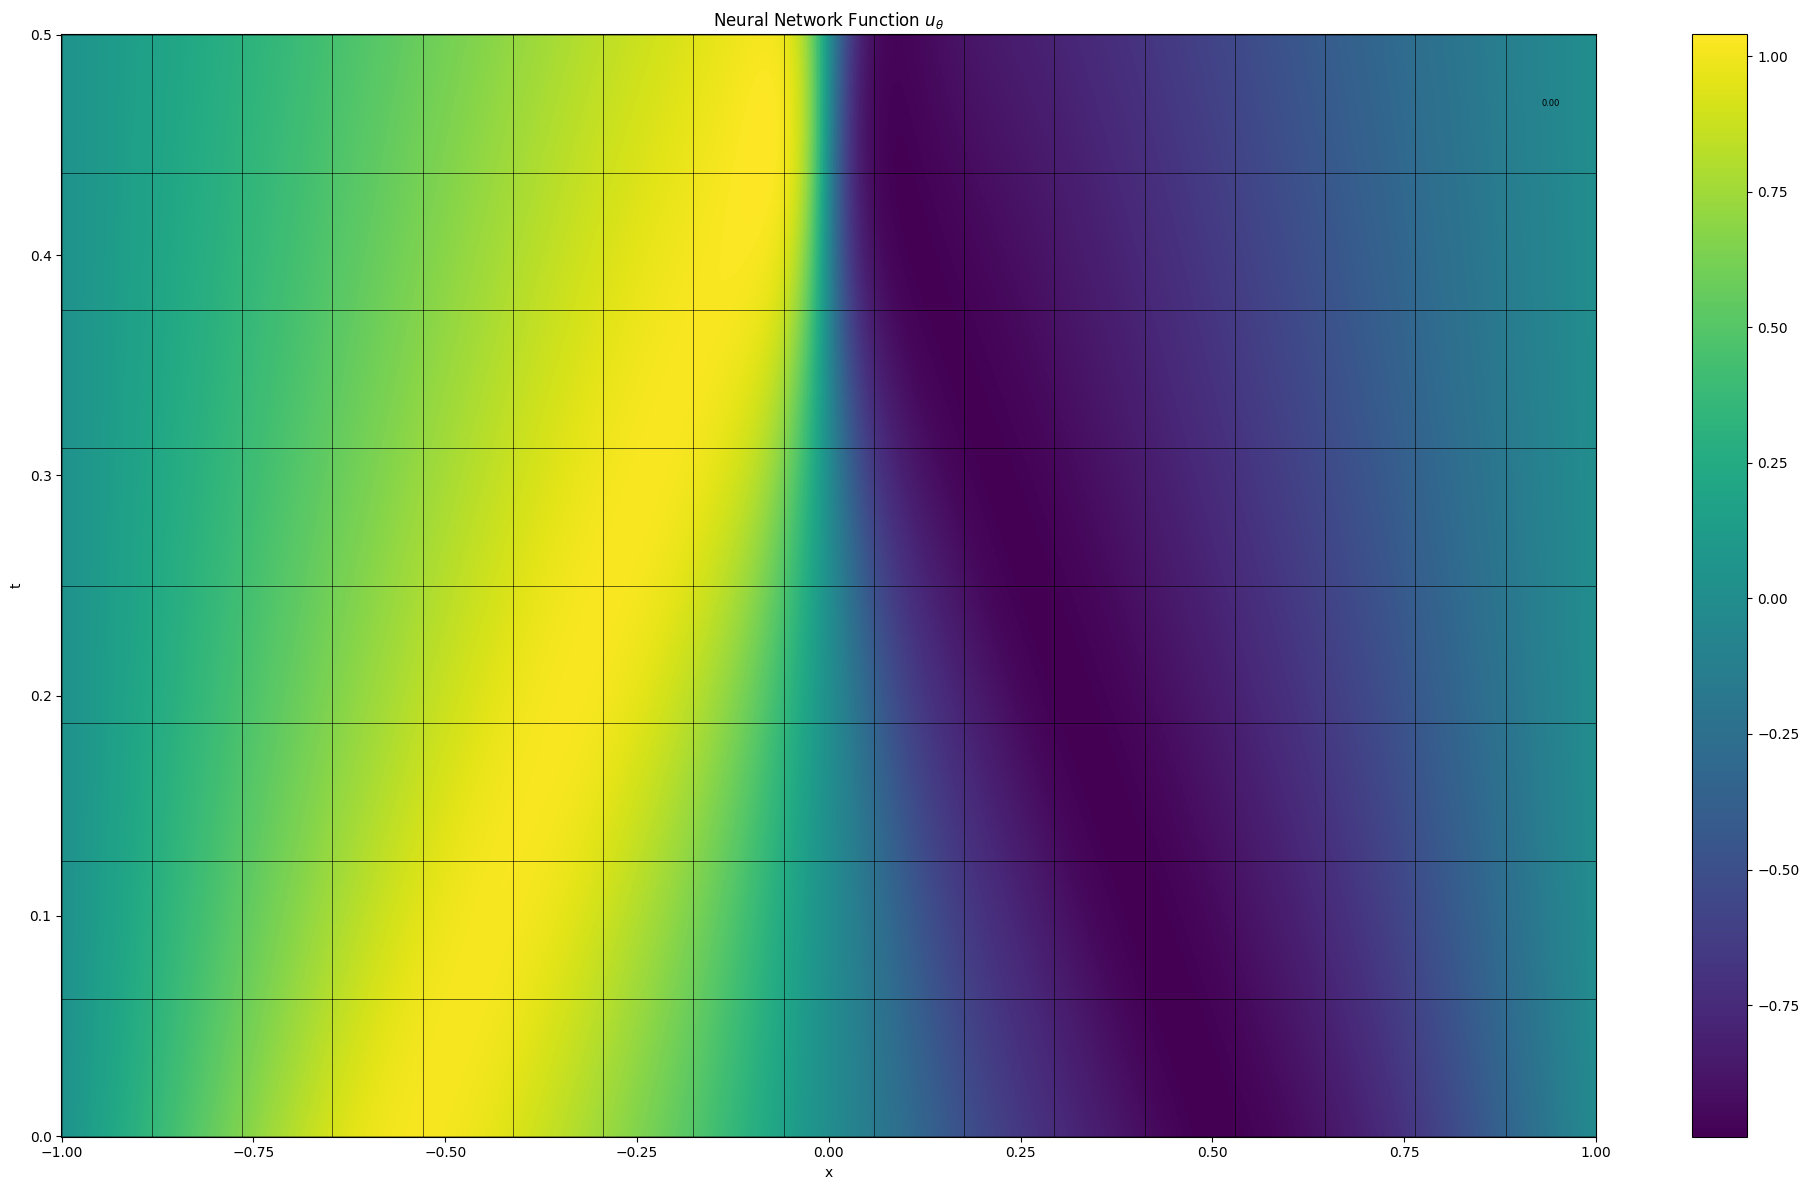

Grade 0, Iter 1100, loss_eqn: 0.051703, loss_eqn_from_kh: 0.051703, loss_l1: 0.220922, loss_ibc: 0.001114
The largest W^{1,inf} norm of k_h coeffs is 9.966469
Grade 0, Iter 1200, loss_eqn: 0.066025, loss_eqn_from_kh: 0.066025, loss_l1: 0.246008, loss_ibc: 0.000849
The largest W^{1,inf} norm of k_h coeffs is 9.988179
Grade 0, Iter 1300, loss_eqn: 0.056422, loss_eqn_from_kh: 0.056422, loss_l1: 0.245677, loss_ibc: 0.003920
The largest W^{1,inf} norm of k_h coeffs is 9.975662
Grade 0, Iter 1400, loss_eqn: 0.036855, loss_eqn_from_kh: 0.036855, loss_l1: 0.239678, loss_ibc: 0.000784
The largest W^{1,inf} norm of k_h coeffs is 9.991695
Grade 0, Iter 1500, loss_eqn: 0.051321, loss_eqn_from_kh: 0.051321, loss_l1: 0.231707, loss_ibc: 0.000257
The largest W^{1,inf} norm of k_h coeffs is 9.935918
Grade 0, Iter 1600, loss_eqn: 0.033562, loss_eqn_from_kh: 0.033562, loss_l1: 0.243984, loss_ibc: 0.000955
The largest W^{1,inf} norm of k_h coeffs is 9.981499
Grade 0, Iter 1700, loss_eqn: 0.073003, loss_e

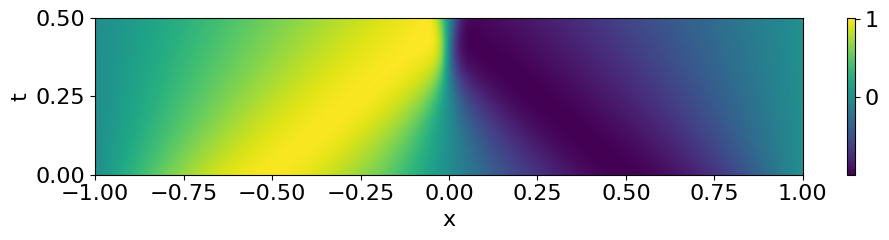

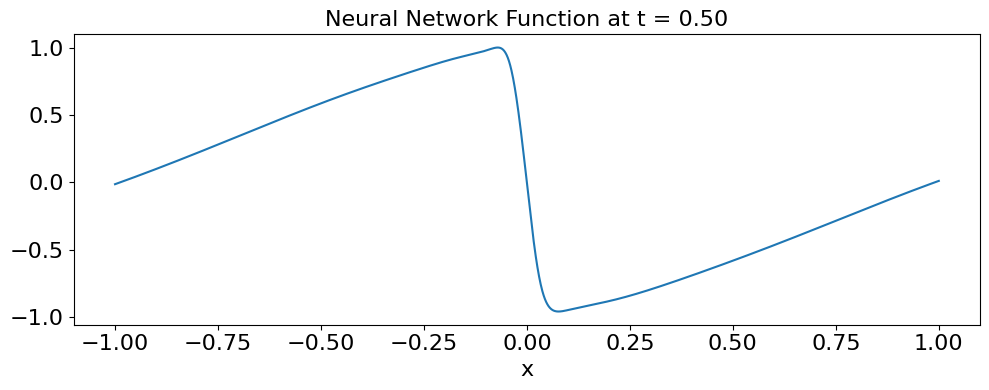

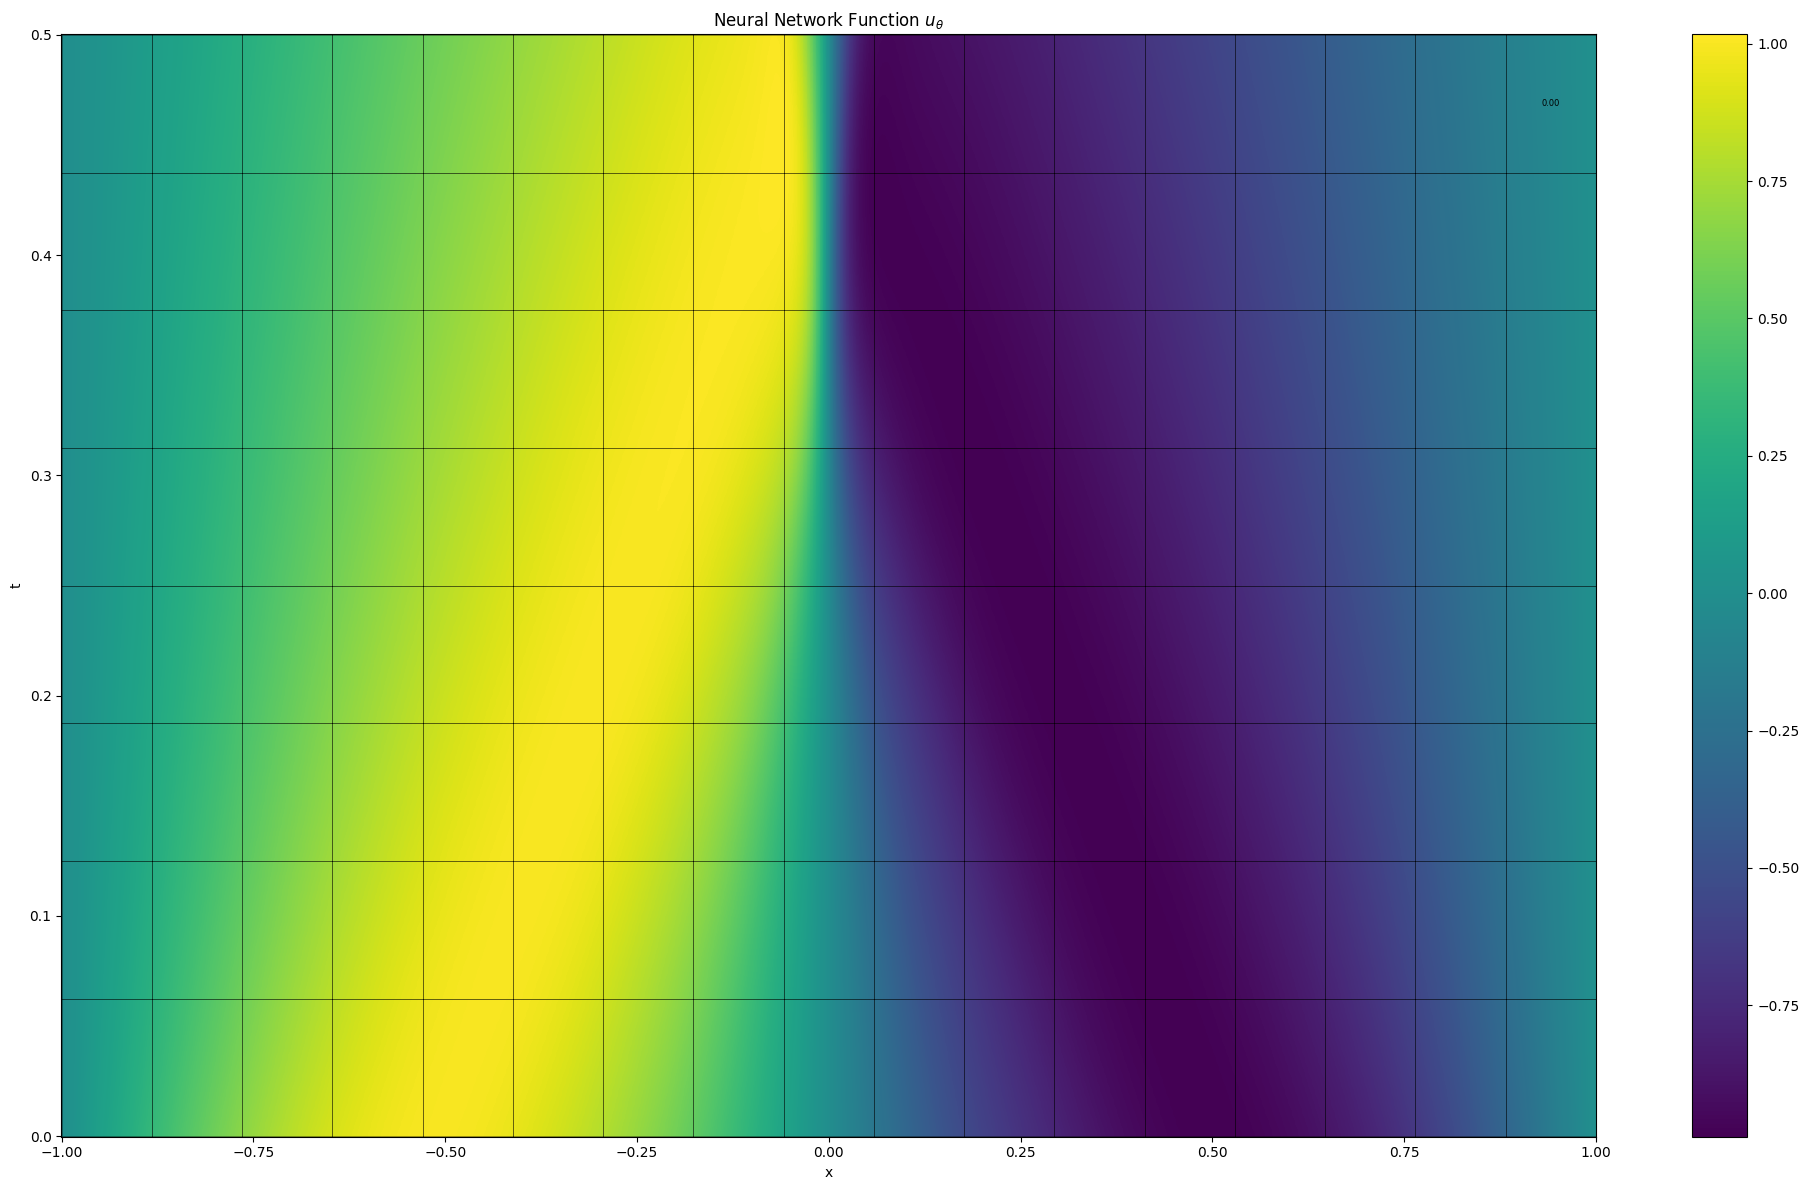

Grade 0, Iter 2100, loss_eqn: 0.037699, loss_eqn_from_kh: 0.037699, loss_l1: 0.256603, loss_ibc: 0.001534
The largest W^{1,inf} norm of k_h coeffs is 9.995990
Grade 0, Iter 2200, loss_eqn: 0.021427, loss_eqn_from_kh: 0.021427, loss_l1: 0.239807, loss_ibc: 0.002344
The largest W^{1,inf} norm of k_h coeffs is 9.955875
Grade 0, Iter 2300, loss_eqn: 0.033785, loss_eqn_from_kh: 0.033785, loss_l1: 0.246982, loss_ibc: 0.000104
The largest W^{1,inf} norm of k_h coeffs is 9.883394
Grade 0, Iter 2400, loss_eqn: 0.047197, loss_eqn_from_kh: 0.047197, loss_l1: 0.257108, loss_ibc: 0.000664
The largest W^{1,inf} norm of k_h coeffs is 9.959076
Grade 0, Iter 2500, loss_eqn: 0.045067, loss_eqn_from_kh: 0.045067, loss_l1: 0.262106, loss_ibc: 0.001178
The largest W^{1,inf} norm of k_h coeffs is 9.813395
Grade 0, Iter 2600, loss_eqn: 0.053219, loss_eqn_from_kh: 0.053219, loss_l1: 0.261421, loss_ibc: 0.002343
The largest W^{1,inf} norm of k_h coeffs is 9.909075
Grade 0, Iter 2700, loss_eqn: 0.034460, loss_e

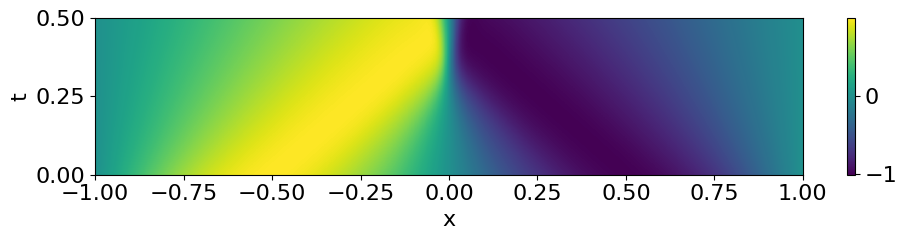

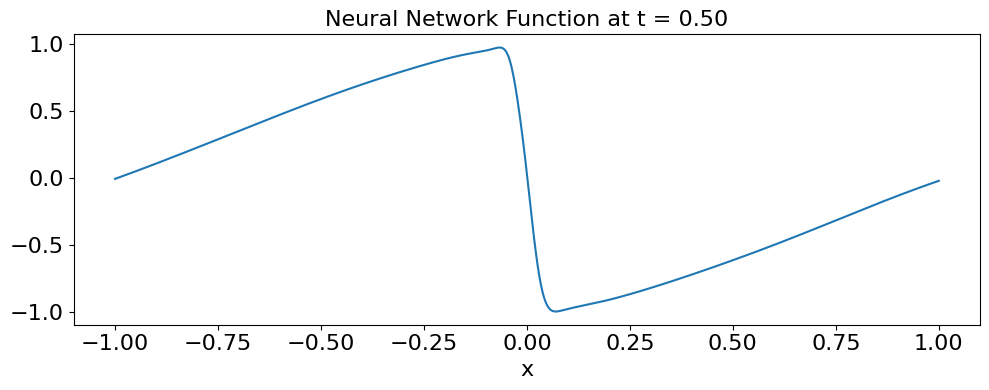

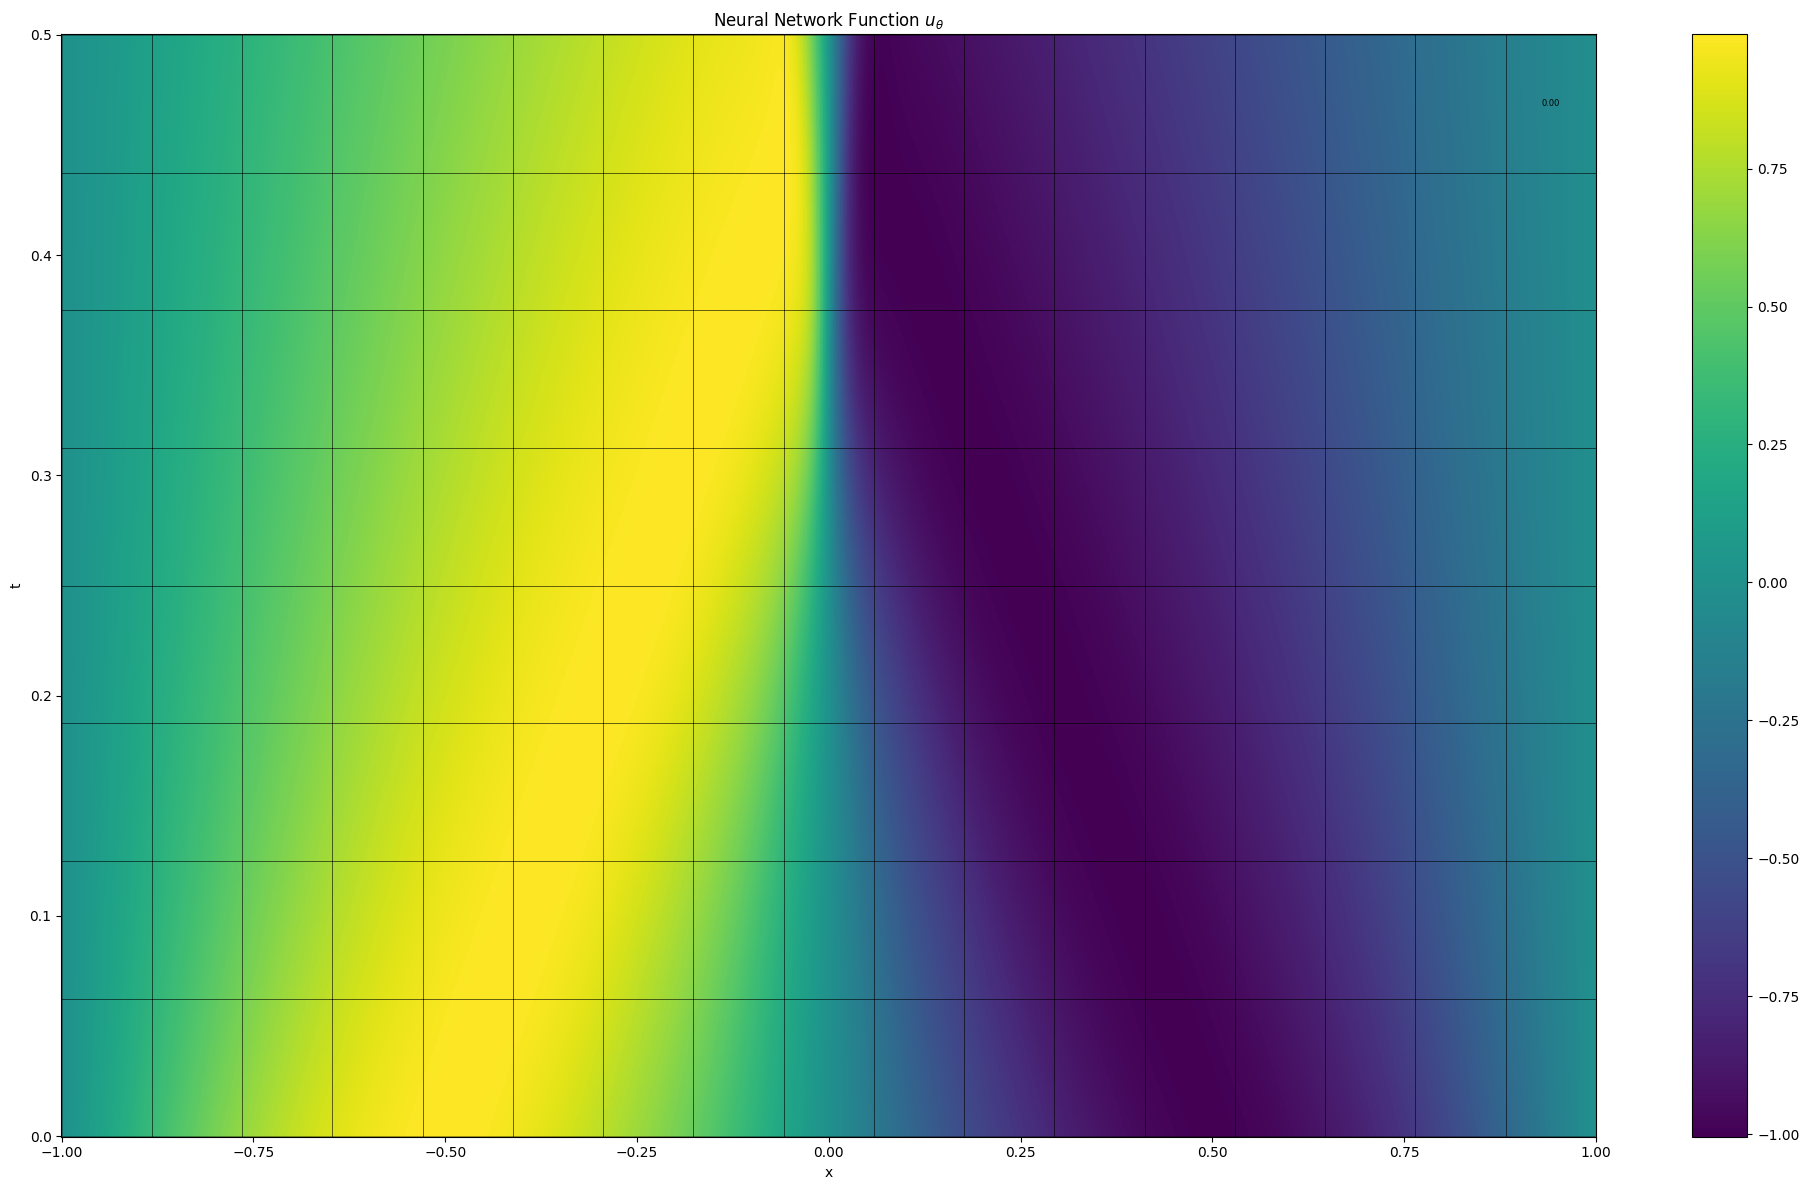

Grade 0, Iter 3100, loss_eqn: 0.024126, loss_eqn_from_kh: 0.024126, loss_l1: 0.248526, loss_ibc: 0.000053
The largest W^{1,inf} norm of k_h coeffs is 9.928002
Grade 0, Iter 3200, loss_eqn: 0.023922, loss_eqn_from_kh: 0.023922, loss_l1: 0.245158, loss_ibc: 0.000596
The largest W^{1,inf} norm of k_h coeffs is 9.965017
Grade 0, Iter 3300, loss_eqn: 0.027261, loss_eqn_from_kh: 0.027261, loss_l1: 0.245740, loss_ibc: 0.001773
The largest W^{1,inf} norm of k_h coeffs is 9.821861
Grade 0, Iter 3400, loss_eqn: 0.019314, loss_eqn_from_kh: 0.019314, loss_l1: 0.245459, loss_ibc: 0.000224
The largest W^{1,inf} norm of k_h coeffs is 9.725881
Grade 0, Iter 3500, loss_eqn: 0.016377, loss_eqn_from_kh: 0.016377, loss_l1: 0.245378, loss_ibc: 0.000307
The largest W^{1,inf} norm of k_h coeffs is 9.908993
Grade 0, Iter 3600, loss_eqn: 0.013970, loss_eqn_from_kh: 0.013970, loss_l1: 0.237800, loss_ibc: 0.000139
The largest W^{1,inf} norm of k_h coeffs is 9.971029
Grade 0, Iter 3700, loss_eqn: 0.013120, loss_e

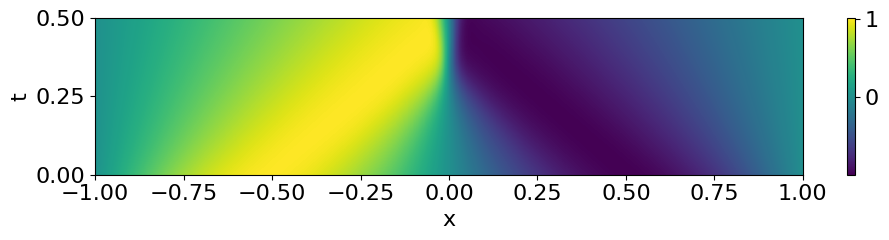

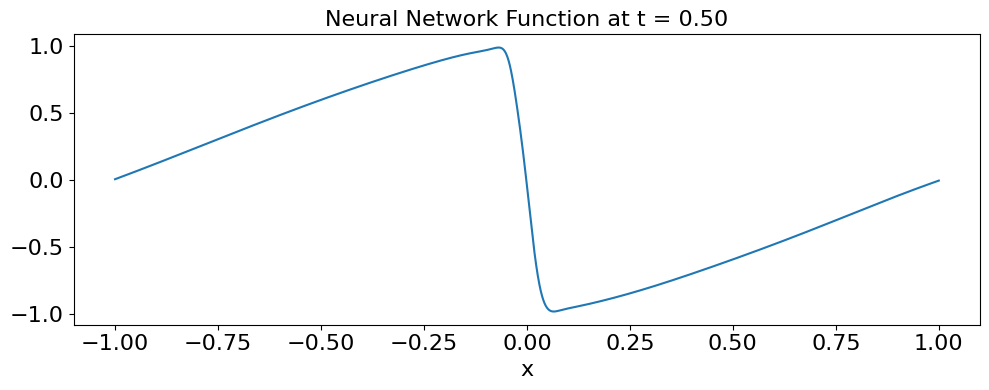

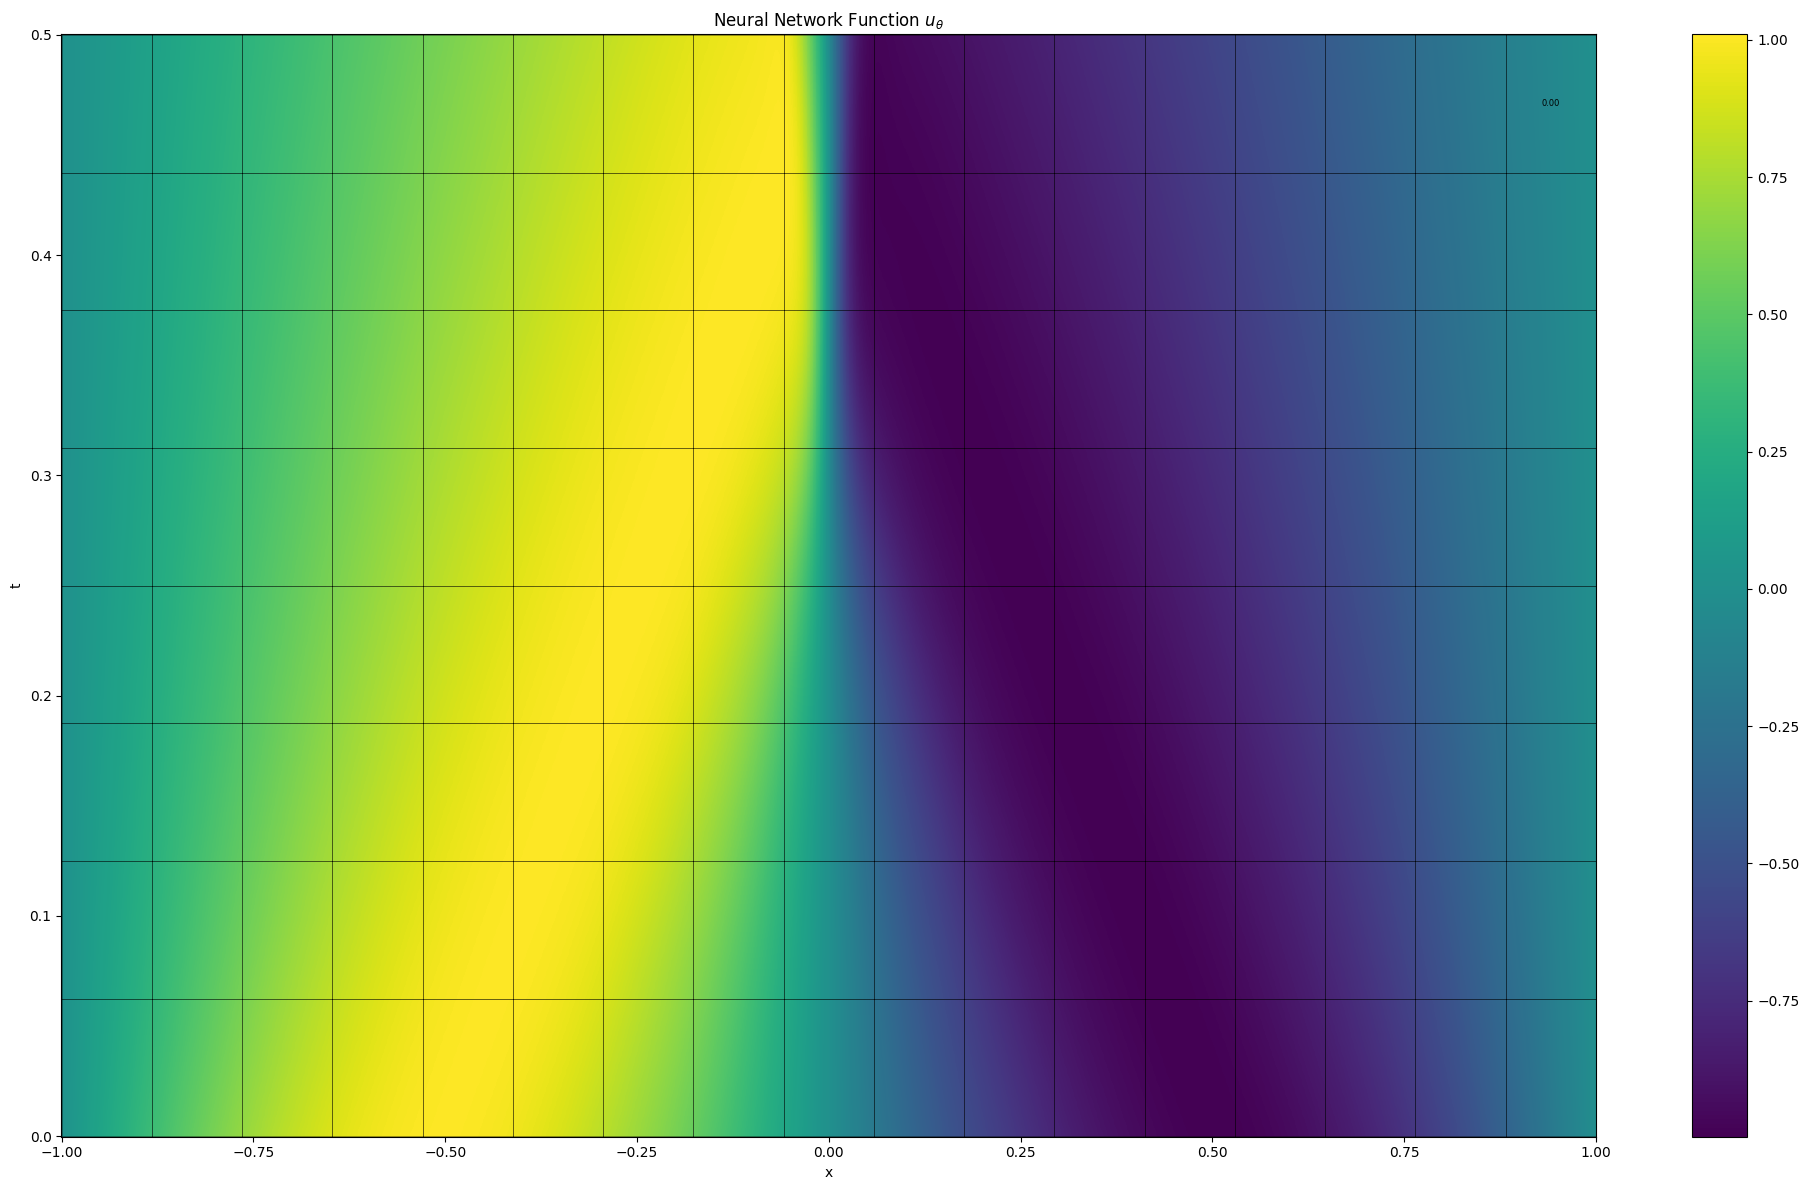

Grade 0, Iter 4100, loss_eqn: 0.027725, loss_eqn_from_kh: 0.027725, loss_l1: 0.247890, loss_ibc: 0.000129
The largest W^{1,inf} norm of k_h coeffs is 9.963158
Grade 0, Iter 4200, loss_eqn: 0.020315, loss_eqn_from_kh: 0.020315, loss_l1: 0.243753, loss_ibc: 0.000754
The largest W^{1,inf} norm of k_h coeffs is 9.790058
Grade 0, Iter 4300, loss_eqn: 0.016541, loss_eqn_from_kh: 0.016541, loss_l1: 0.240954, loss_ibc: 0.000197
The largest W^{1,inf} norm of k_h coeffs is 9.935333
Grade 0, Iter 4400, loss_eqn: 0.024954, loss_eqn_from_kh: 0.024954, loss_l1: 0.249614, loss_ibc: 0.000349
The largest W^{1,inf} norm of k_h coeffs is 9.993284
Grade 0, Iter 4500, loss_eqn: 0.030735, loss_eqn_from_kh: 0.030735, loss_l1: 0.253193, loss_ibc: 0.000203
The largest W^{1,inf} norm of k_h coeffs is 9.953332
Grade 0, Iter 4600, loss_eqn: 0.025402, loss_eqn_from_kh: 0.025402, loss_l1: 0.246869, loss_ibc: 0.000156
The largest W^{1,inf} norm of k_h coeffs is 9.941628
Grade 0, Iter 4700, loss_eqn: 0.017661, loss_e

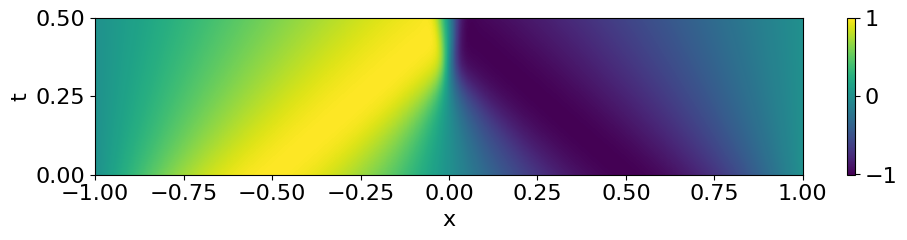

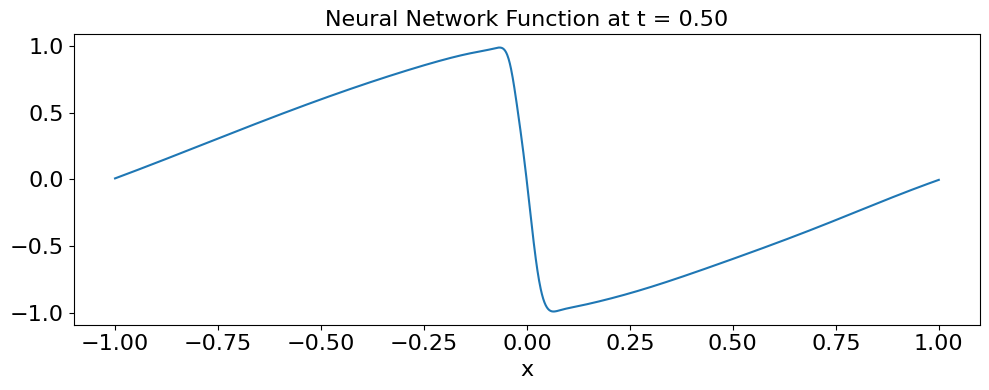

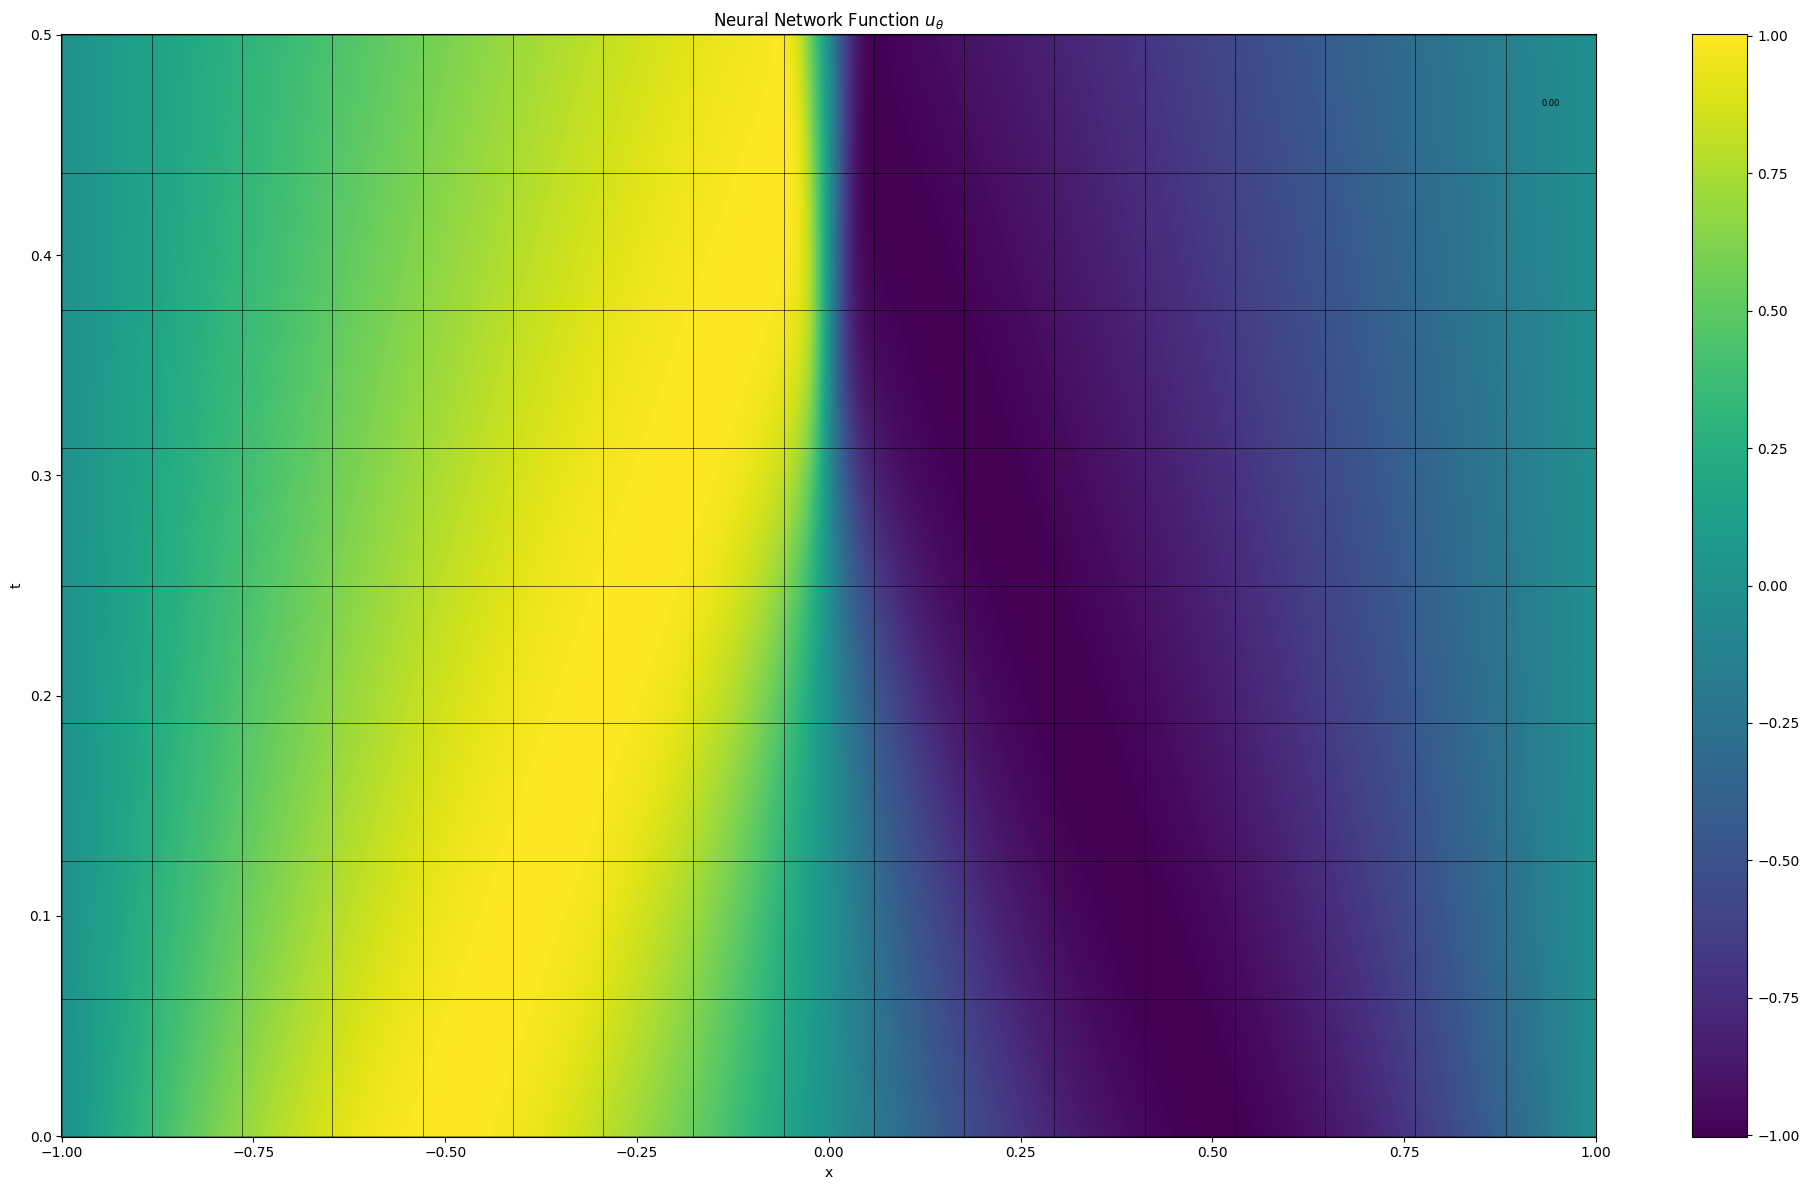

Grade 0, Iter 5100, loss_eqn: 0.013251, loss_eqn_from_kh: 0.013251, loss_l1: 0.239020, loss_ibc: 0.000044
The largest W^{1,inf} norm of k_h coeffs is 9.810414
Grade 0, Iter 5200, loss_eqn: 0.012394, loss_eqn_from_kh: 0.012394, loss_l1: 0.238330, loss_ibc: 0.000162
The largest W^{1,inf} norm of k_h coeffs is 9.997230
Grade 0, Iter 5300, loss_eqn: 0.008233, loss_eqn_from_kh: 0.008233, loss_l1: 0.235394, loss_ibc: 0.000052
The largest W^{1,inf} norm of k_h coeffs is 9.967459
Grade 0, Iter 5400, loss_eqn: 0.011256, loss_eqn_from_kh: 0.011256, loss_l1: 0.238656, loss_ibc: 0.000598
The largest W^{1,inf} norm of k_h coeffs is 9.995303
Grade 0, Iter 5500, loss_eqn: 0.021675, loss_eqn_from_kh: 0.021675, loss_l1: 0.247299, loss_ibc: 0.000190
The largest W^{1,inf} norm of k_h coeffs is 9.904688
Grade 0, Iter 5600, loss_eqn: 0.010146, loss_eqn_from_kh: 0.010146, loss_l1: 0.238365, loss_ibc: 0.000257
The largest W^{1,inf} norm of k_h coeffs is 9.861261
Grade 0, Iter 5700, loss_eqn: 0.010902, loss_e

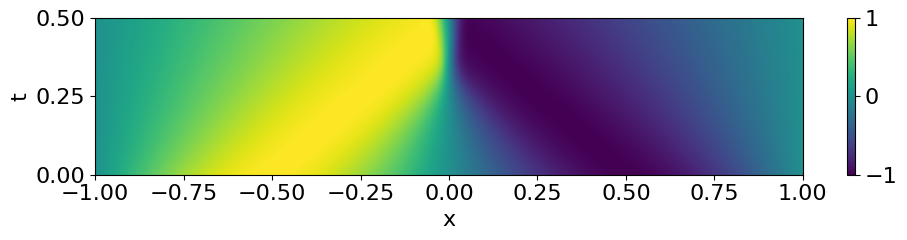

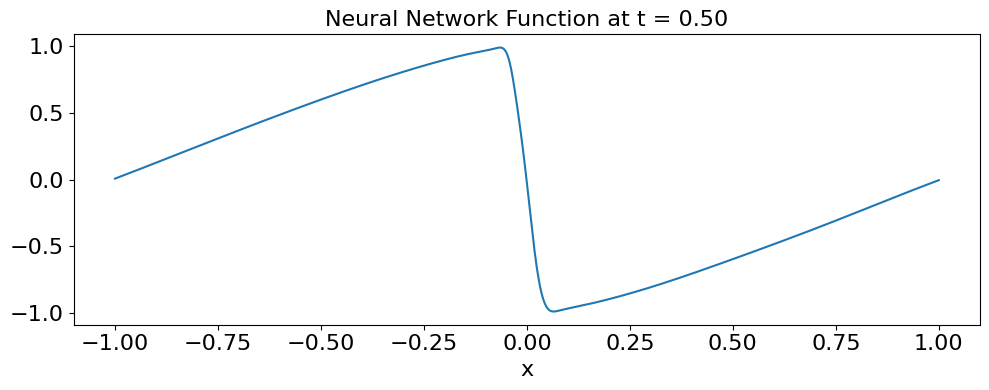

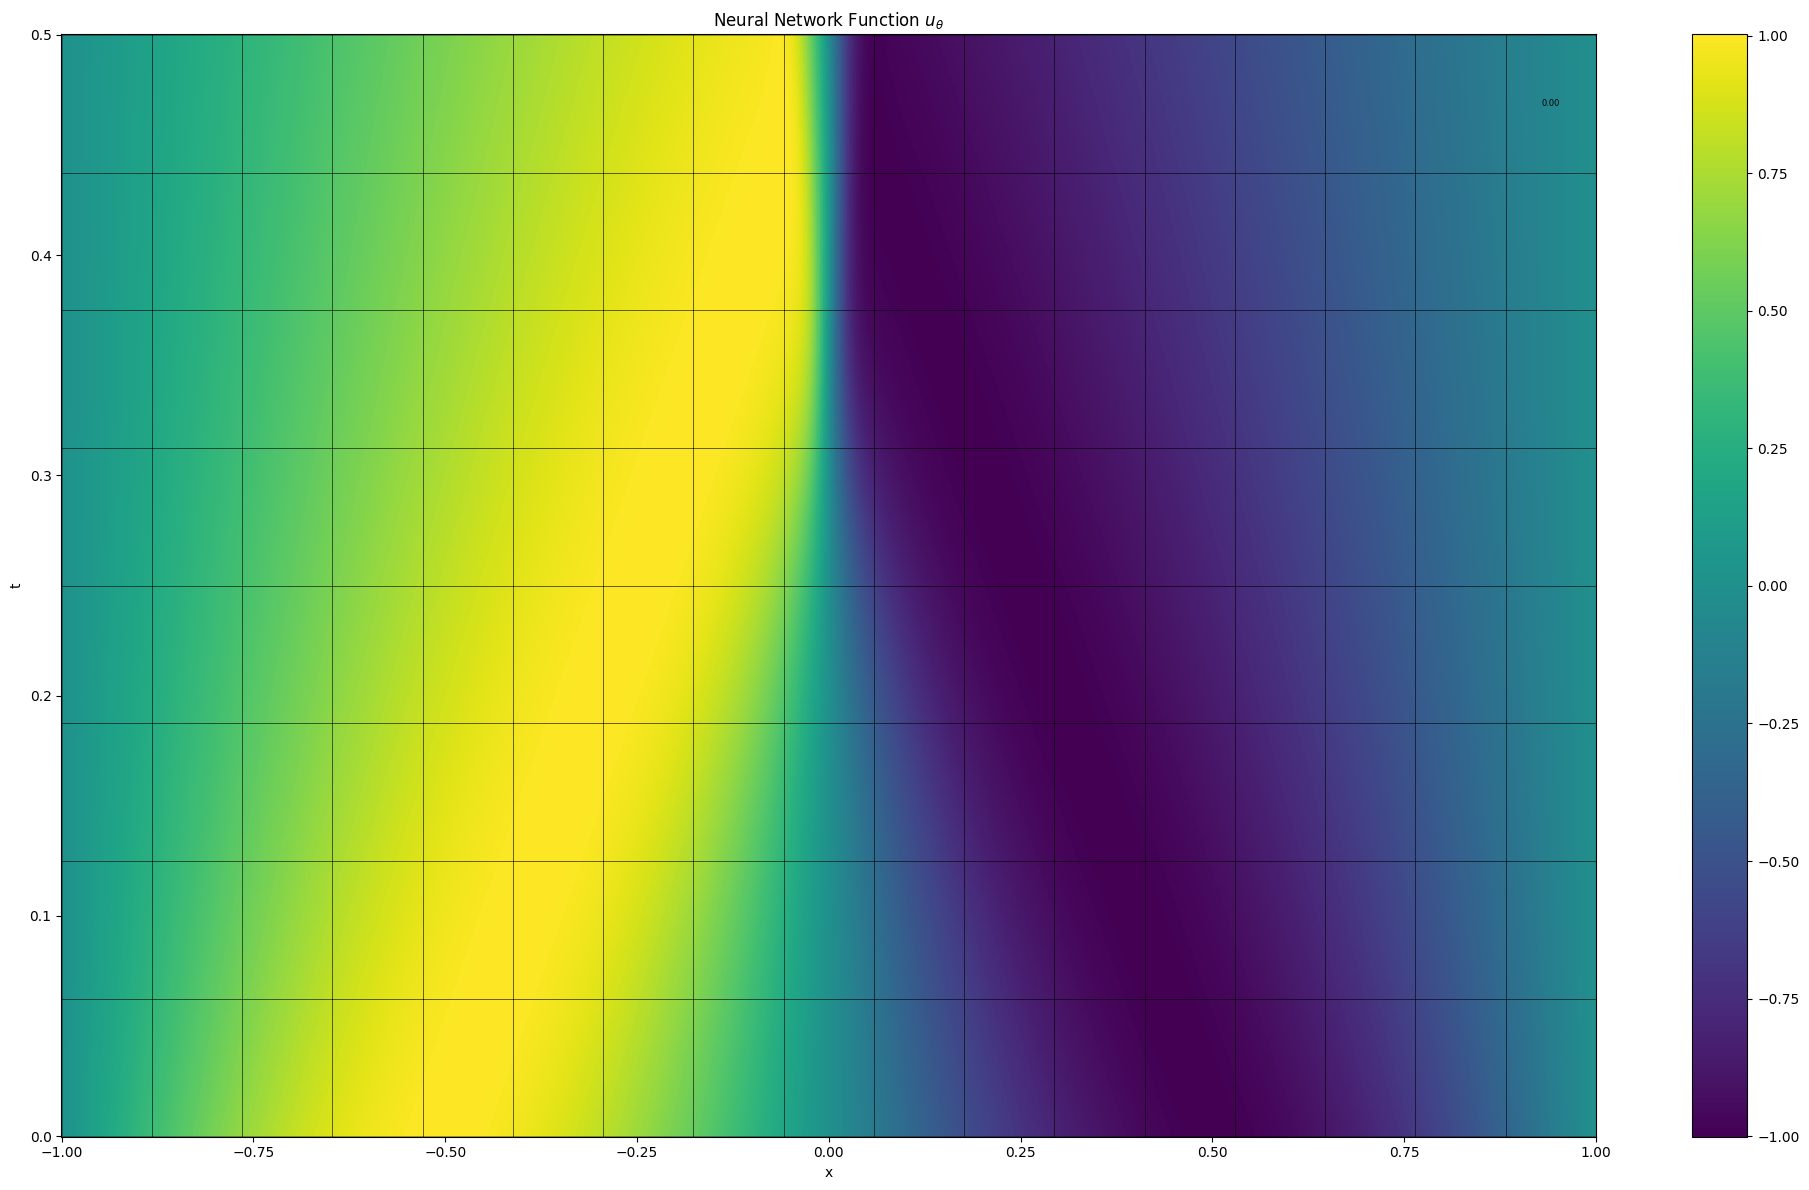

Grade 0, Iter 6100, loss_eqn: 0.008985, loss_eqn_from_kh: 0.008985, loss_l1: 0.236454, loss_ibc: 0.000026
The largest W^{1,inf} norm of k_h coeffs is 9.846270
Grade 0, Iter 6200, loss_eqn: 0.006786, loss_eqn_from_kh: 0.006786, loss_l1: 0.233920, loss_ibc: 0.000089
The largest W^{1,inf} norm of k_h coeffs is 9.987650
Grade 0, Iter 6300, loss_eqn: 0.011378, loss_eqn_from_kh: 0.011378, loss_l1: 0.239688, loss_ibc: 0.000244
The largest W^{1,inf} norm of k_h coeffs is 9.994820
Grade 0, Iter 6400, loss_eqn: 0.010951, loss_eqn_from_kh: 0.010951, loss_l1: 0.236877, loss_ibc: 0.000094
The largest W^{1,inf} norm of k_h coeffs is 9.942835
Grade 0, Iter 6500, loss_eqn: 0.007459, loss_eqn_from_kh: 0.007459, loss_l1: 0.235094, loss_ibc: 0.000116
The largest W^{1,inf} norm of k_h coeffs is 9.995090
Grade 0, Iter 6600, loss_eqn: 0.006289, loss_eqn_from_kh: 0.006289, loss_l1: 0.234359, loss_ibc: 0.000015
The largest W^{1,inf} norm of k_h coeffs is 9.985703
Grade 0, Iter 6700, loss_eqn: 0.012327, loss_e

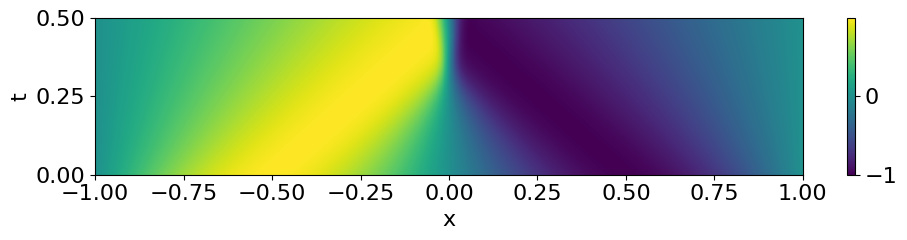

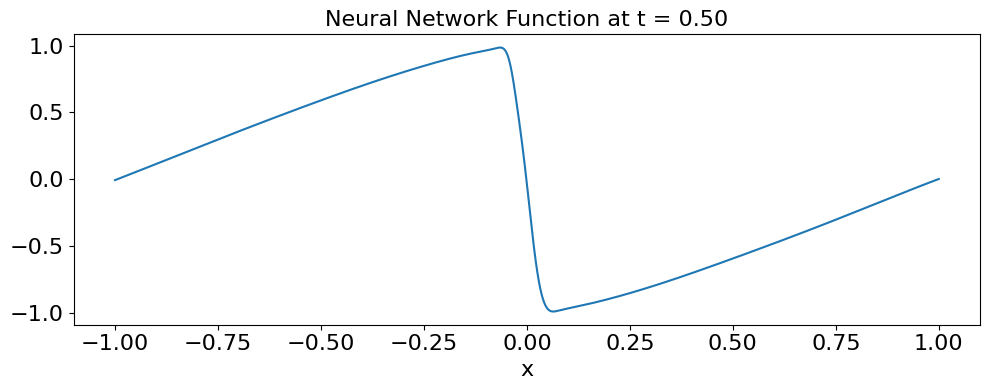

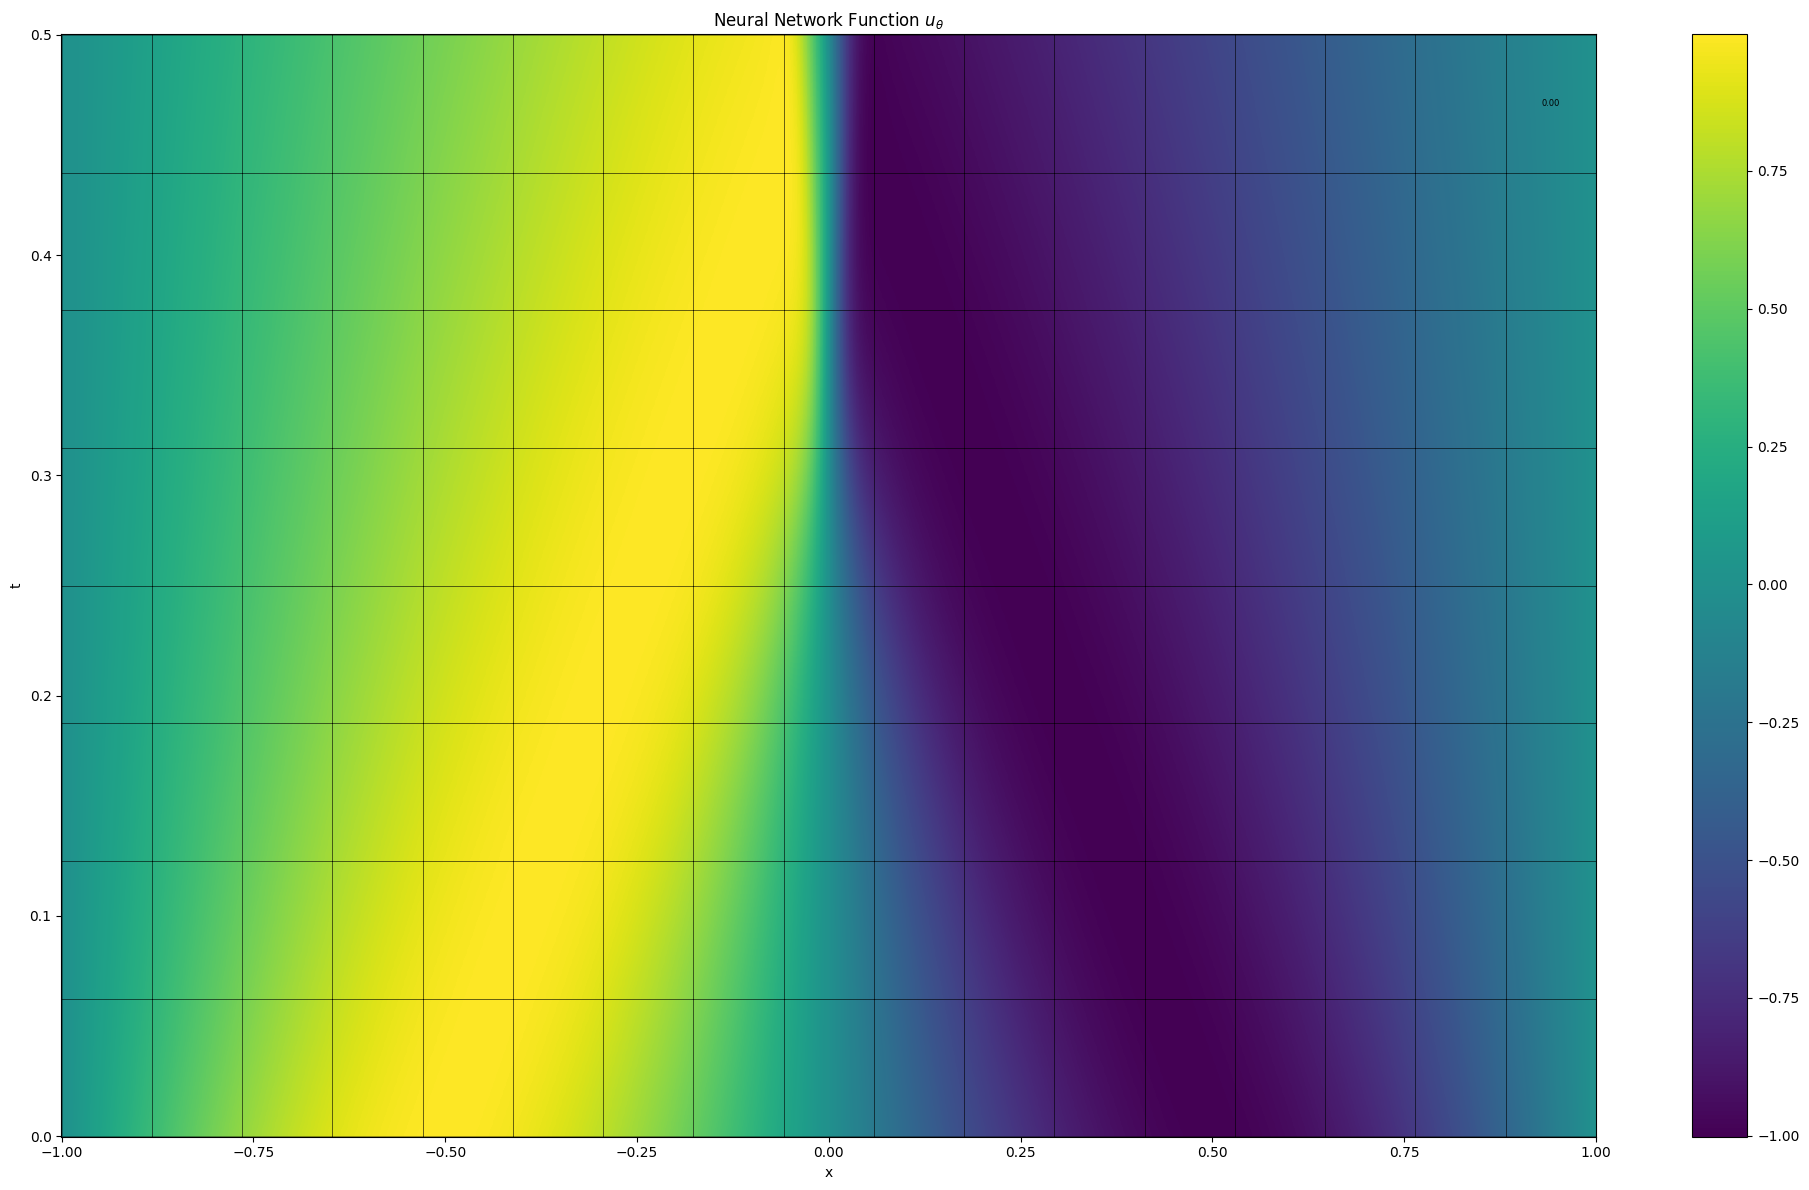

Grade 0, Iter 7100, loss_eqn: 0.005764, loss_eqn_from_kh: 0.005764, loss_l1: 0.235386, loss_ibc: 0.000008
The largest W^{1,inf} norm of k_h coeffs is 9.985102
Grade 0, Iter 7200, loss_eqn: 0.005299, loss_eqn_from_kh: 0.005299, loss_l1: 0.235145, loss_ibc: 0.000012
The largest W^{1,inf} norm of k_h coeffs is 9.968918
Grade 0, Iter 7300, loss_eqn: 0.005206, loss_eqn_from_kh: 0.005206, loss_l1: 0.235324, loss_ibc: 0.000019
The largest W^{1,inf} norm of k_h coeffs is 9.992865
Grade 0, Iter 7400, loss_eqn: 0.005870, loss_eqn_from_kh: 0.005870, loss_l1: 0.235583, loss_ibc: 0.000013
The largest W^{1,inf} norm of k_h coeffs is 9.985712
Grade 0, Iter 7500, loss_eqn: 0.004601, loss_eqn_from_kh: 0.004601, loss_l1: 0.234702, loss_ibc: 0.000020
The largest W^{1,inf} norm of k_h coeffs is 9.967110
Grade 0, Iter 7600, loss_eqn: 0.005902, loss_eqn_from_kh: 0.005902, loss_l1: 0.235347, loss_ibc: 0.000017
The largest W^{1,inf} norm of k_h coeffs is 9.840595
Grade 0, Iter 7700, loss_eqn: 0.005287, loss_e

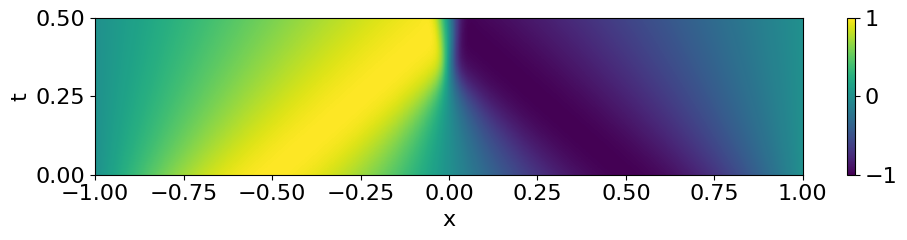

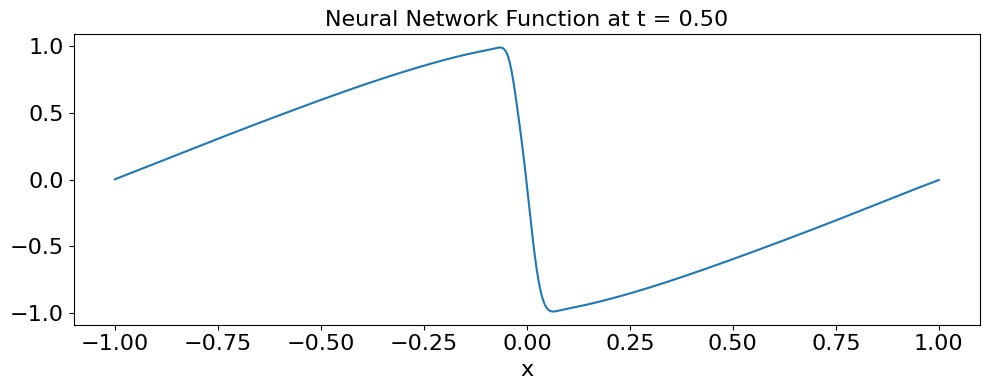

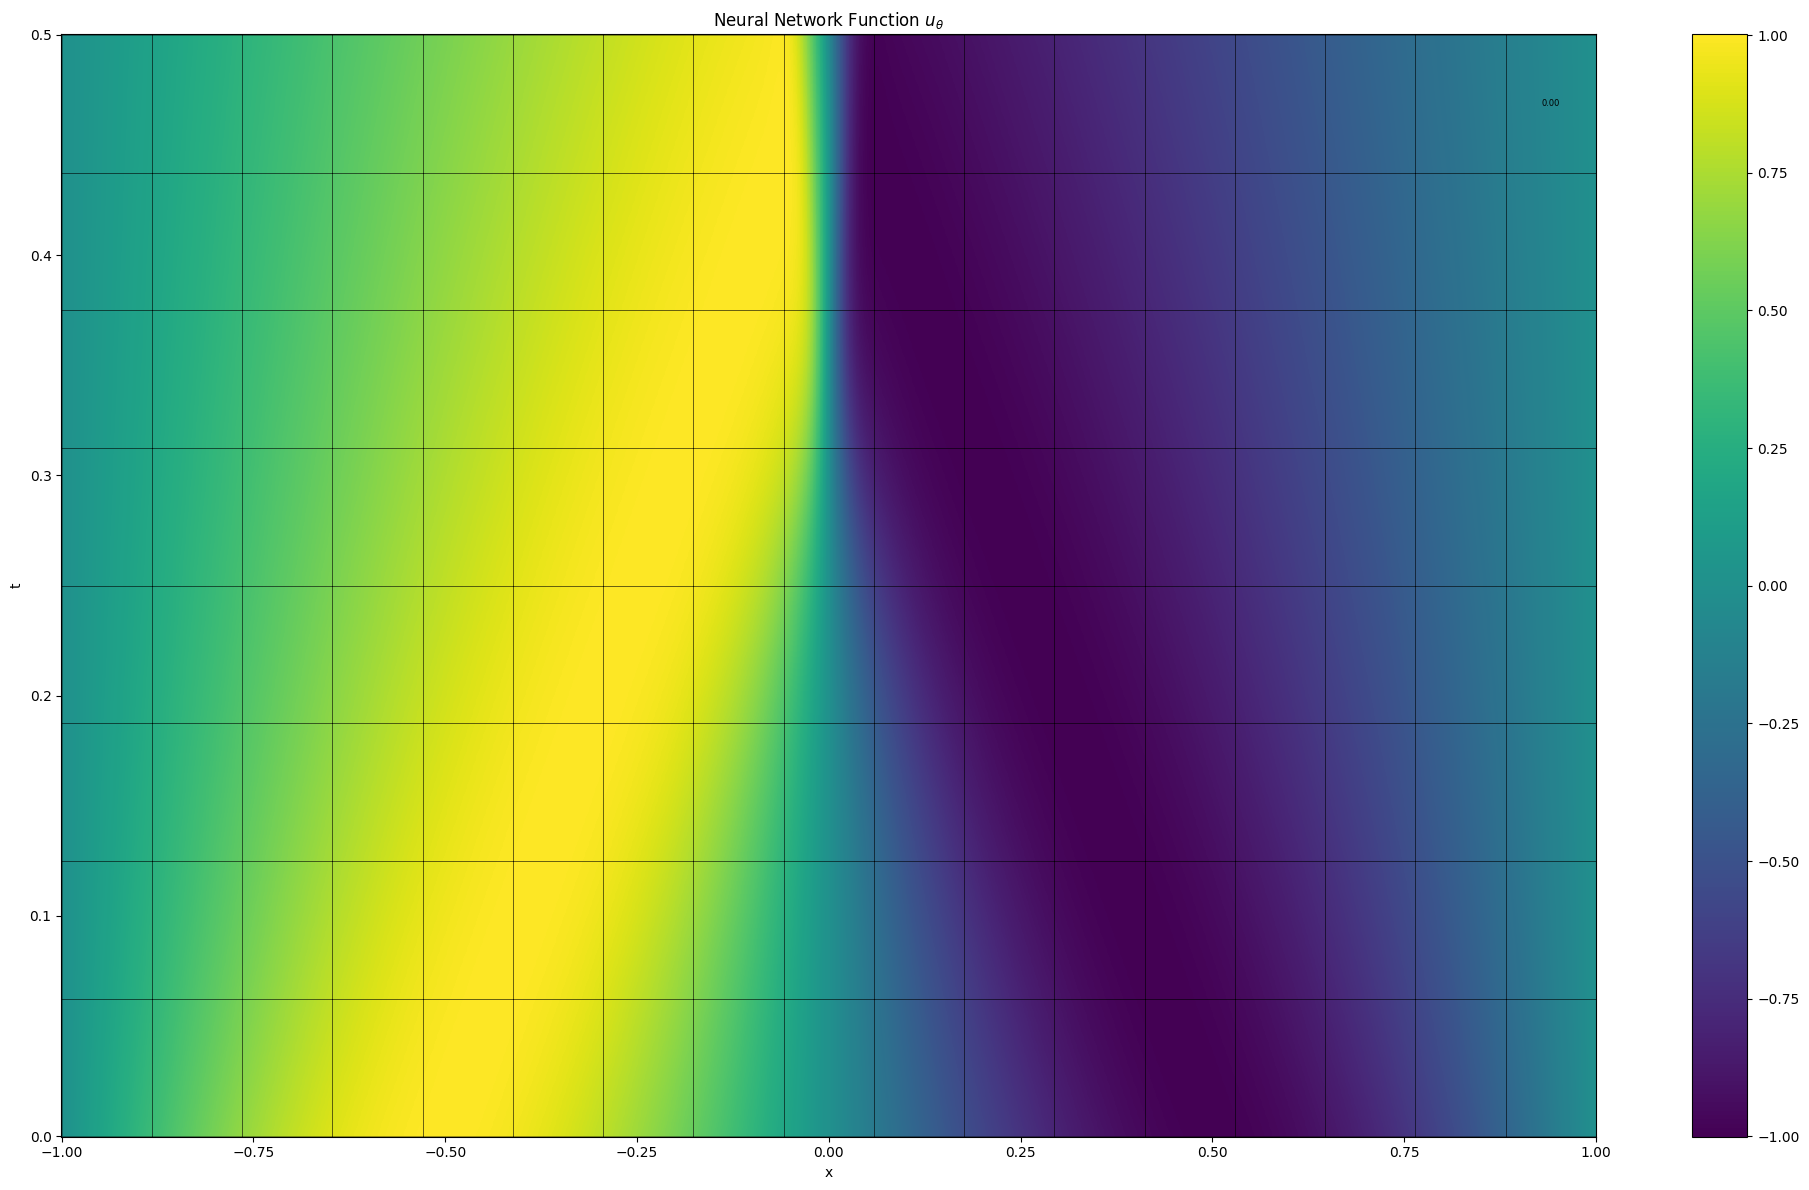

Grade 0, Iter 8100, loss_eqn: 0.003396, loss_eqn_from_kh: 0.003396, loss_l1: 0.234623, loss_ibc: 0.000008
The largest W^{1,inf} norm of k_h coeffs is 9.991835
Grade 0, Iter 8200, loss_eqn: 0.003584, loss_eqn_from_kh: 0.003584, loss_l1: 0.234637, loss_ibc: 0.000003
The largest W^{1,inf} norm of k_h coeffs is 9.967052
Grade 0, Iter 8300, loss_eqn: 0.002988, loss_eqn_from_kh: 0.002988, loss_l1: 0.234362, loss_ibc: 0.000004
The largest W^{1,inf} norm of k_h coeffs is 9.990463
Grade 0, Iter 8400, loss_eqn: 0.003053, loss_eqn_from_kh: 0.003053, loss_l1: 0.234434, loss_ibc: 0.000002
The largest W^{1,inf} norm of k_h coeffs is 9.975508
Grade 0, Iter 8500, loss_eqn: 0.002537, loss_eqn_from_kh: 0.002537, loss_l1: 0.234348, loss_ibc: 0.000001
The largest W^{1,inf} norm of k_h coeffs is 9.972097
Grade 0, Iter 8600, loss_eqn: 0.002423, loss_eqn_from_kh: 0.002423, loss_l1: 0.234062, loss_ibc: 0.000001
The largest W^{1,inf} norm of k_h coeffs is 9.998215
Grade 0, Iter 8700, loss_eqn: 0.002526, loss_e

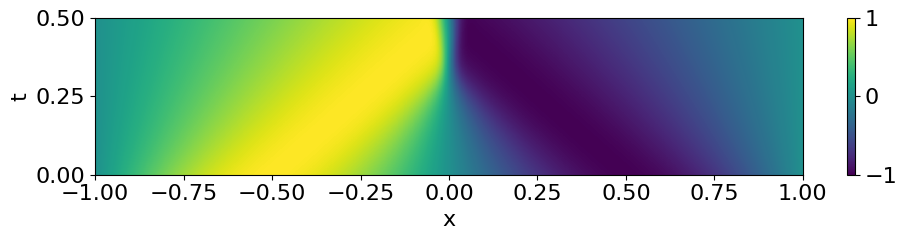

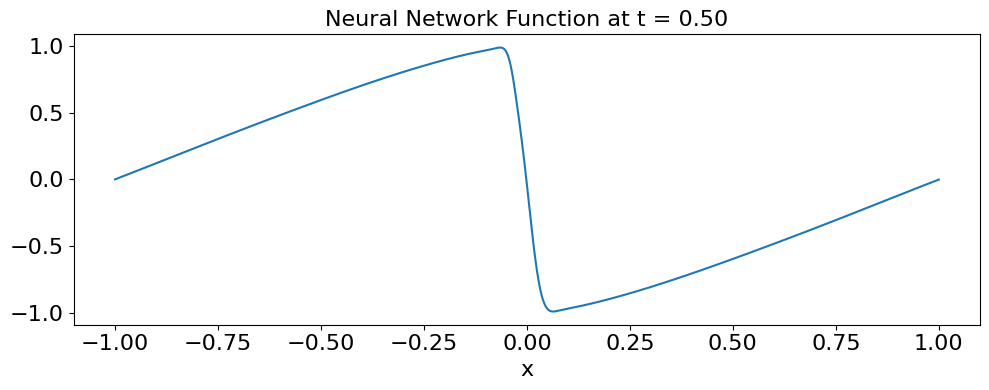

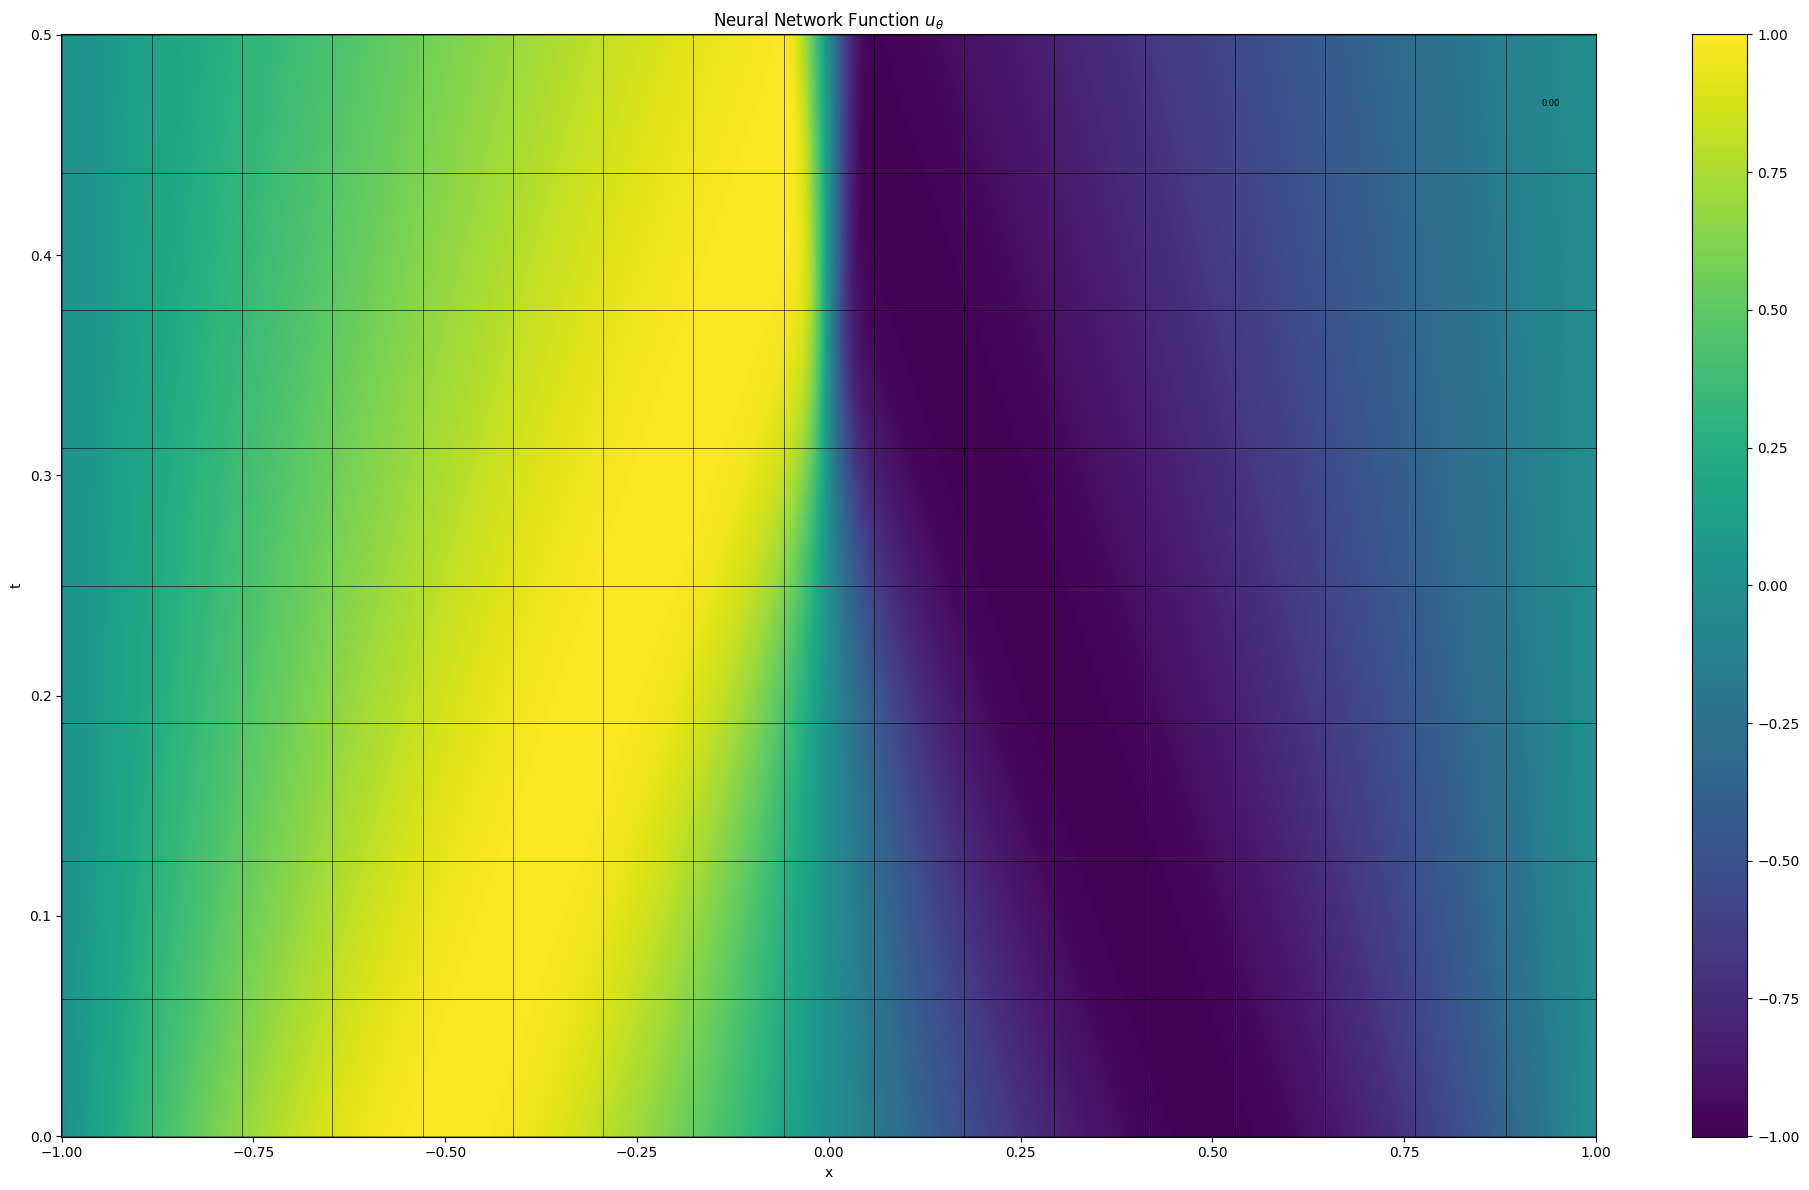

Grade 0, Iter 9100, loss_eqn: 0.002193, loss_eqn_from_kh: 0.002193, loss_l1: 0.234459, loss_ibc: 0.000001
The largest W^{1,inf} norm of k_h coeffs is 9.994068
Grade 0, Iter 9200, loss_eqn: 0.002126, loss_eqn_from_kh: 0.002126, loss_l1: 0.234406, loss_ibc: 0.000001
The largest W^{1,inf} norm of k_h coeffs is 9.998970
Grade 0, Iter 9300, loss_eqn: 0.001961, loss_eqn_from_kh: 0.001961, loss_l1: 0.234459, loss_ibc: 0.000001
The largest W^{1,inf} norm of k_h coeffs is 9.986923
Grade 0, Iter 9400, loss_eqn: 0.002226, loss_eqn_from_kh: 0.002226, loss_l1: 0.234410, loss_ibc: 0.000001
The largest W^{1,inf} norm of k_h coeffs is 9.979069
Grade 0, Iter 9500, loss_eqn: 0.002071, loss_eqn_from_kh: 0.002071, loss_l1: 0.234502, loss_ibc: 0.000001
The largest W^{1,inf} norm of k_h coeffs is 9.993591
Grade 0, Iter 9600, loss_eqn: 0.001991, loss_eqn_from_kh: 0.001991, loss_l1: 0.234519, loss_ibc: 0.000001
The largest W^{1,inf} norm of k_h coeffs is 9.987162
Grade 0, Iter 9700, loss_eqn: 0.002038, loss_e

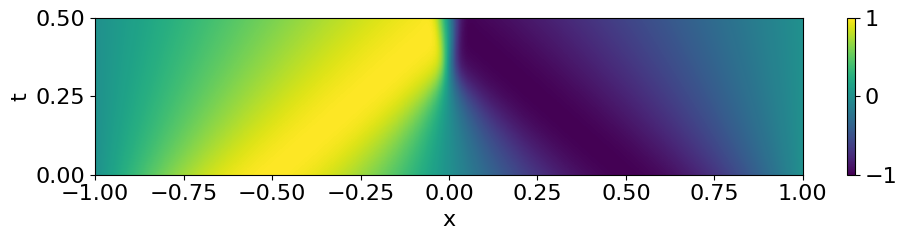

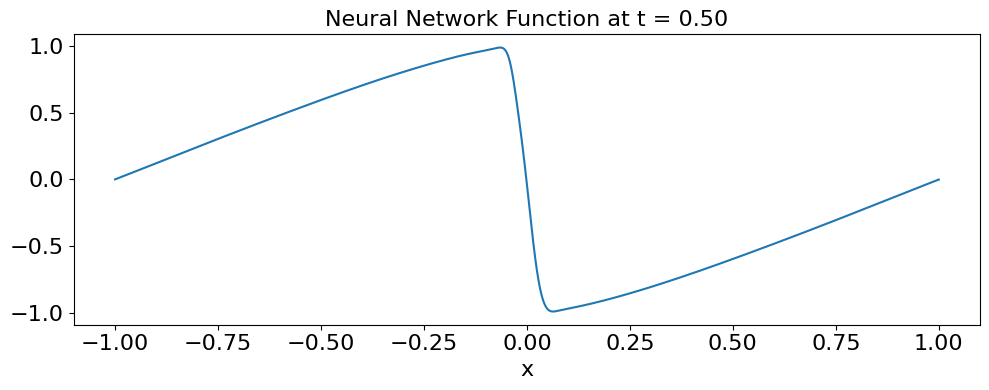

Adding grade 1 with hidden dims [64, 64, 64, 64, 64]

Plotting before training segment [0.5000, 1.0000]


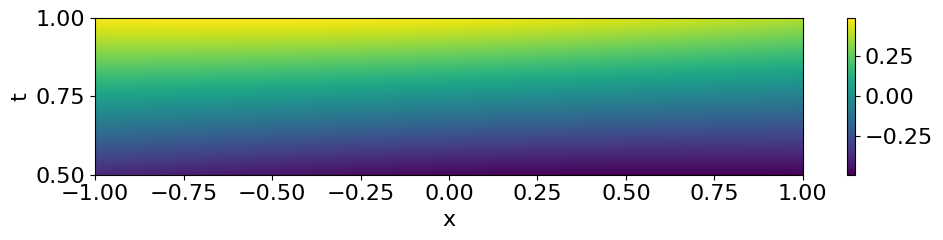

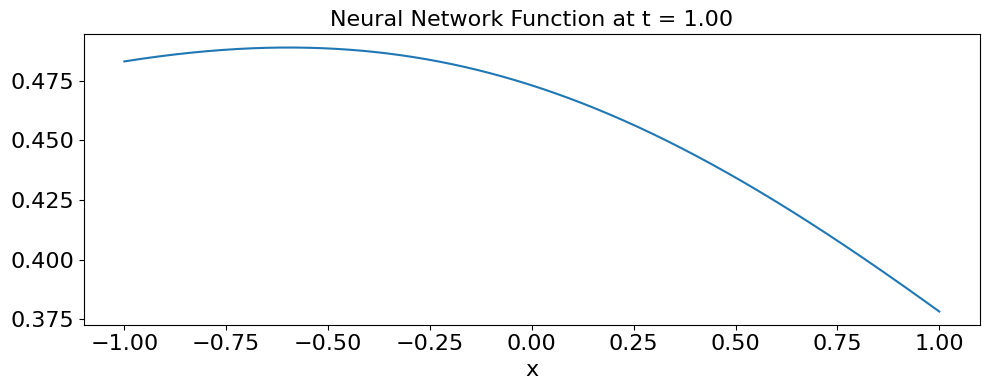


Training segment [0.5000, 1.0000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
The largest W^{1,inf} norm of k_h coeffs is 6.352427
Grade 0, Iter 0, lambda_ic: 9.611313, lambda_bc: 9.955682, lambda_eqn: 1.036653
Grade 0, Iter 0, loss_eqn: 1.831929, loss_eqn_from_kh: 1.831928, loss_l1: 1.831928, loss_ibc: 0.712568
The largest W^{1,inf} norm of k_h coeffs is 7.918732


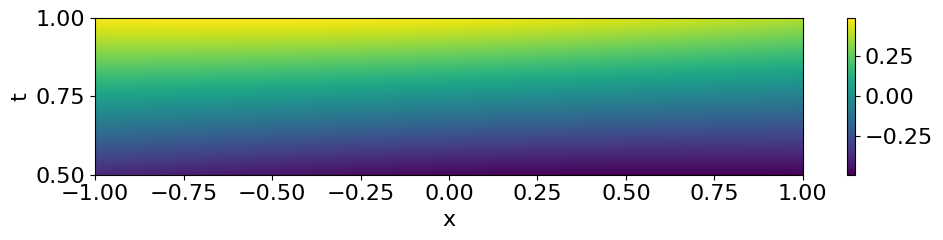

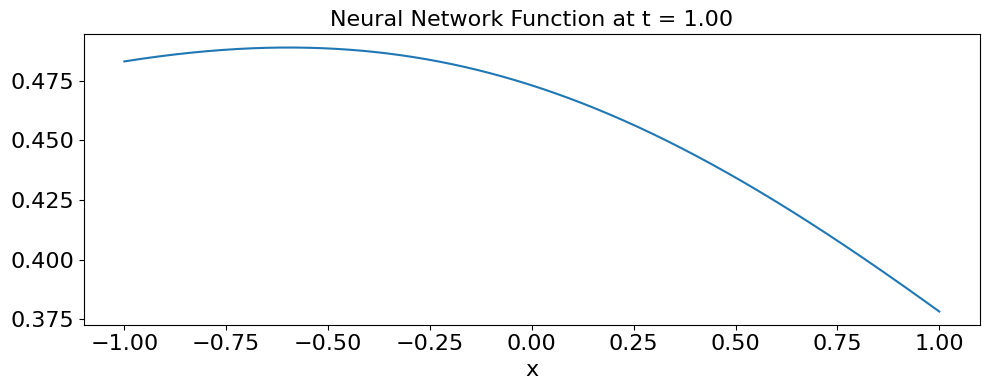

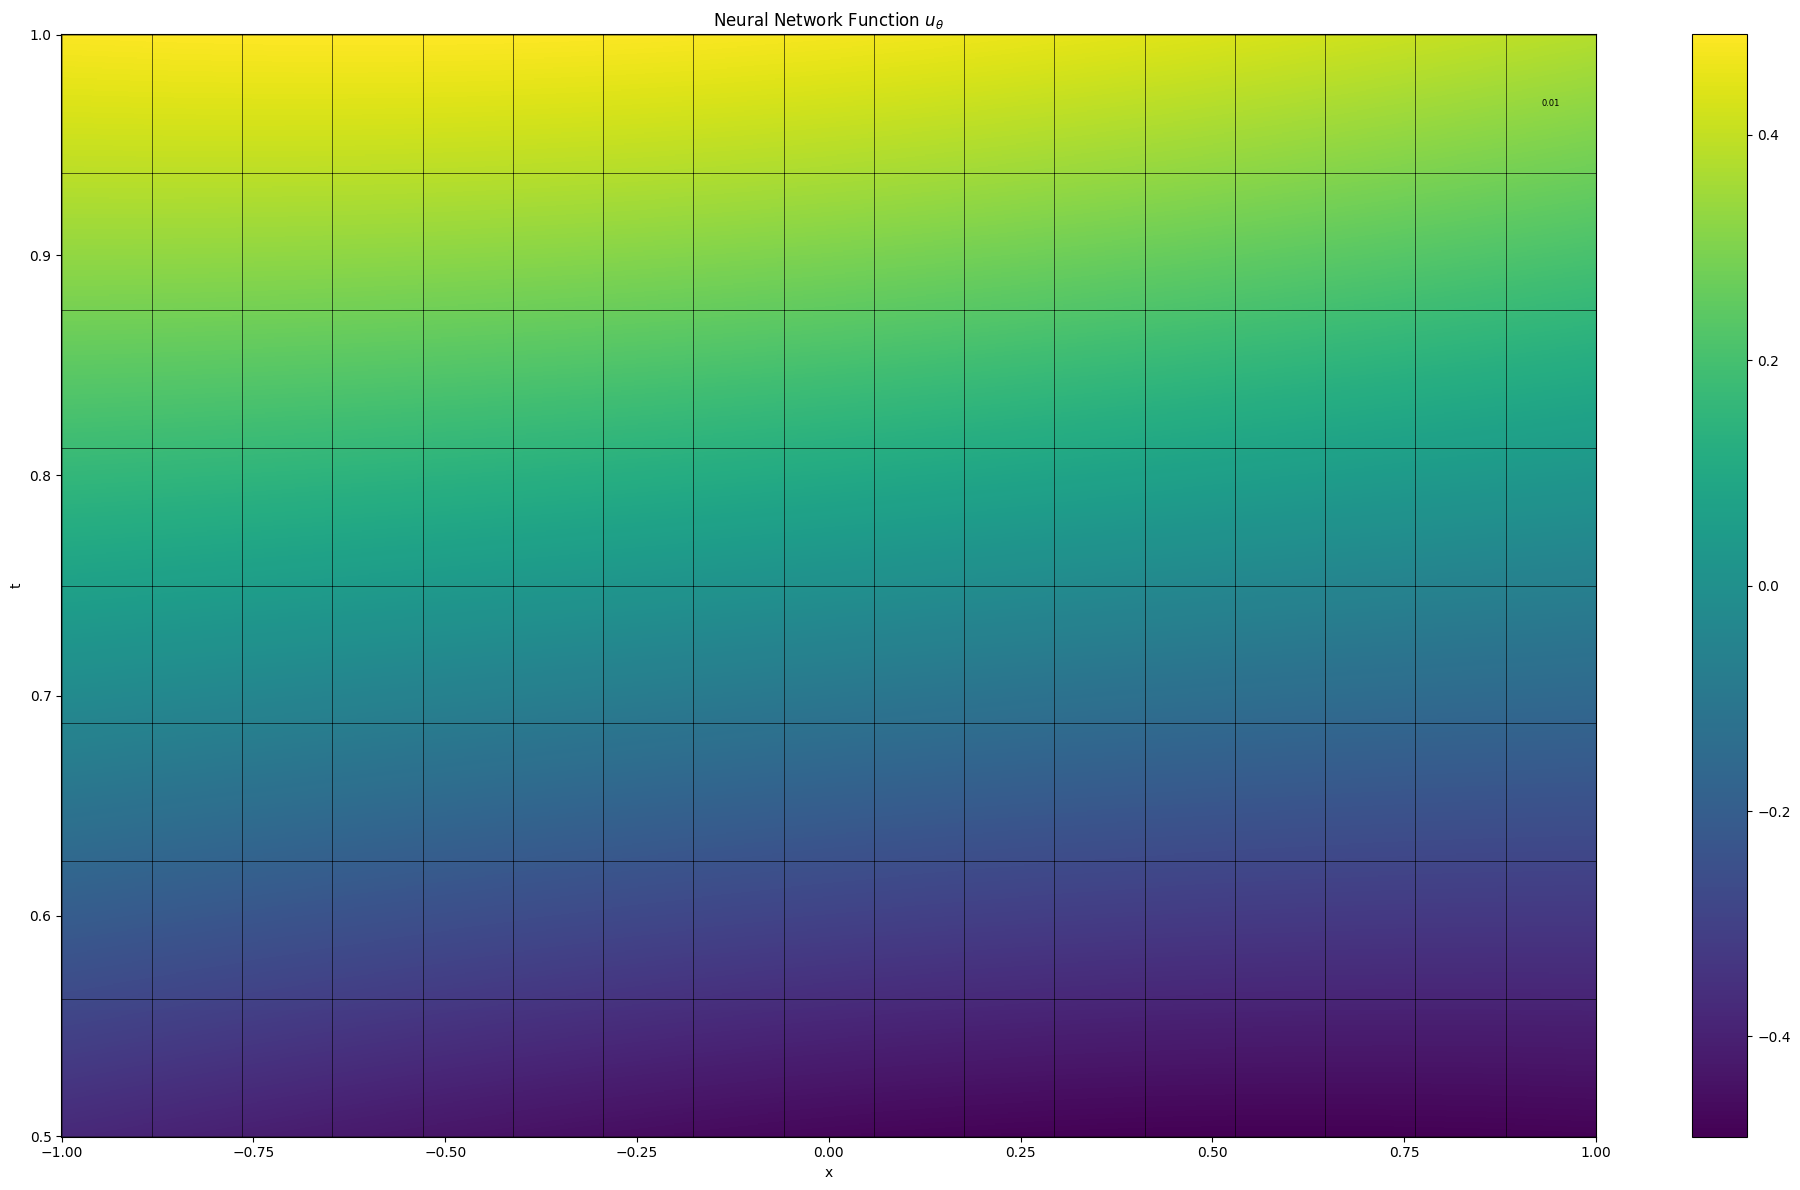

Grade 0, Iter 100, loss_eqn: 0.013538, loss_eqn_from_kh: 0.013538, loss_l1: 0.013538, loss_ibc: 0.366027
The largest W^{1,inf} norm of k_h coeffs is 9.939835
Grade 0, Iter 200, loss_eqn: 0.480982, loss_eqn_from_kh: 0.480982, loss_l1: 0.481698, loss_ibc: 0.041857
The largest W^{1,inf} norm of k_h coeffs is 9.946375
Grade 0, Iter 300, loss_eqn: 0.218120, loss_eqn_from_kh: 0.218120, loss_l1: 0.428184, loss_ibc: 0.008978
The largest W^{1,inf} norm of k_h coeffs is 9.892516
Grade 0, Iter 400, loss_eqn: 0.092236, loss_eqn_from_kh: 0.092236, loss_l1: 0.511998, loss_ibc: 0.001876
The largest W^{1,inf} norm of k_h coeffs is 9.987822
Grade 0, Iter 500, loss_eqn: 0.071177, loss_eqn_from_kh: 0.071177, loss_l1: 0.518507, loss_ibc: 0.001122
The largest W^{1,inf} norm of k_h coeffs is 9.946653
Grade 0, Iter 600, loss_eqn: 0.050586, loss_eqn_from_kh: 0.050586, loss_l1: 0.520061, loss_ibc: 0.000781
The largest W^{1,inf} norm of k_h coeffs is 9.985922
Grade 0, Iter 700, loss_eqn: 0.073424, loss_eqn_from

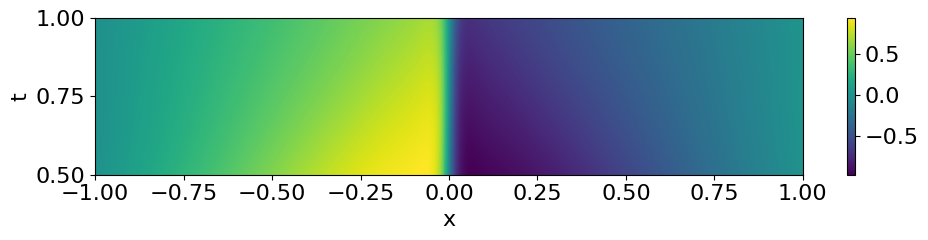

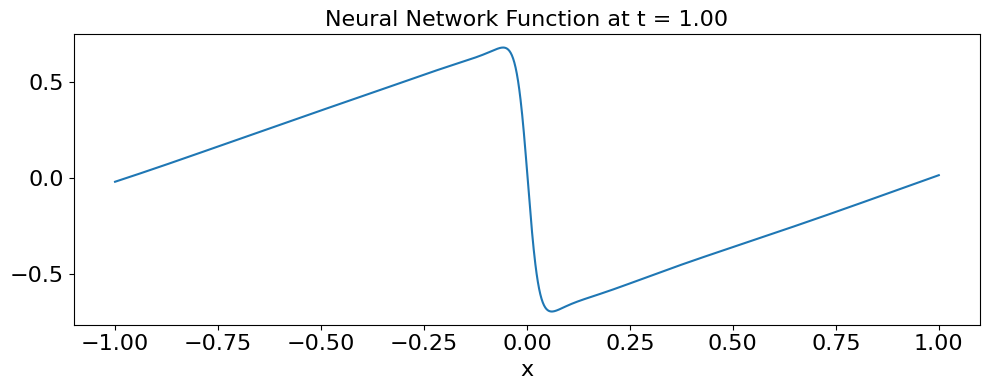

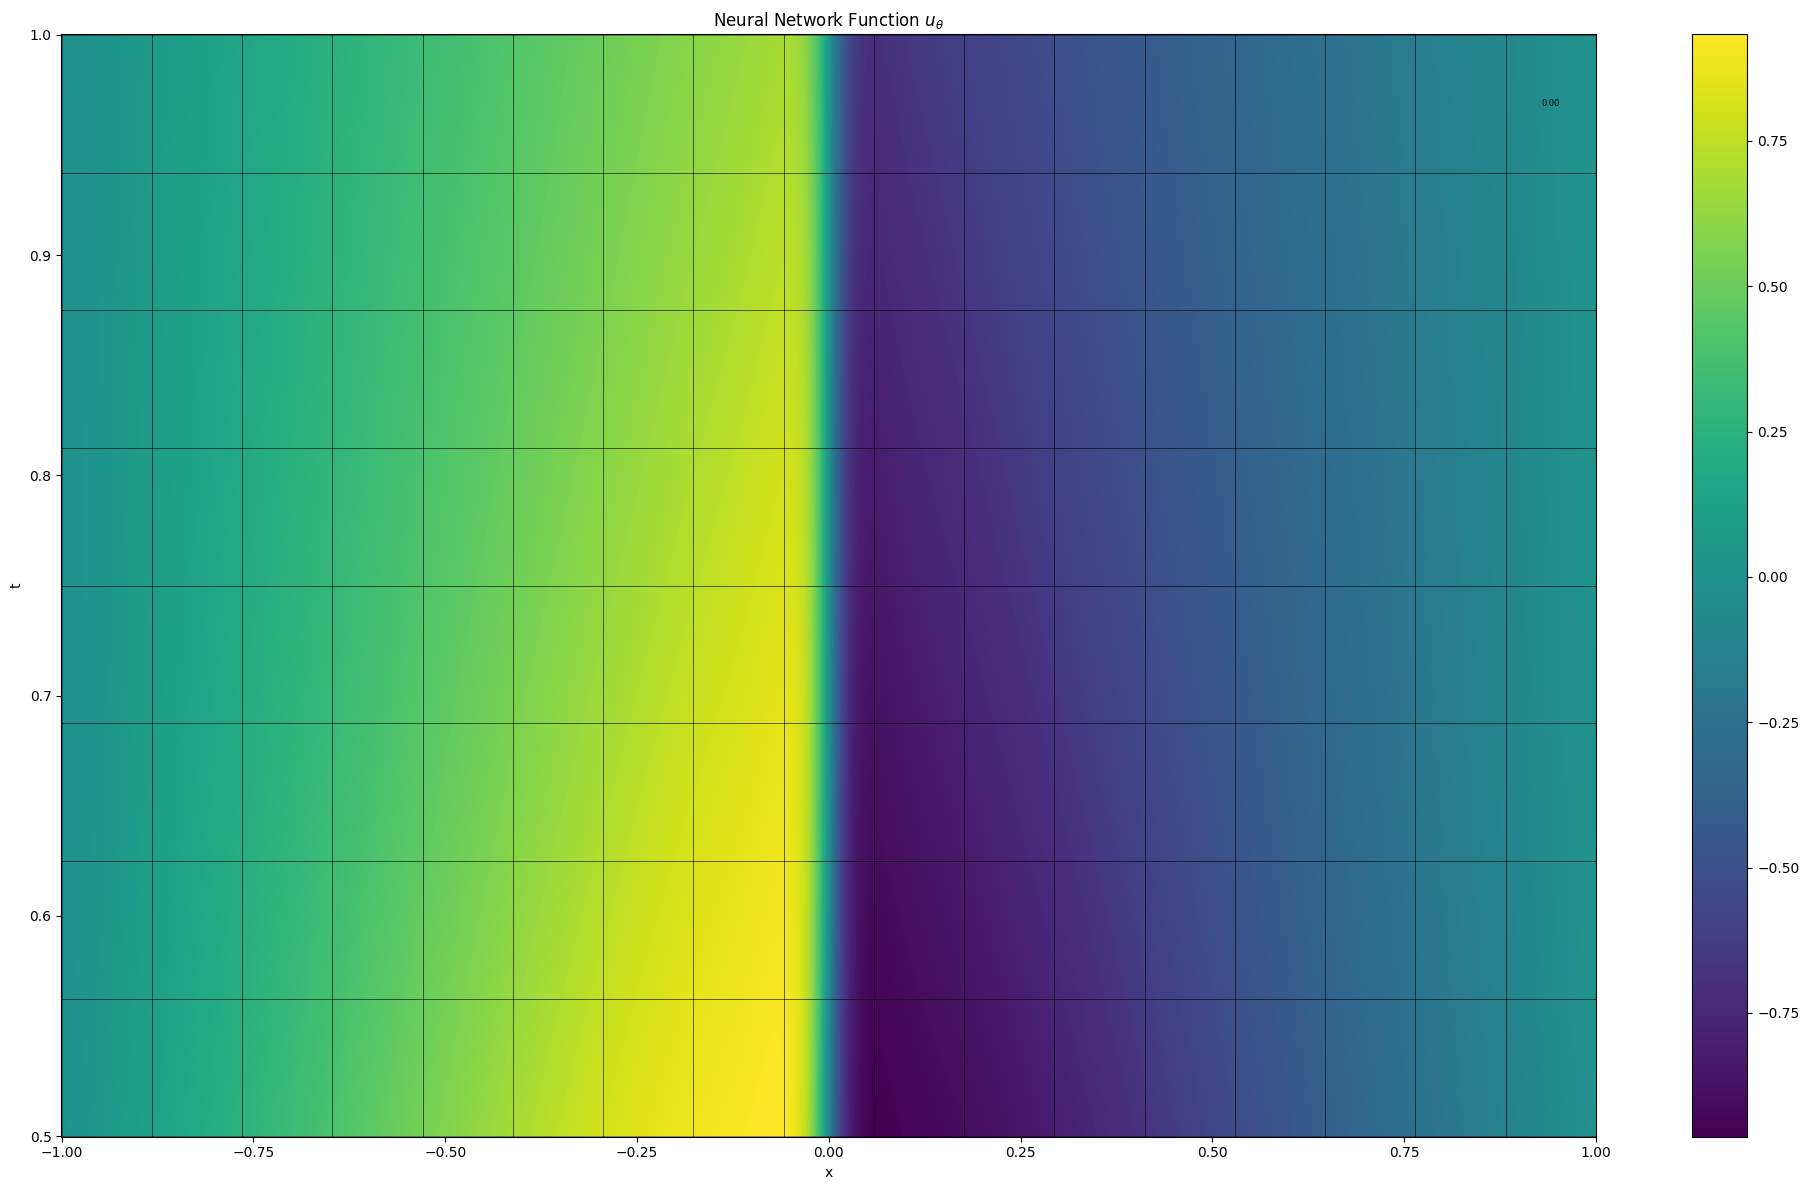

Grade 0, Iter 1100, loss_eqn: 0.034754, loss_eqn_from_kh: 0.034754, loss_l1: 0.517700, loss_ibc: 0.002122
The largest W^{1,inf} norm of k_h coeffs is 9.979806
Grade 0, Iter 1200, loss_eqn: 0.035421, loss_eqn_from_kh: 0.035421, loss_l1: 0.505947, loss_ibc: 0.000462
The largest W^{1,inf} norm of k_h coeffs is 9.922538
Grade 0, Iter 1300, loss_eqn: 0.028875, loss_eqn_from_kh: 0.028875, loss_l1: 0.499295, loss_ibc: 0.001052
The largest W^{1,inf} norm of k_h coeffs is 9.958971
Grade 0, Iter 1400, loss_eqn: 0.044612, loss_eqn_from_kh: 0.044612, loss_l1: 0.511278, loss_ibc: 0.000500
The largest W^{1,inf} norm of k_h coeffs is 9.960220
Grade 0, Iter 1500, loss_eqn: 0.041327, loss_eqn_from_kh: 0.041327, loss_l1: 0.496481, loss_ibc: 0.001000
The largest W^{1,inf} norm of k_h coeffs is 9.906588
Grade 0, Iter 1600, loss_eqn: 0.040945, loss_eqn_from_kh: 0.040945, loss_l1: 0.502976, loss_ibc: 0.001074
The largest W^{1,inf} norm of k_h coeffs is 9.991076
Grade 0, Iter 1700, loss_eqn: 0.050402, loss_e

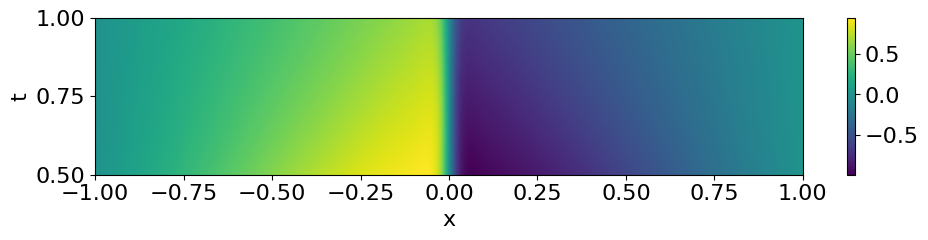

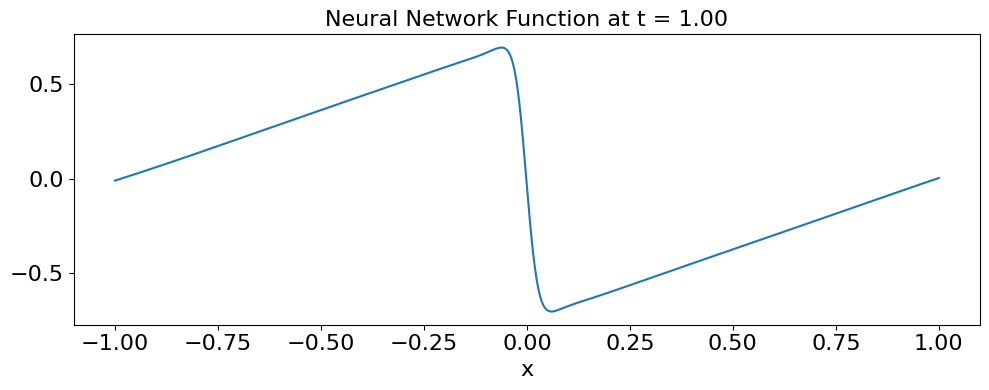

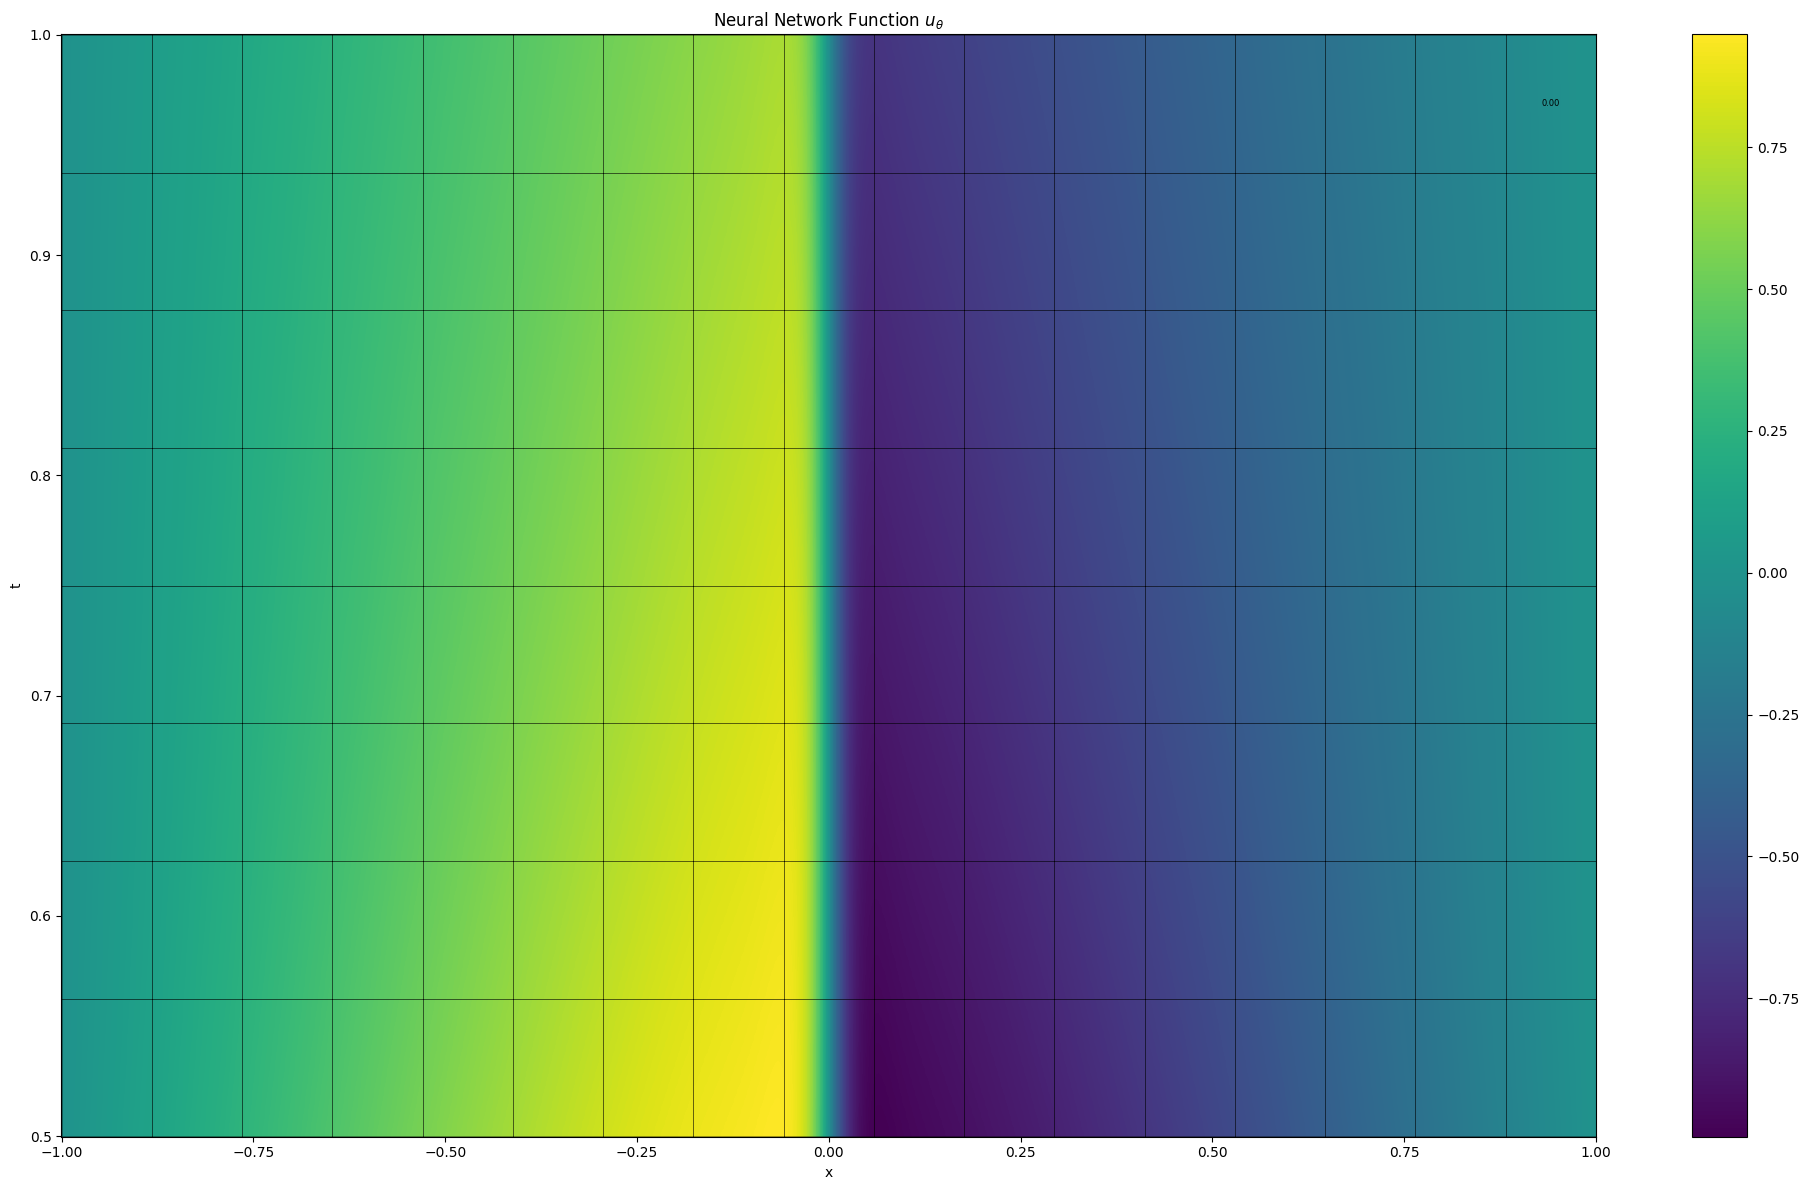

Grade 0, Iter 2100, loss_eqn: 0.028179, loss_eqn_from_kh: 0.028179, loss_l1: 0.507562, loss_ibc: 0.000411
The largest W^{1,inf} norm of k_h coeffs is 9.982225
Grade 0, Iter 2200, loss_eqn: 0.028765, loss_eqn_from_kh: 0.028765, loss_l1: 0.499181, loss_ibc: 0.000882
The largest W^{1,inf} norm of k_h coeffs is 9.801971
Grade 0, Iter 2300, loss_eqn: 0.039136, loss_eqn_from_kh: 0.039136, loss_l1: 0.502032, loss_ibc: 0.000212
The largest W^{1,inf} norm of k_h coeffs is 9.883394
Grade 0, Iter 2400, loss_eqn: 0.031034, loss_eqn_from_kh: 0.031034, loss_l1: 0.492442, loss_ibc: 0.000419
The largest W^{1,inf} norm of k_h coeffs is 9.880293
Grade 0, Iter 2500, loss_eqn: 0.029077, loss_eqn_from_kh: 0.029077, loss_l1: 0.492905, loss_ibc: 0.000859
The largest W^{1,inf} norm of k_h coeffs is 9.899294
Grade 0, Iter 2600, loss_eqn: 0.036800, loss_eqn_from_kh: 0.036800, loss_l1: 0.500904, loss_ibc: 0.000461
The largest W^{1,inf} norm of k_h coeffs is 9.937832
Grade 0, Iter 2700, loss_eqn: 0.016852, loss_e

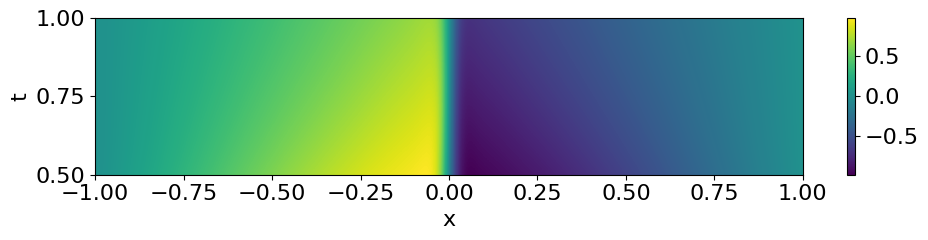

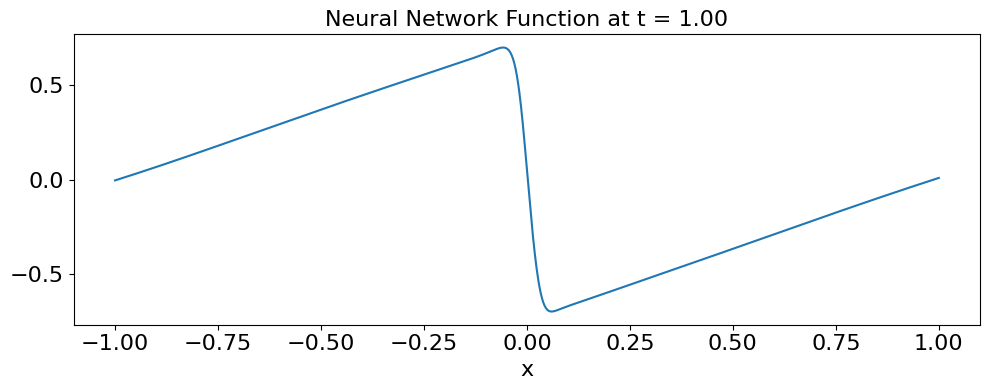

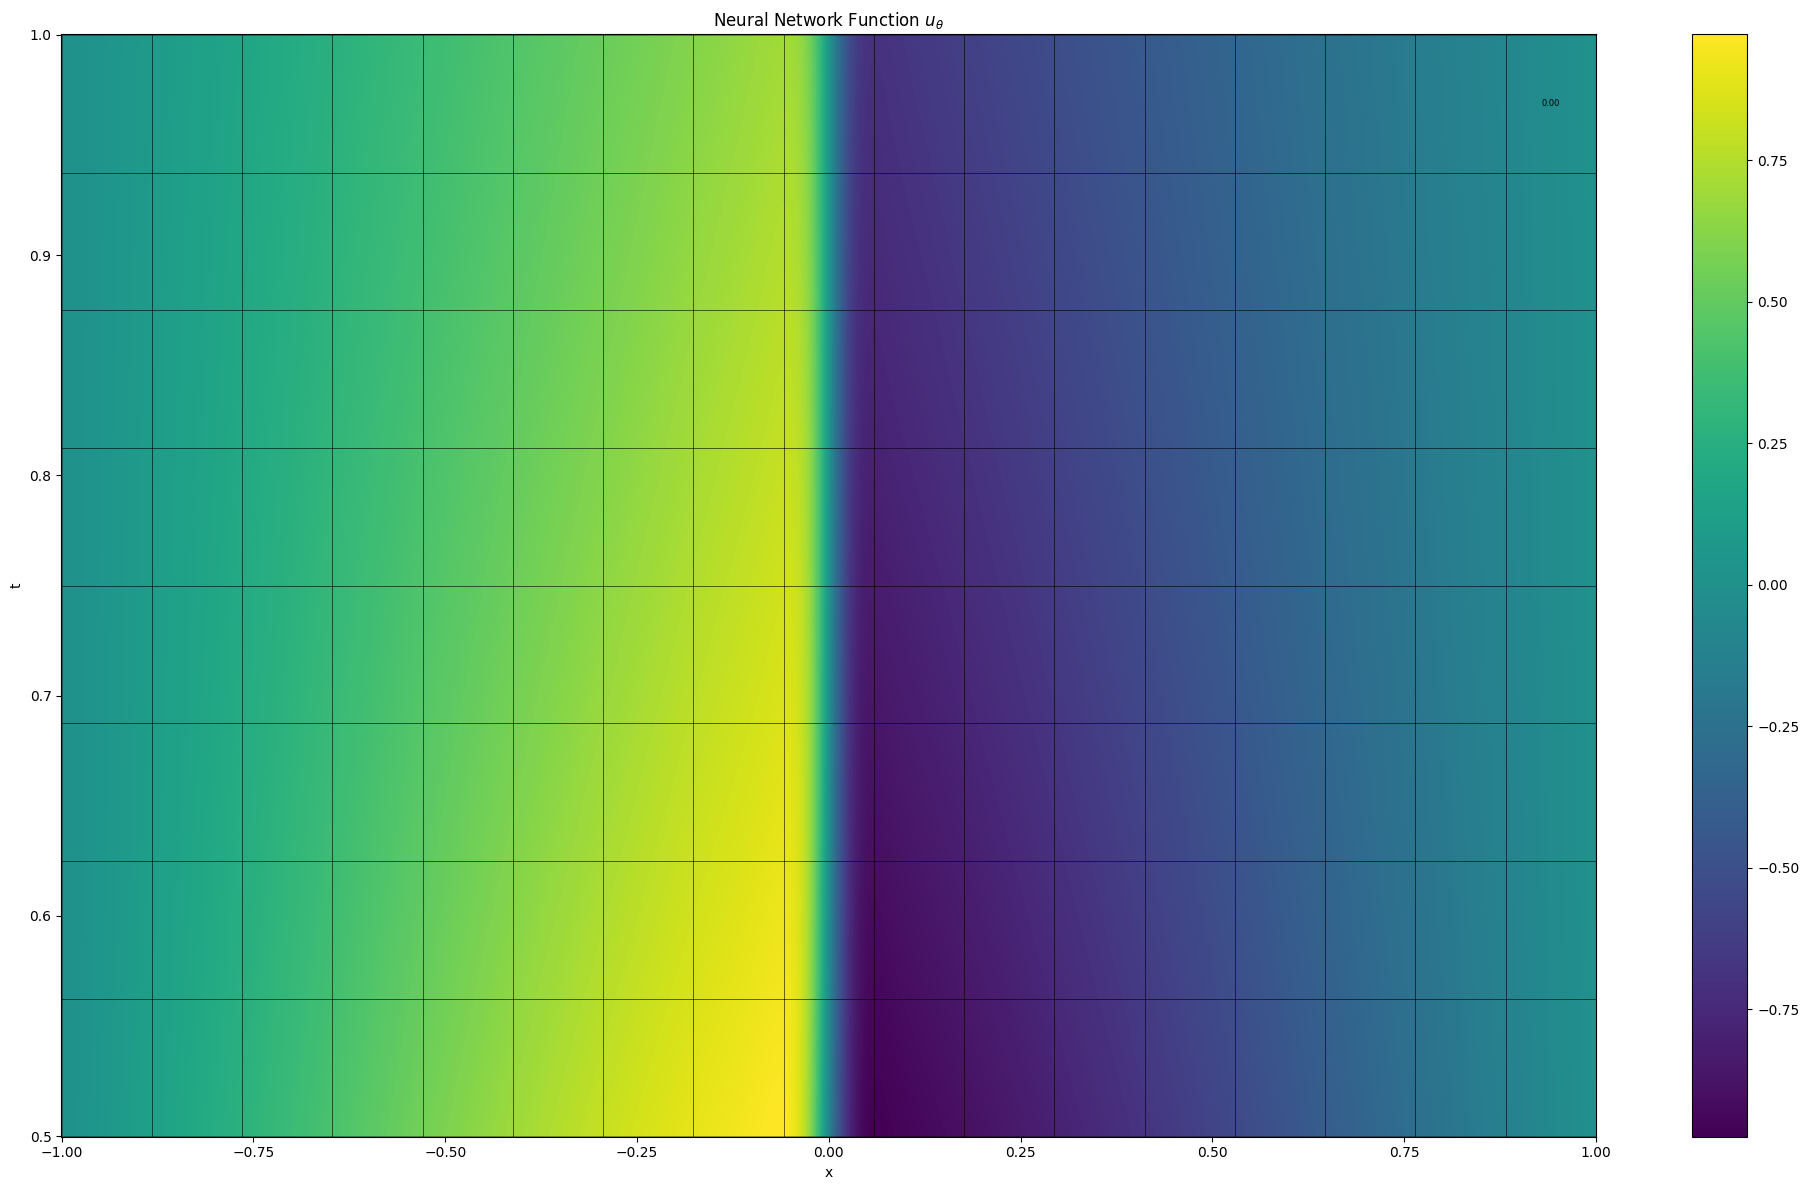

Grade 0, Iter 3100, loss_eqn: 0.026508, loss_eqn_from_kh: 0.026508, loss_l1: 0.496707, loss_ibc: 0.000295
The largest W^{1,inf} norm of k_h coeffs is 9.909015
Grade 0, Iter 3200, loss_eqn: 0.035862, loss_eqn_from_kh: 0.035862, loss_l1: 0.496619, loss_ibc: 0.000832
The largest W^{1,inf} norm of k_h coeffs is 9.943569
Grade 0, Iter 3300, loss_eqn: 0.012665, loss_eqn_from_kh: 0.012665, loss_l1: 0.487044, loss_ibc: 0.000478
The largest W^{1,inf} norm of k_h coeffs is 9.958160
Grade 0, Iter 3400, loss_eqn: 0.021154, loss_eqn_from_kh: 0.021154, loss_l1: 0.483926, loss_ibc: 0.000359
The largest W^{1,inf} norm of k_h coeffs is 9.903469
Grade 0, Iter 3500, loss_eqn: 0.030394, loss_eqn_from_kh: 0.030394, loss_l1: 0.492234, loss_ibc: 0.000671
The largest W^{1,inf} norm of k_h coeffs is 9.724396
Grade 0, Iter 3600, loss_eqn: 0.019460, loss_eqn_from_kh: 0.019459, loss_l1: 0.480780, loss_ibc: 0.000118
The largest W^{1,inf} norm of k_h coeffs is 9.829542
Grade 0, Iter 3700, loss_eqn: 0.016591, loss_e

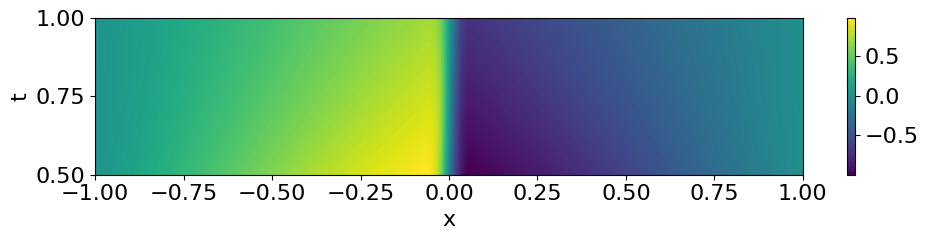

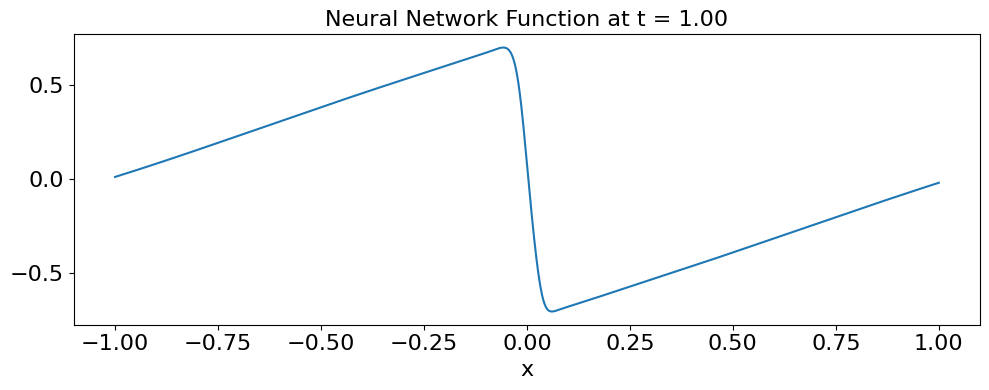

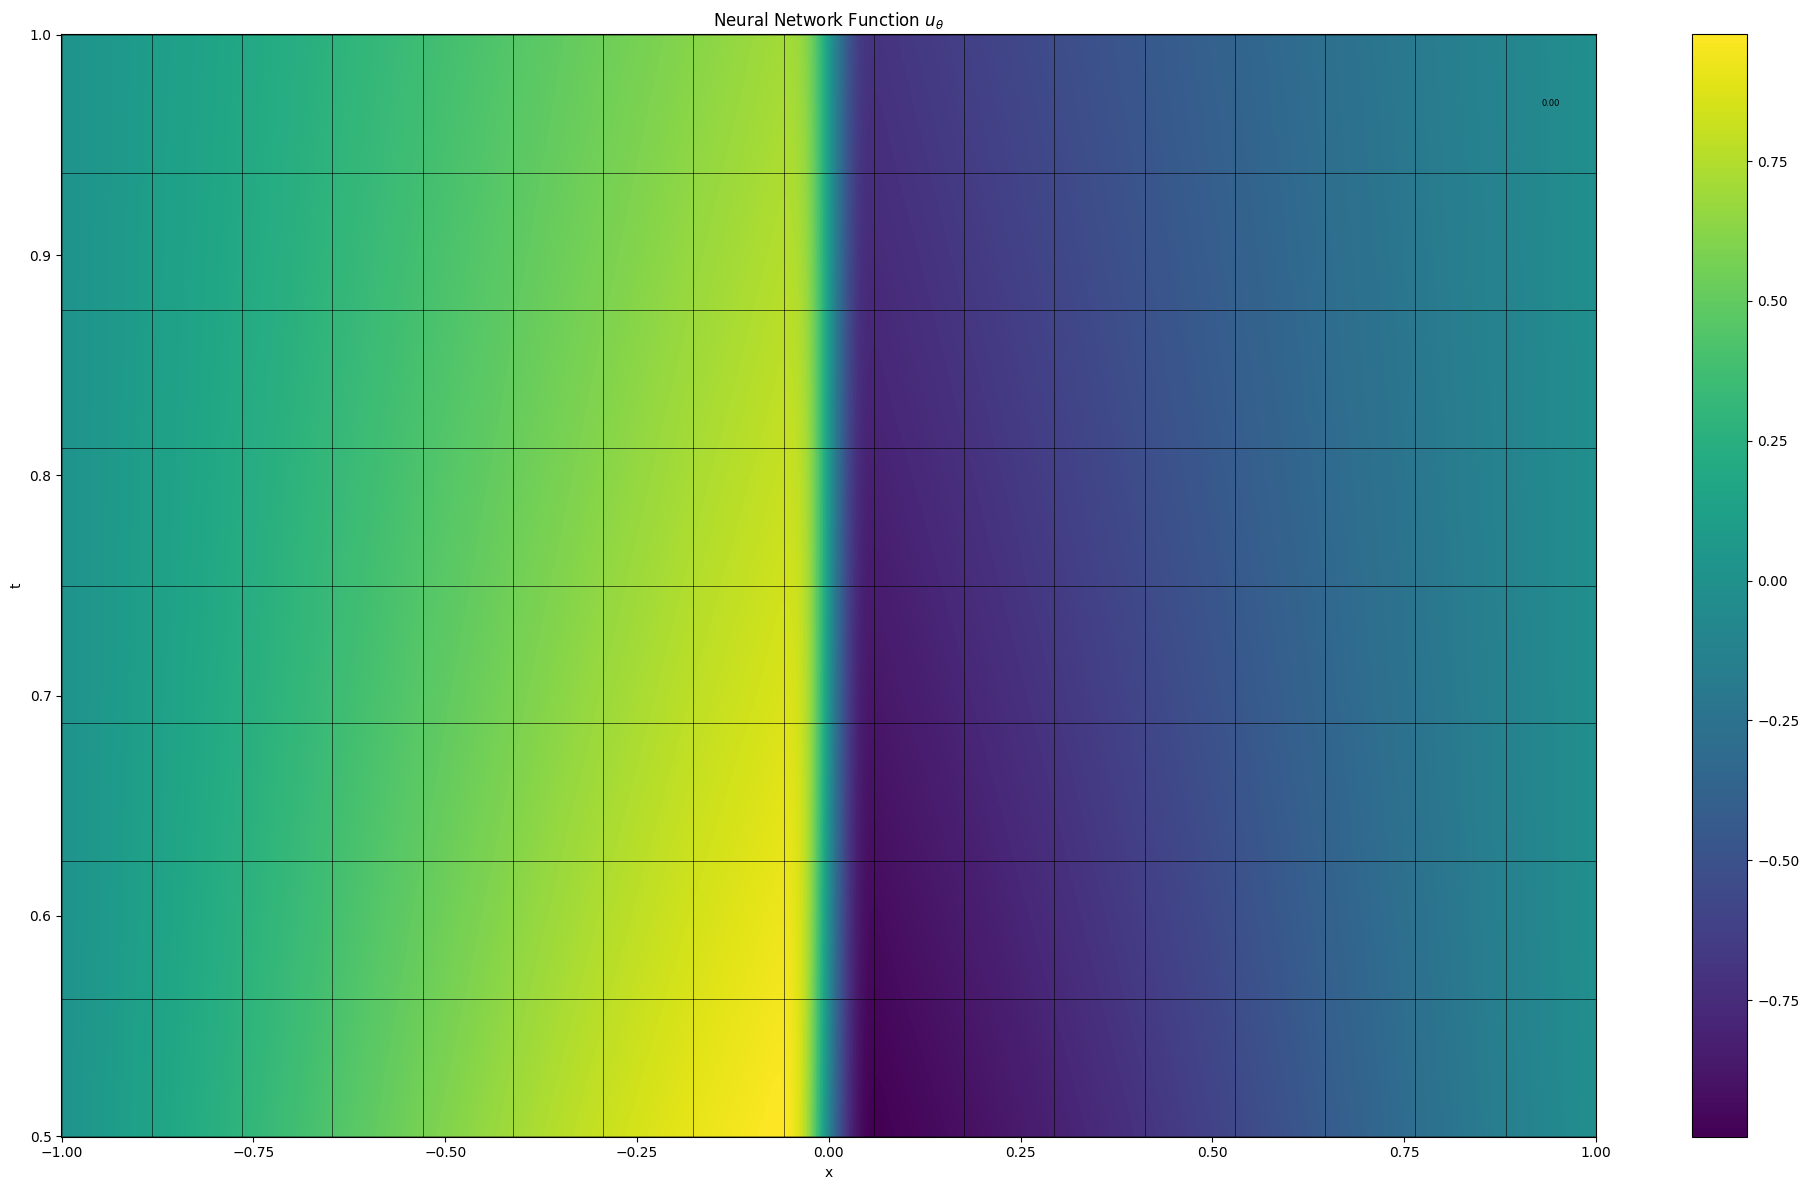

Grade 0, Iter 4100, loss_eqn: 0.025504, loss_eqn_from_kh: 0.025504, loss_l1: 0.477280, loss_ibc: 0.000156
The largest W^{1,inf} norm of k_h coeffs is 9.950566
Grade 0, Iter 4200, loss_eqn: 0.012416, loss_eqn_from_kh: 0.012416, loss_l1: 0.471682, loss_ibc: 0.000194
The largest W^{1,inf} norm of k_h coeffs is 9.892485
Grade 0, Iter 4300, loss_eqn: 0.015288, loss_eqn_from_kh: 0.015288, loss_l1: 0.467884, loss_ibc: 0.000236
The largest W^{1,inf} norm of k_h coeffs is 9.913017
Grade 0, Iter 4400, loss_eqn: 0.011836, loss_eqn_from_kh: 0.011836, loss_l1: 0.464698, loss_ibc: 0.001010
The largest W^{1,inf} norm of k_h coeffs is 9.953110
Grade 0, Iter 4500, loss_eqn: 0.027002, loss_eqn_from_kh: 0.027002, loss_l1: 0.479175, loss_ibc: 0.000834
The largest W^{1,inf} norm of k_h coeffs is 9.632435
Grade 0, Iter 4600, loss_eqn: 0.019449, loss_eqn_from_kh: 0.019449, loss_l1: 0.470684, loss_ibc: 0.000147
The largest W^{1,inf} norm of k_h coeffs is 9.773293
Grade 0, Iter 4700, loss_eqn: 0.009751, loss_e

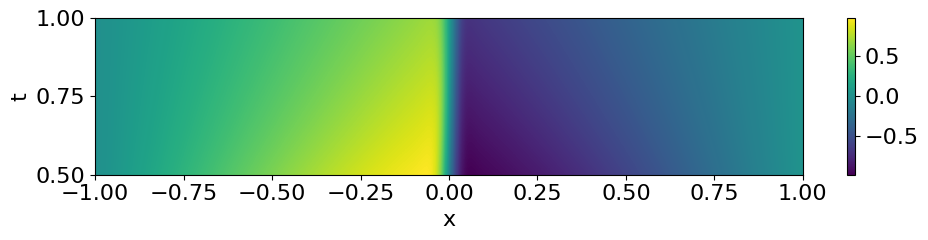

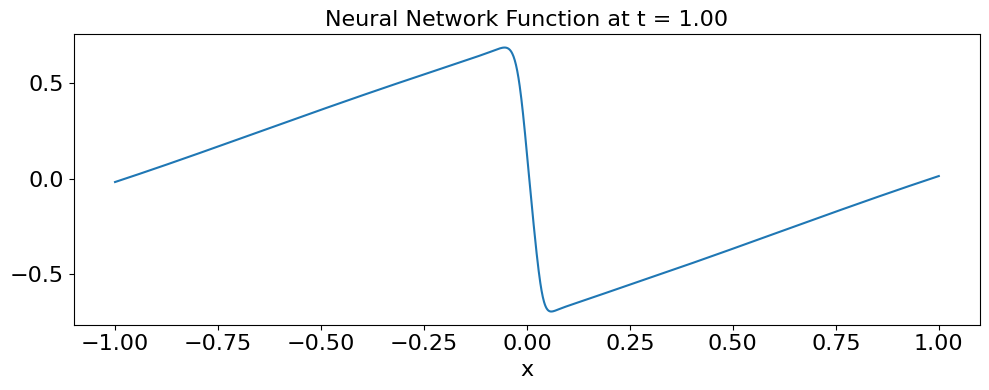

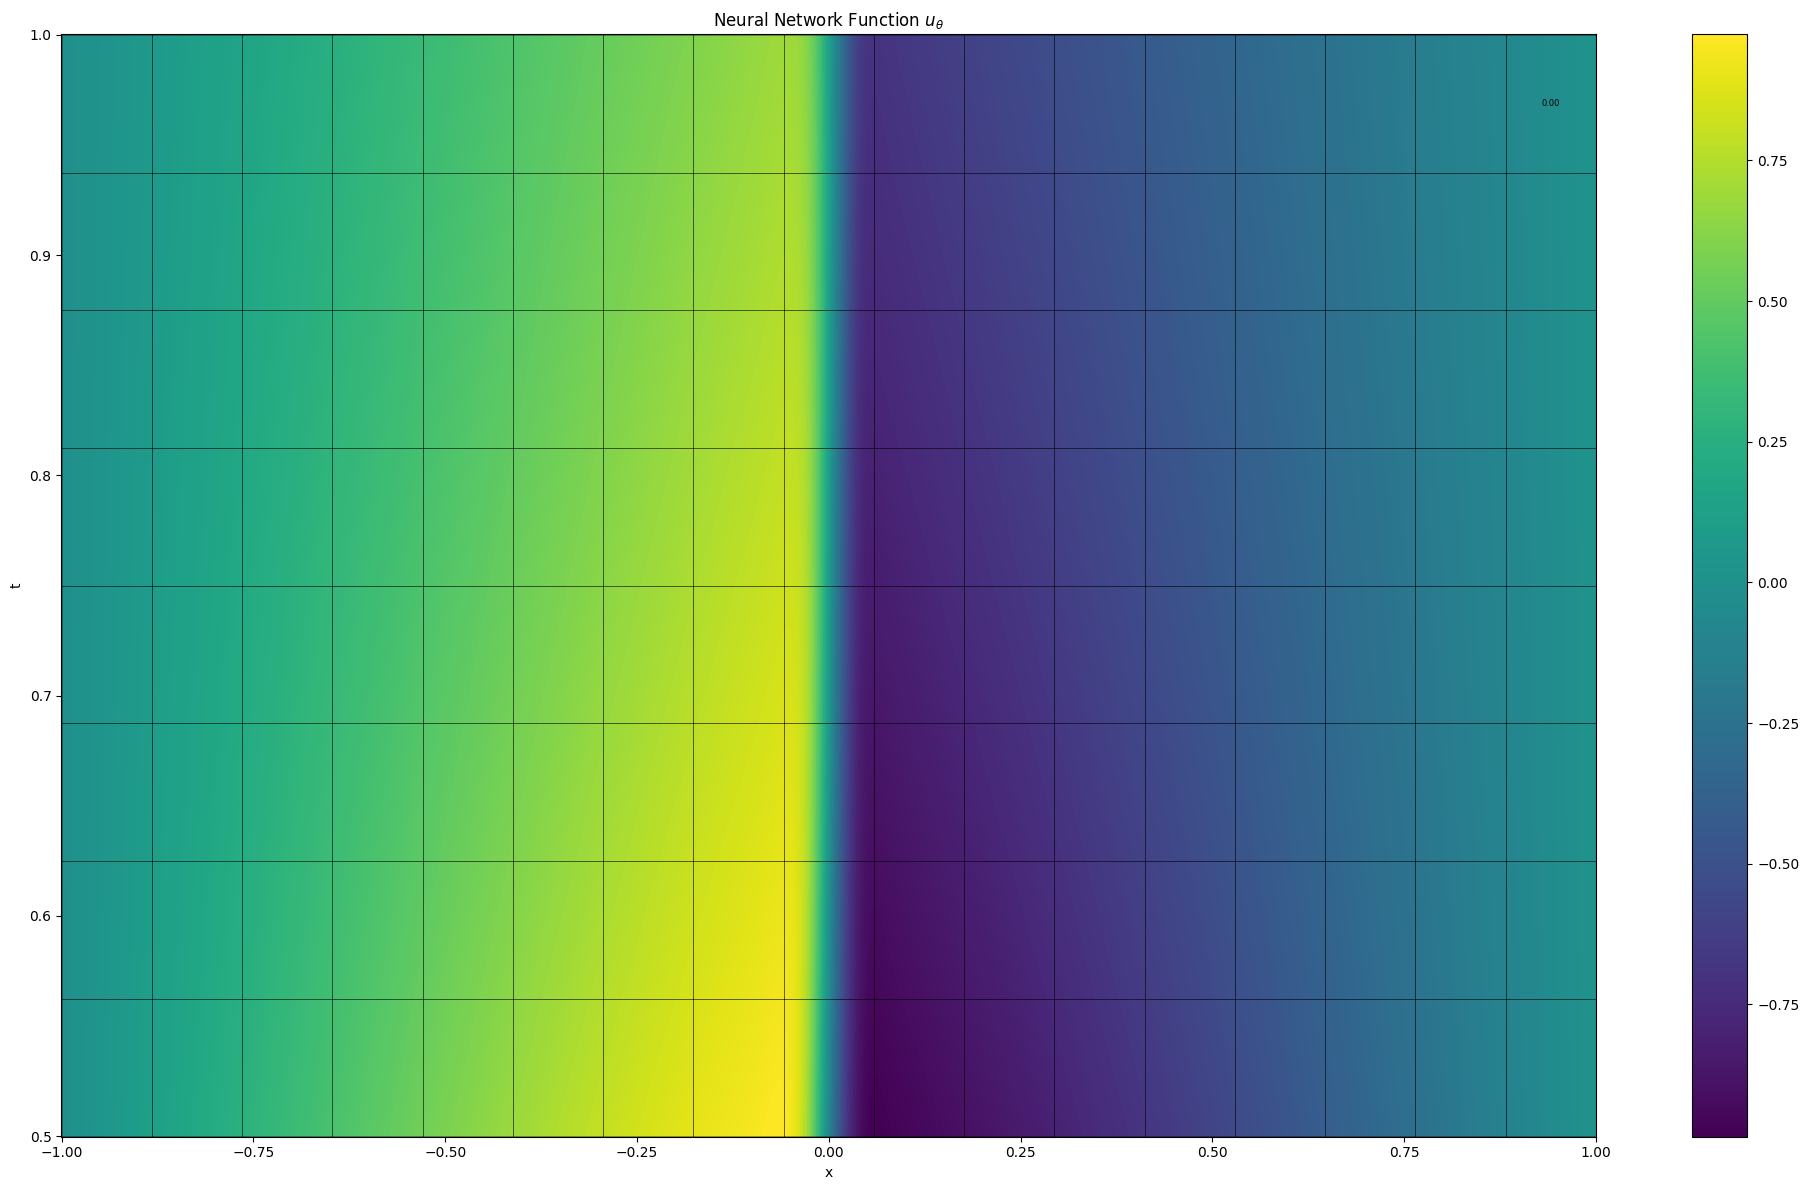

Grade 0, Iter 5100, loss_eqn: 0.012891, loss_eqn_from_kh: 0.012891, loss_l1: 0.470515, loss_ibc: 0.000341
The largest W^{1,inf} norm of k_h coeffs is 9.772551
Grade 0, Iter 5200, loss_eqn: 0.014425, loss_eqn_from_kh: 0.014425, loss_l1: 0.466736, loss_ibc: 0.000244
The largest W^{1,inf} norm of k_h coeffs is 9.676130
Grade 0, Iter 5300, loss_eqn: 0.007617, loss_eqn_from_kh: 0.007617, loss_l1: 0.461523, loss_ibc: 0.000081
The largest W^{1,inf} norm of k_h coeffs is 9.882646
Grade 0, Iter 5400, loss_eqn: 0.012370, loss_eqn_from_kh: 0.012370, loss_l1: 0.464224, loss_ibc: 0.000086
The largest W^{1,inf} norm of k_h coeffs is 9.944949
Grade 0, Iter 5500, loss_eqn: 0.005050, loss_eqn_from_kh: 0.005050, loss_l1: 0.460894, loss_ibc: 0.000065
The largest W^{1,inf} norm of k_h coeffs is 9.997099
Grade 0, Iter 5600, loss_eqn: 0.010675, loss_eqn_from_kh: 0.010675, loss_l1: 0.464656, loss_ibc: 0.000285
The largest W^{1,inf} norm of k_h coeffs is 9.994495
Grade 0, Iter 5700, loss_eqn: 0.005744, loss_e

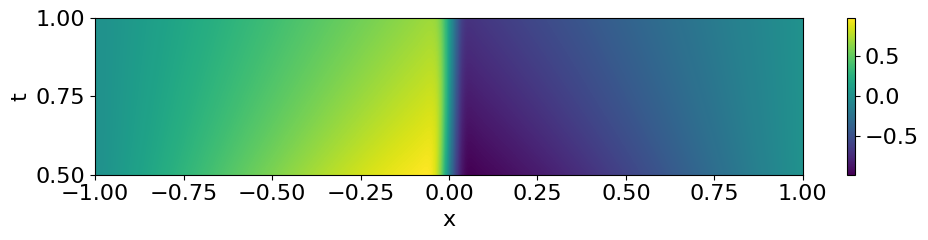

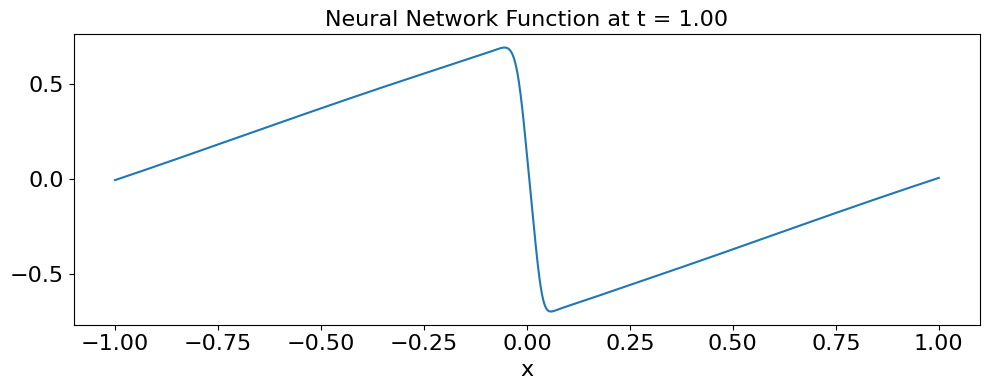

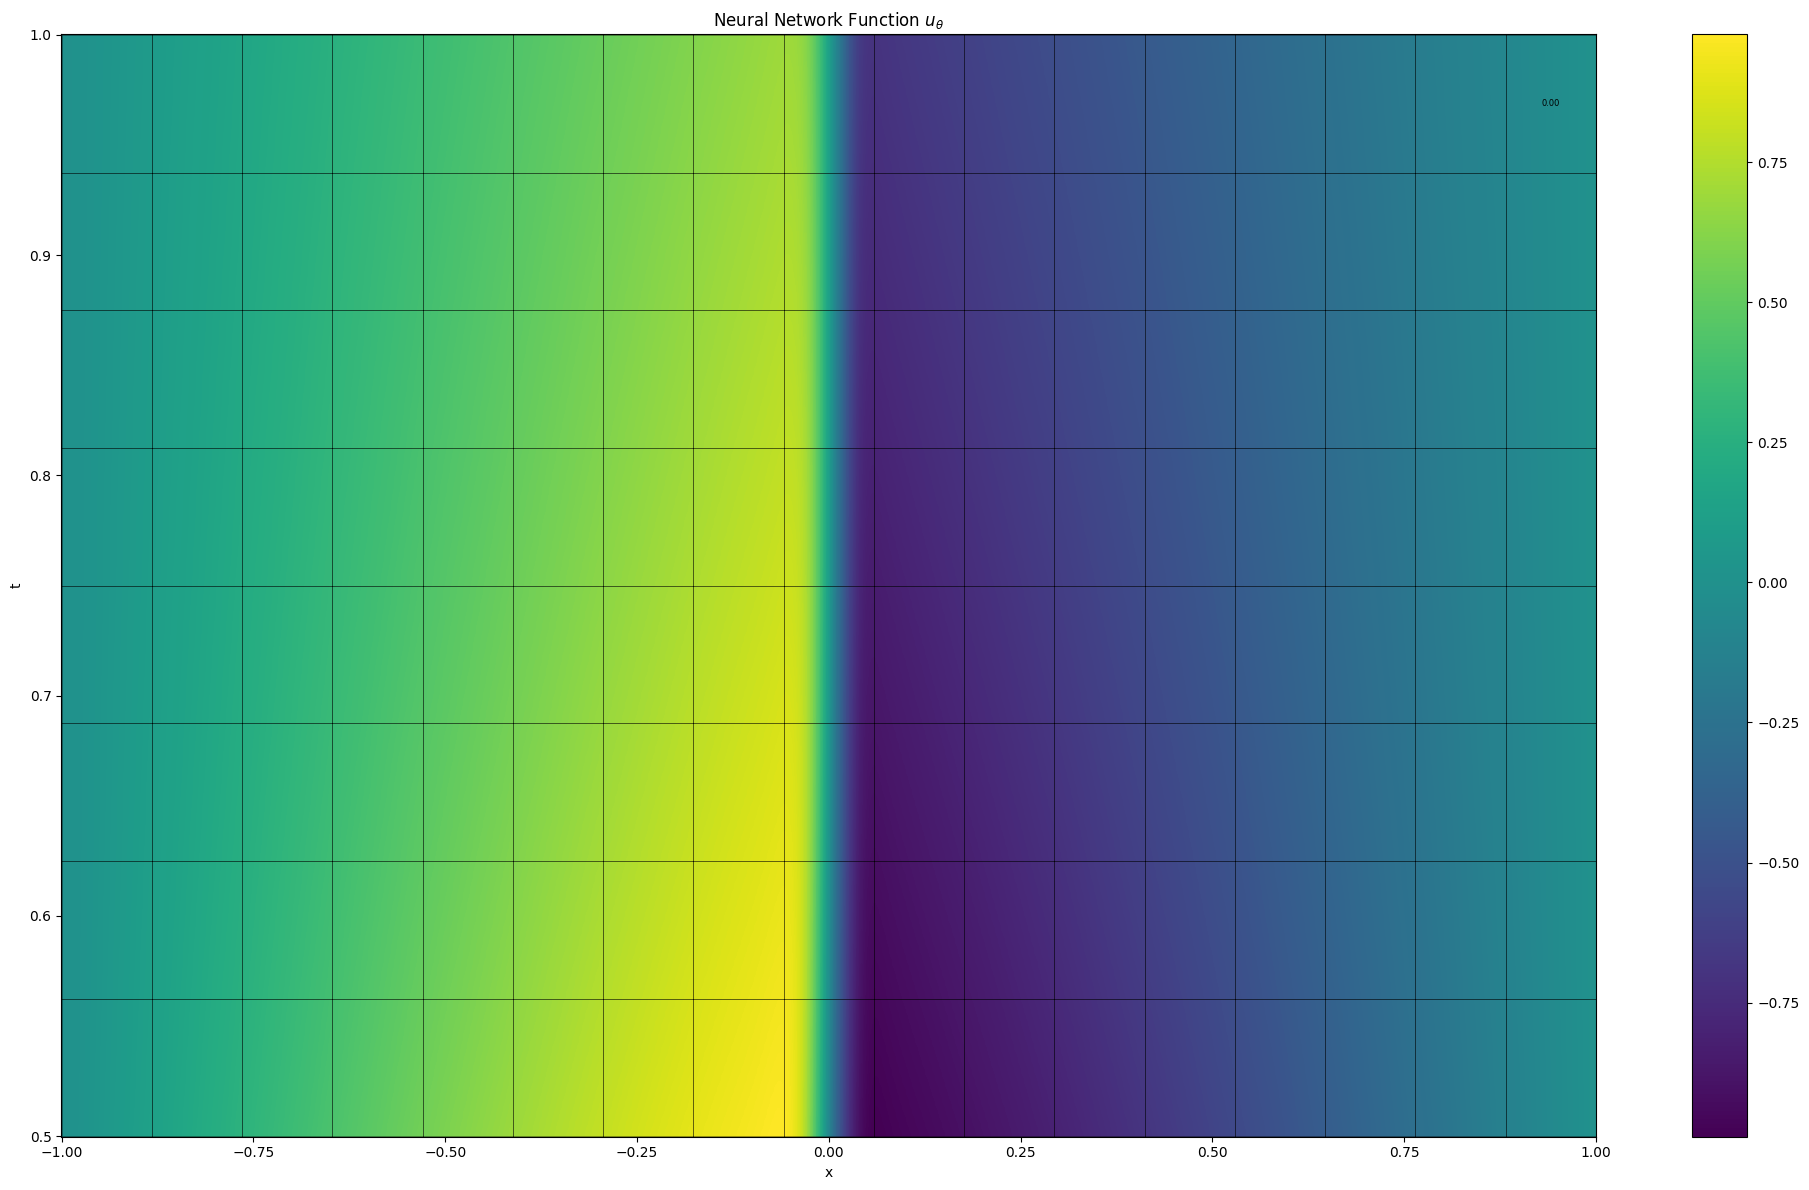

Grade 0, Iter 6100, loss_eqn: 0.008232, loss_eqn_from_kh: 0.008232, loss_l1: 0.458179, loss_ibc: 0.000103
The largest W^{1,inf} norm of k_h coeffs is 9.929419
Grade 0, Iter 6200, loss_eqn: 0.012427, loss_eqn_from_kh: 0.012427, loss_l1: 0.461615, loss_ibc: 0.000132
The largest W^{1,inf} norm of k_h coeffs is 9.883232
Grade 0, Iter 6300, loss_eqn: 0.009388, loss_eqn_from_kh: 0.009388, loss_l1: 0.459247, loss_ibc: 0.000051
The largest W^{1,inf} norm of k_h coeffs is 9.638340
Grade 0, Iter 6400, loss_eqn: 0.005493, loss_eqn_from_kh: 0.005493, loss_l1: 0.455942, loss_ibc: 0.000051
The largest W^{1,inf} norm of k_h coeffs is 9.800570
Grade 0, Iter 6500, loss_eqn: 0.005460, loss_eqn_from_kh: 0.005460, loss_l1: 0.456518, loss_ibc: 0.000081
The largest W^{1,inf} norm of k_h coeffs is 9.971283
Grade 0, Iter 6600, loss_eqn: 0.006335, loss_eqn_from_kh: 0.006335, loss_l1: 0.461047, loss_ibc: 0.000047
The largest W^{1,inf} norm of k_h coeffs is 9.978745
Grade 0, Iter 6700, loss_eqn: 0.004688, loss_e

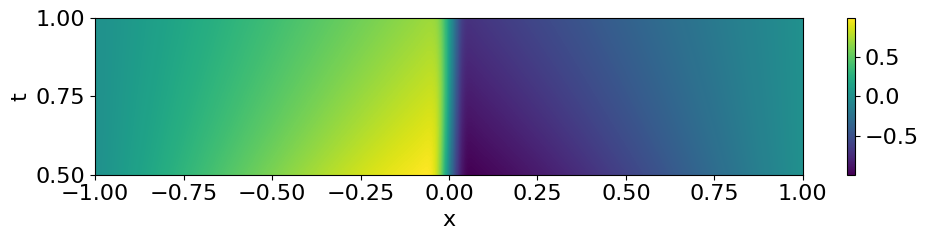

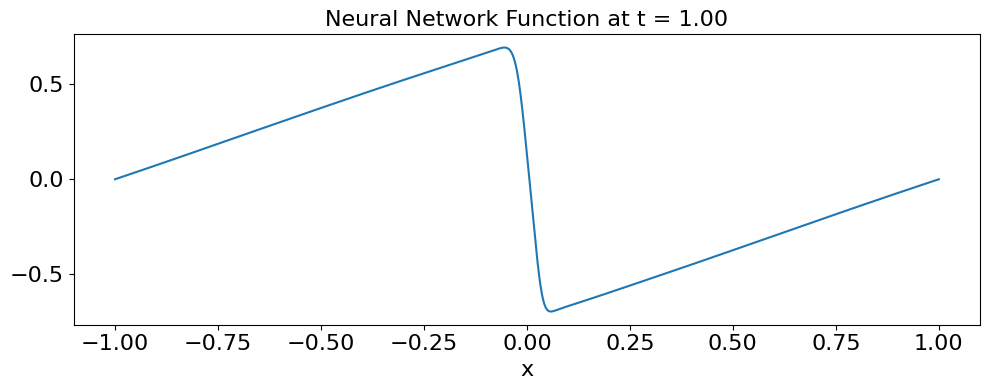

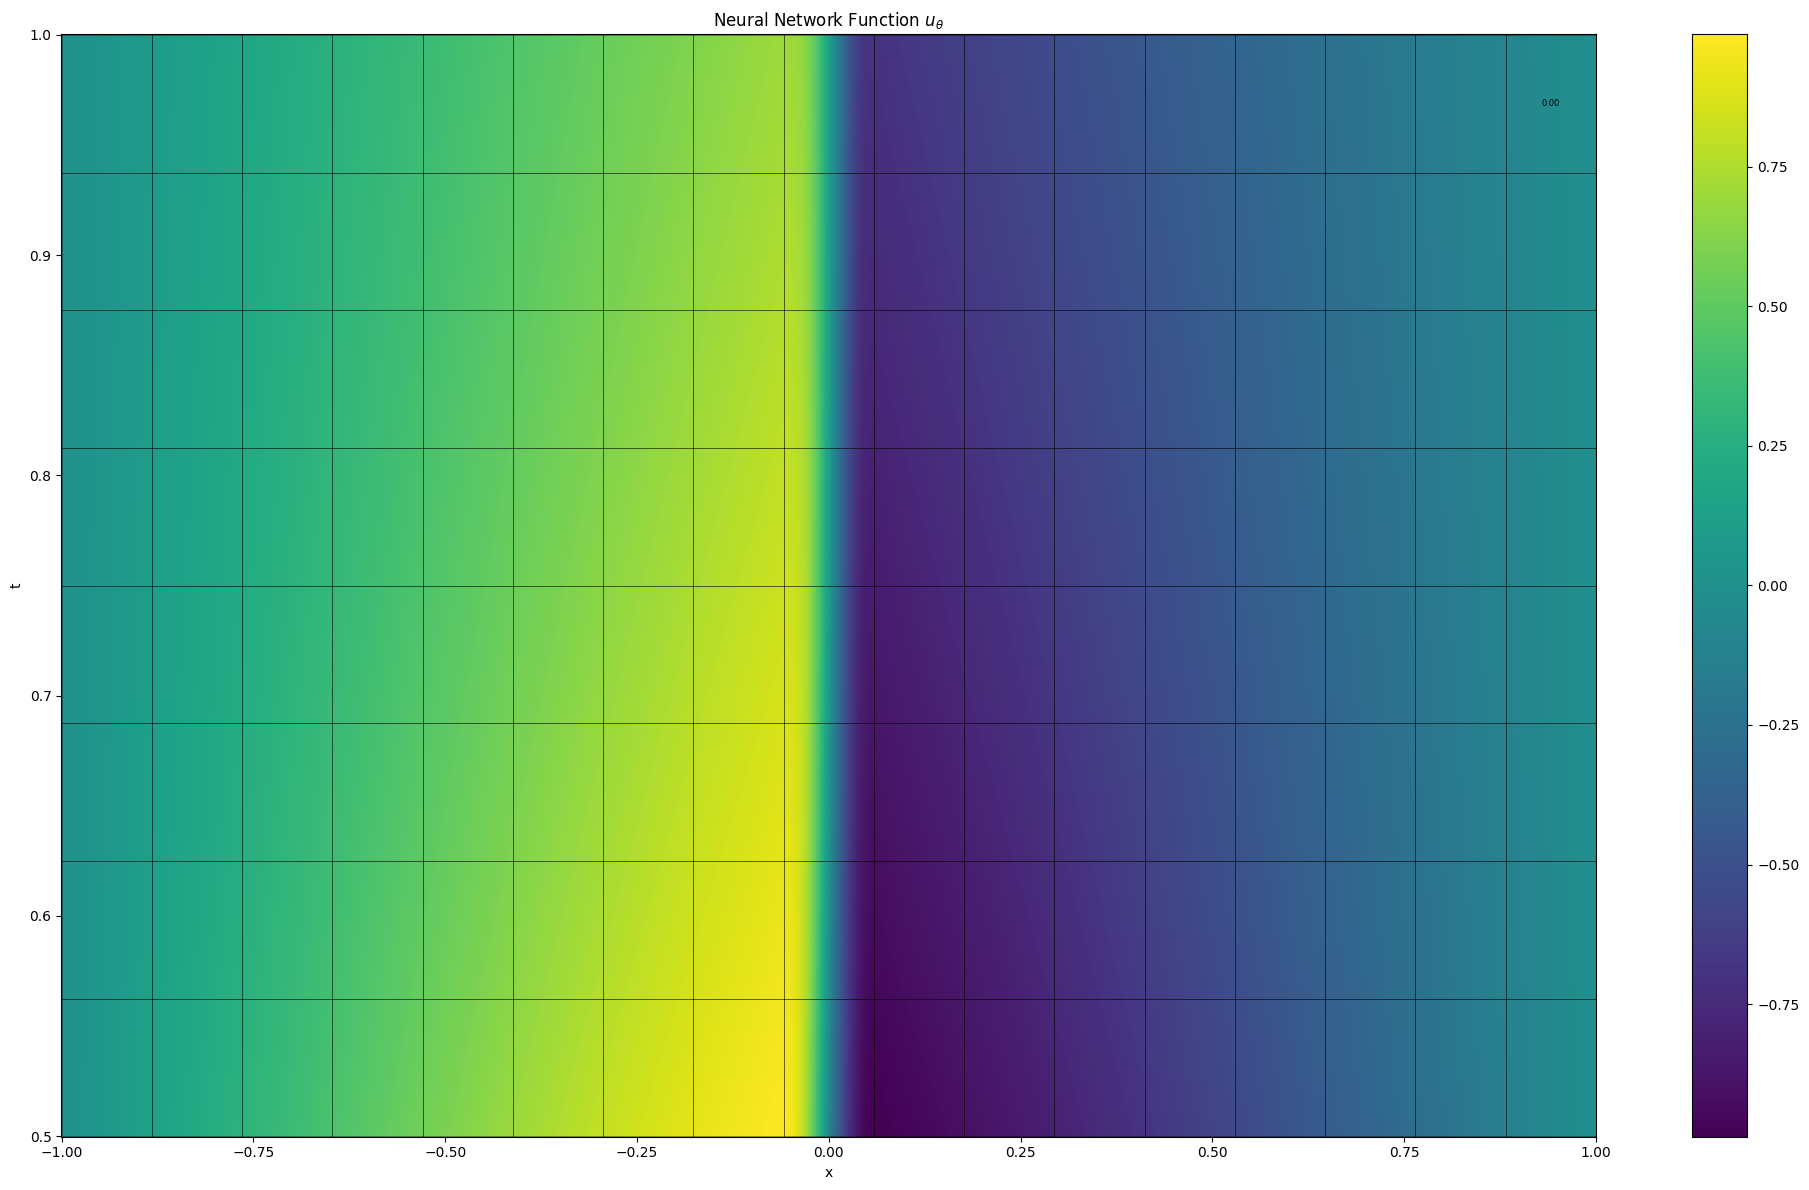

Grade 0, Iter 7100, loss_eqn: 0.008338, loss_eqn_from_kh: 0.008338, loss_l1: 0.457310, loss_ibc: 0.000042
The largest W^{1,inf} norm of k_h coeffs is 9.975960
Grade 0, Iter 7200, loss_eqn: 0.003577, loss_eqn_from_kh: 0.003577, loss_l1: 0.455345, loss_ibc: 0.000037
The largest W^{1,inf} norm of k_h coeffs is 9.962189
Grade 0, Iter 7300, loss_eqn: 0.005789, loss_eqn_from_kh: 0.005789, loss_l1: 0.457868, loss_ibc: 0.000039
The largest W^{1,inf} norm of k_h coeffs is 9.995020
Grade 0, Iter 7400, loss_eqn: 0.003590, loss_eqn_from_kh: 0.003590, loss_l1: 0.457444, loss_ibc: 0.000060
The largest W^{1,inf} norm of k_h coeffs is 9.672634
Grade 0, Iter 7500, loss_eqn: 0.006162, loss_eqn_from_kh: 0.006162, loss_l1: 0.459048, loss_ibc: 0.000039
The largest W^{1,inf} norm of k_h coeffs is 9.878664
Grade 0, Iter 7600, loss_eqn: 0.003525, loss_eqn_from_kh: 0.003525, loss_l1: 0.458524, loss_ibc: 0.000032
The largest W^{1,inf} norm of k_h coeffs is 9.891996
Grade 0, Iter 7700, loss_eqn: 0.004744, loss_e

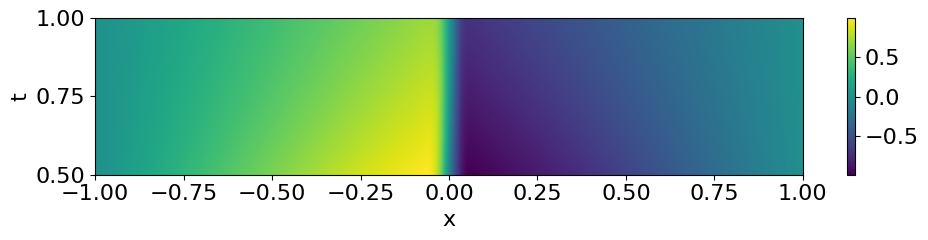

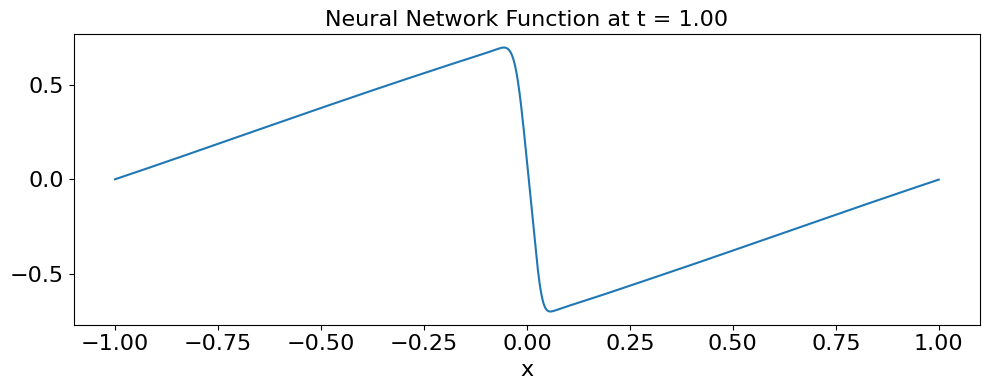

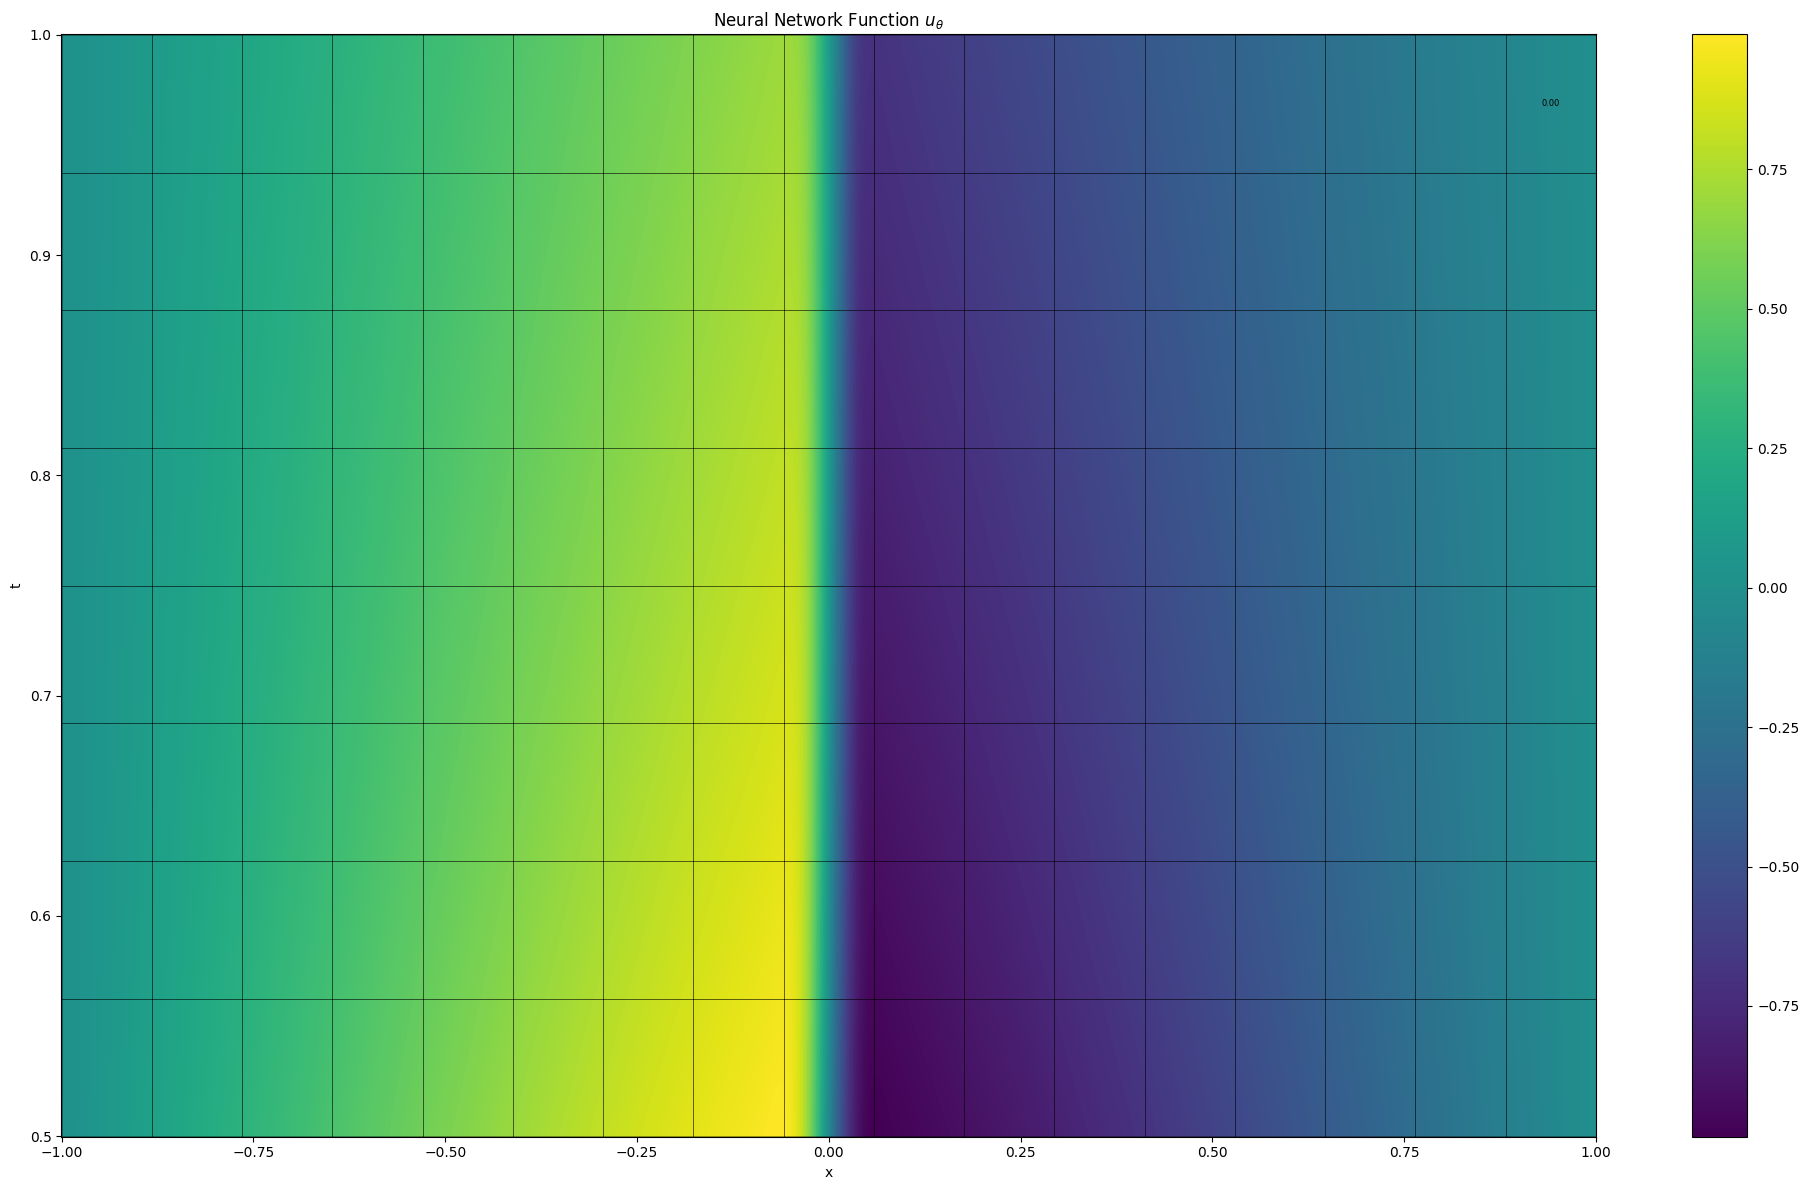

Grade 0, Iter 8100, loss_eqn: 0.003152, loss_eqn_from_kh: 0.003152, loss_l1: 0.458952, loss_ibc: 0.000042
The largest W^{1,inf} norm of k_h coeffs is 9.946370
Grade 0, Iter 8200, loss_eqn: 0.003176, loss_eqn_from_kh: 0.003176, loss_l1: 0.459466, loss_ibc: 0.000036
The largest W^{1,inf} norm of k_h coeffs is 9.980807
Grade 0, Iter 8300, loss_eqn: 0.002794, loss_eqn_from_kh: 0.002794, loss_l1: 0.459838, loss_ibc: 0.000027
The largest W^{1,inf} norm of k_h coeffs is 9.984171
Grade 0, Iter 8400, loss_eqn: 0.003206, loss_eqn_from_kh: 0.003206, loss_l1: 0.459731, loss_ibc: 0.000027
The largest W^{1,inf} norm of k_h coeffs is 9.913793
Grade 0, Iter 8500, loss_eqn: 0.002492, loss_eqn_from_kh: 0.002492, loss_l1: 0.459996, loss_ibc: 0.000024
The largest W^{1,inf} norm of k_h coeffs is 9.999649
Grade 0, Iter 8600, loss_eqn: 0.002934, loss_eqn_from_kh: 0.002934, loss_l1: 0.459524, loss_ibc: 0.000025
The largest W^{1,inf} norm of k_h coeffs is 9.967373
Grade 0, Iter 8700, loss_eqn: 0.002911, loss_e

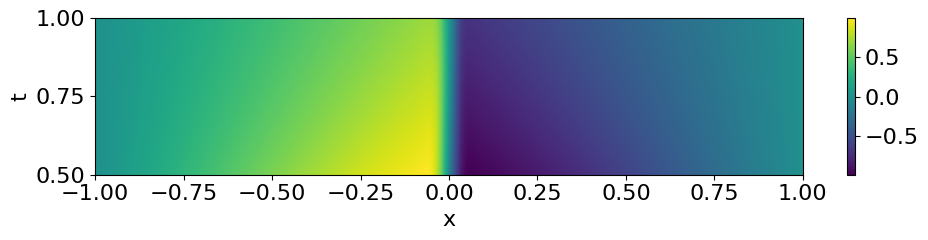

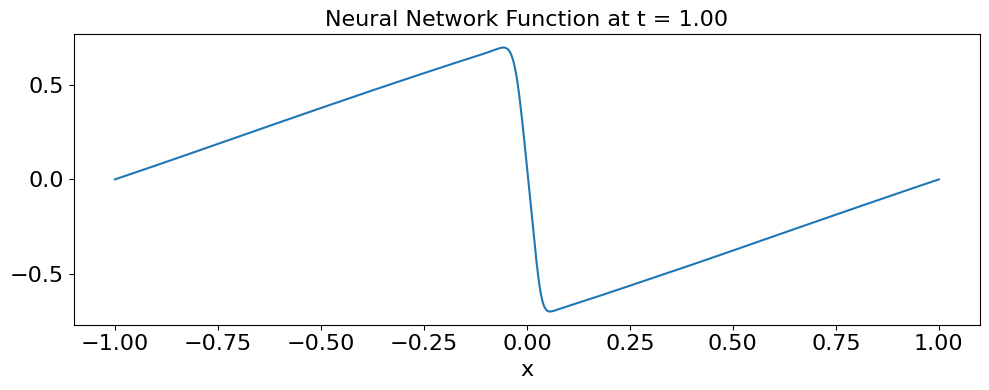

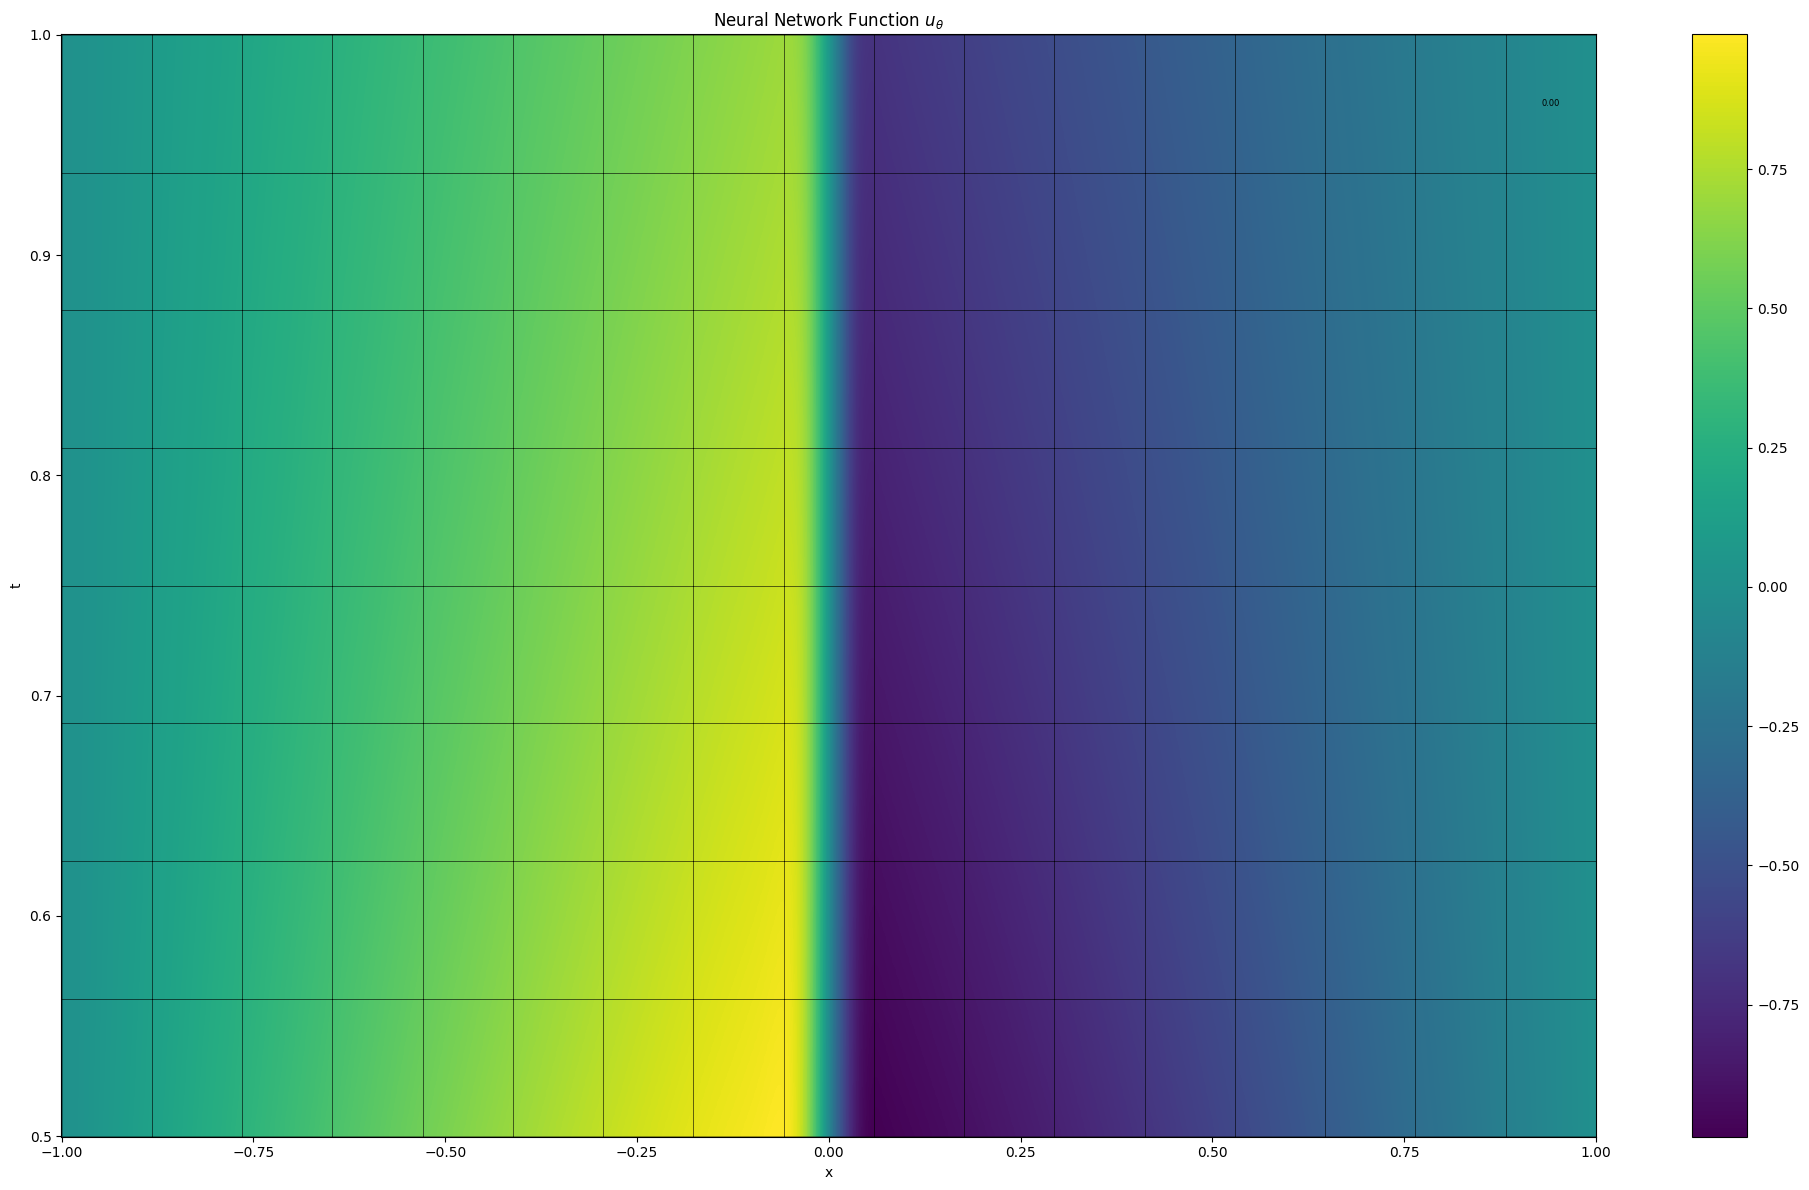

Grade 0, Iter 9100, loss_eqn: 0.002415, loss_eqn_from_kh: 0.002415, loss_l1: 0.460376, loss_ibc: 0.000022
The largest W^{1,inf} norm of k_h coeffs is 9.956629
Grade 0, Iter 9200, loss_eqn: 0.002370, loss_eqn_from_kh: 0.002370, loss_l1: 0.460331, loss_ibc: 0.000021
The largest W^{1,inf} norm of k_h coeffs is 9.998453
Grade 0, Iter 9300, loss_eqn: 0.002309, loss_eqn_from_kh: 0.002309, loss_l1: 0.460272, loss_ibc: 0.000021
The largest W^{1,inf} norm of k_h coeffs is 9.910152
Grade 0, Iter 9400, loss_eqn: 0.002254, loss_eqn_from_kh: 0.002254, loss_l1: 0.460368, loss_ibc: 0.000020
The largest W^{1,inf} norm of k_h coeffs is 9.995840
Grade 0, Iter 9500, loss_eqn: 0.002260, loss_eqn_from_kh: 0.002260, loss_l1: 0.460490, loss_ibc: 0.000020
The largest W^{1,inf} norm of k_h coeffs is 9.967758
Grade 0, Iter 9600, loss_eqn: 0.002257, loss_eqn_from_kh: 0.002257, loss_l1: 0.460526, loss_ibc: 0.000020
The largest W^{1,inf} norm of k_h coeffs is 9.887657
Grade 0, Iter 9700, loss_eqn: 0.002291, loss_e

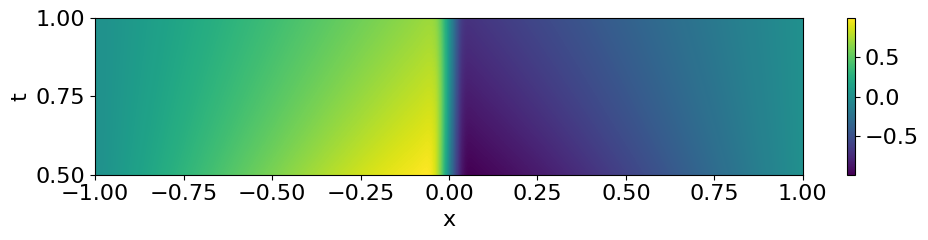

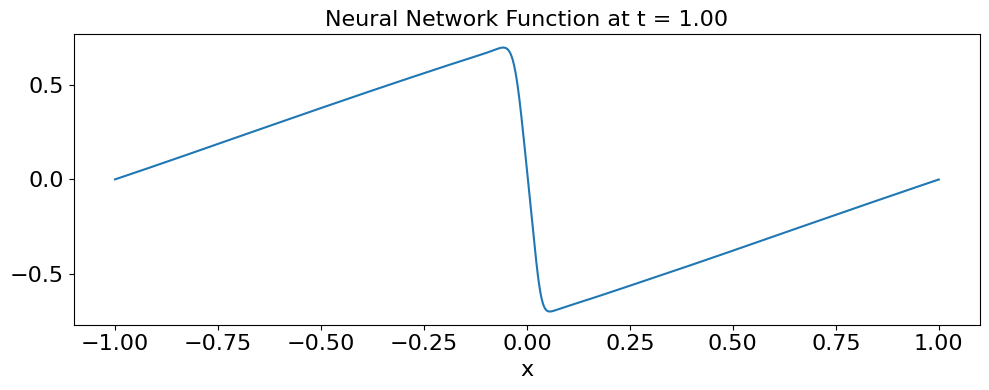


Plotting combined output across all segments from t=0 to total_t_max


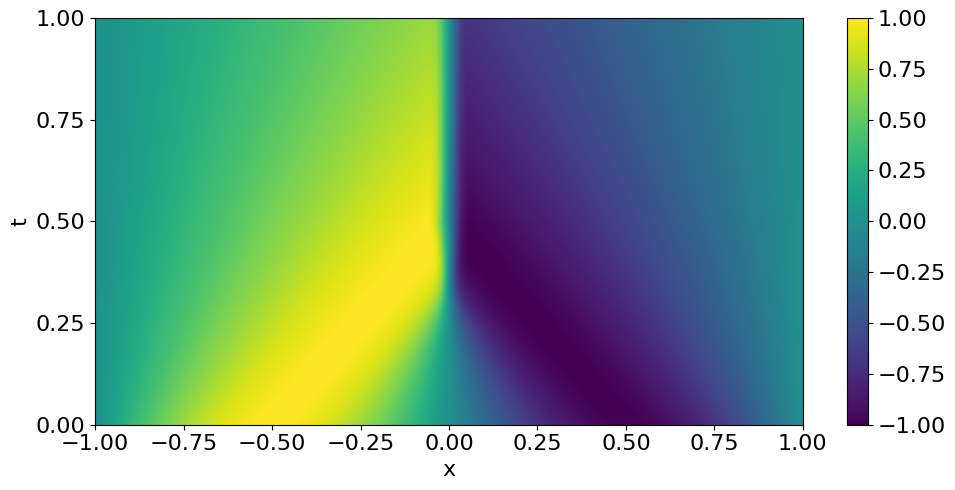

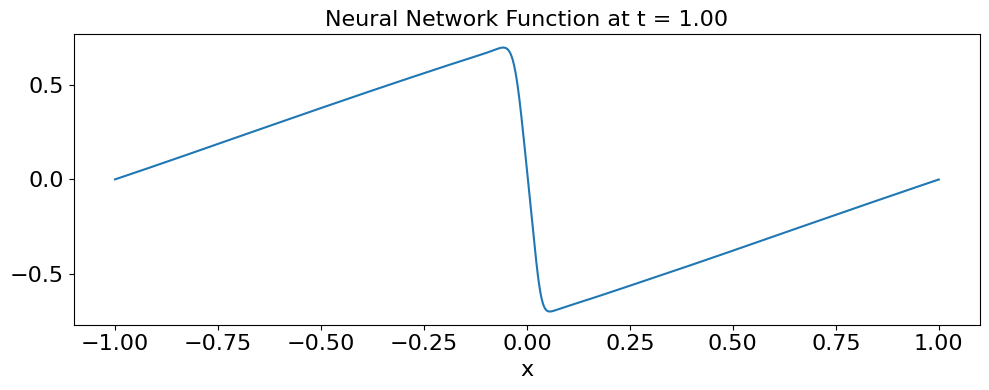

In [5]:
seq_trainer.train_seq()

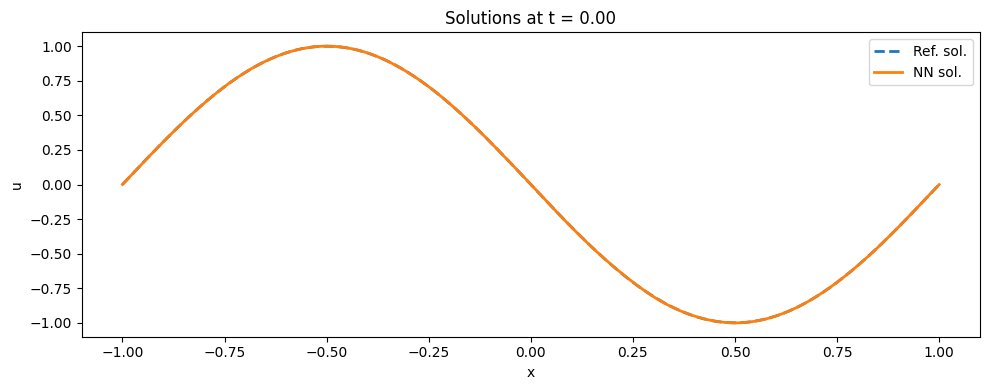

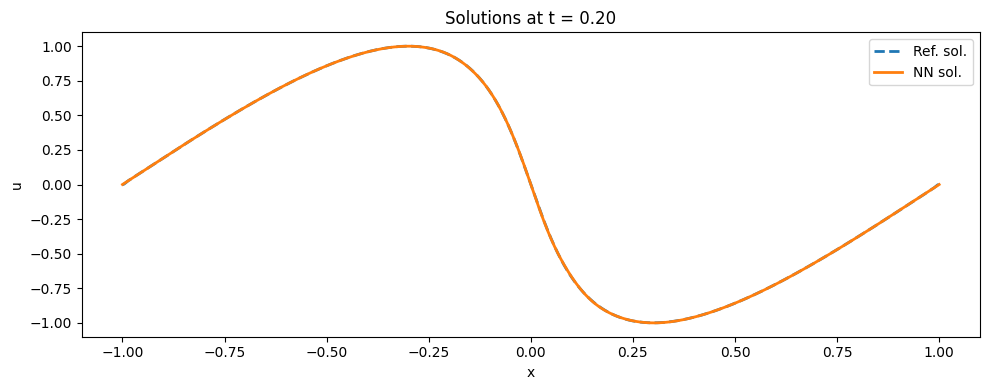

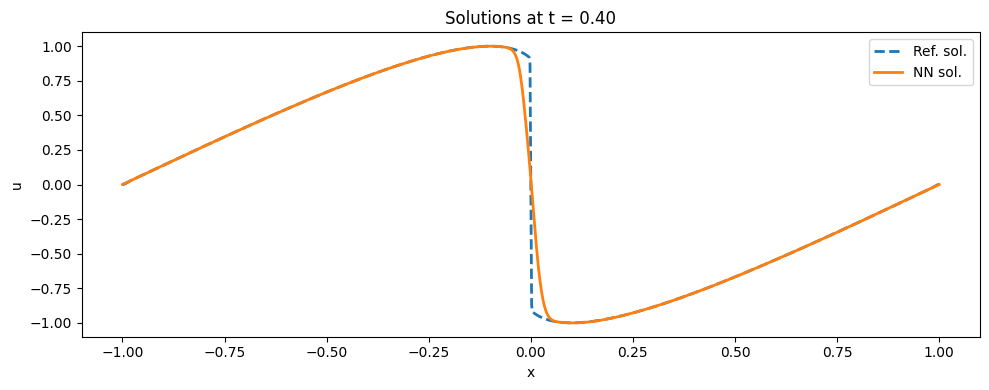

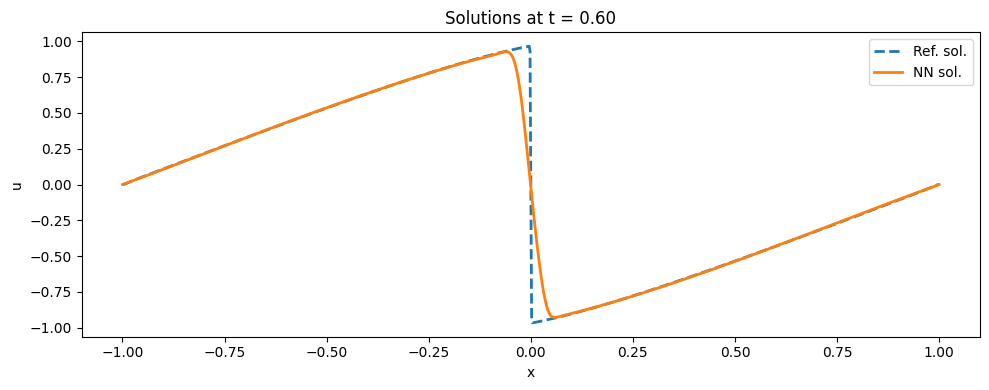

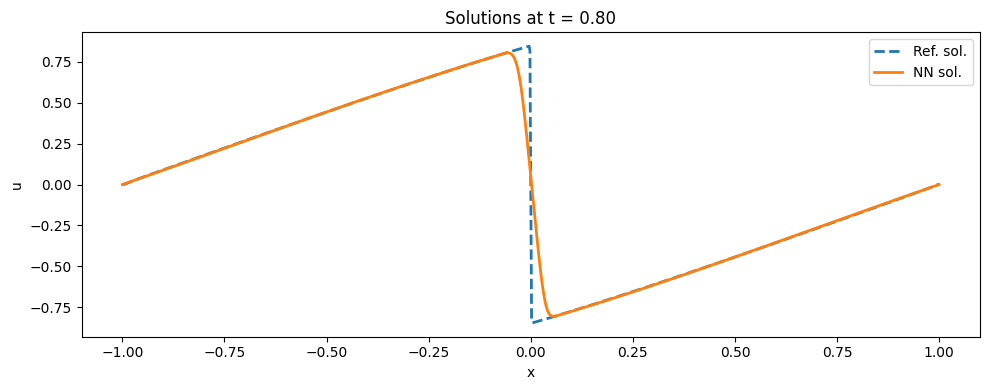

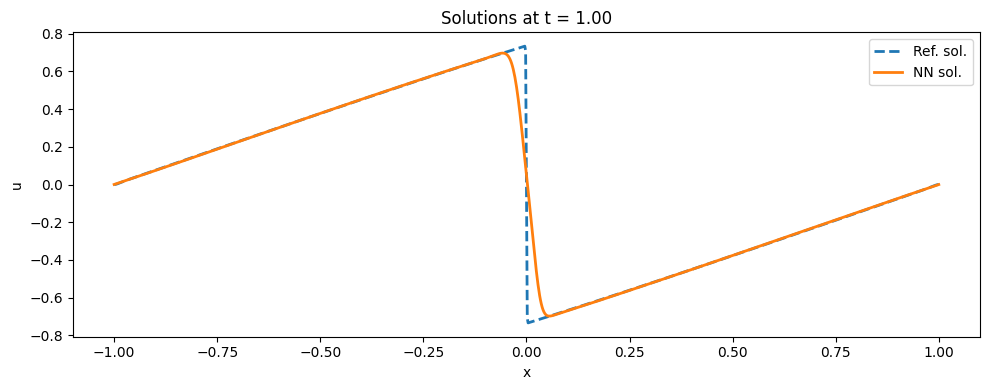

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


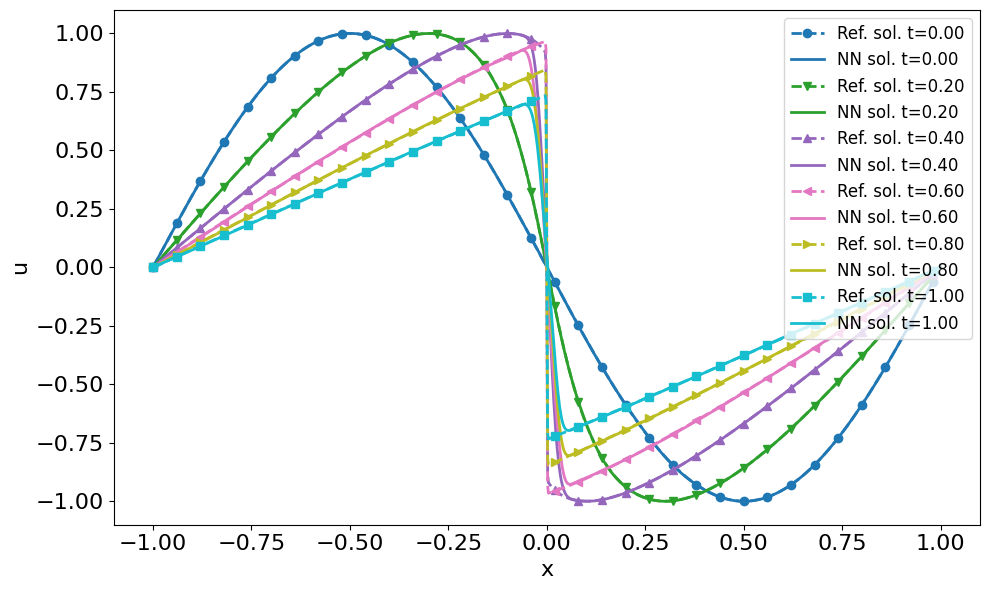

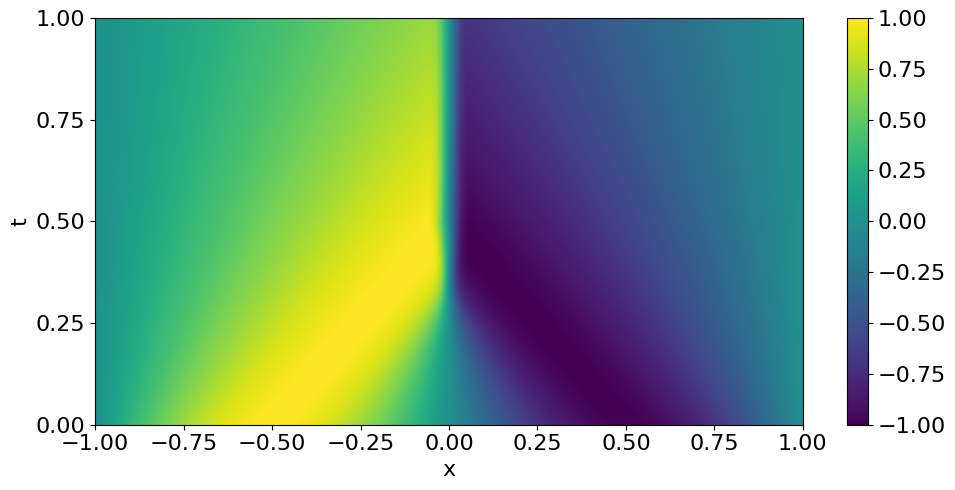

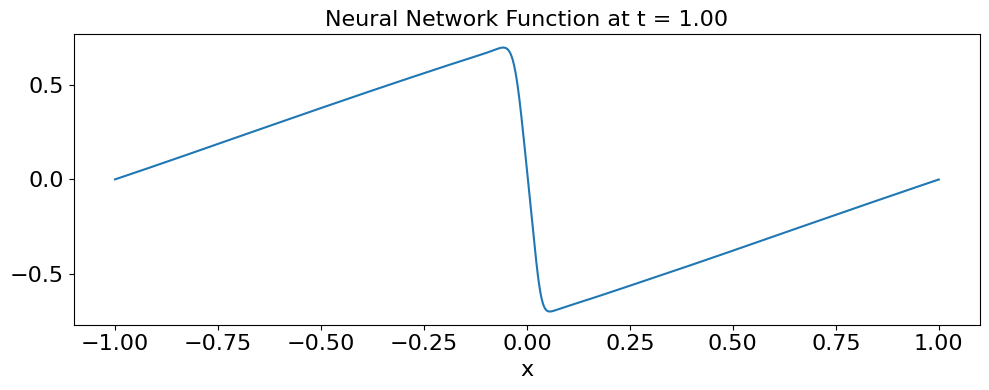

Error at T: 0.028156847324693663, Relative error at T: 0.037706760585481953
Space-time error: 0.02310886039457342, Space-time relative error: 0.02127746210947487


(np.float64(0.037706760585481953), np.float64(0.02127746210947487))

In [8]:
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together

plot_comparison_seperate_combined_u_theta(seq_trainer, x_min=-1, x_max=1, ts=[0.2*i for i in range(6)])
plot_comparison_together(seq_trainer, save_path=f'../results/sin_wave_comparison_{N_t}_{N_x}.eps', x_min=-1, x_max=1, ts=[0.2*i for i in range(6)])
plot_u_theta(seq_trainer, save_path=f'../results/sin_wave_plot_{N_t}_{N_x}.eps')
compute_errors_combined_u_theta(seq_trainer, x_min=-1, x_max=1, T=1.0)

Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.0000, 0.5000]


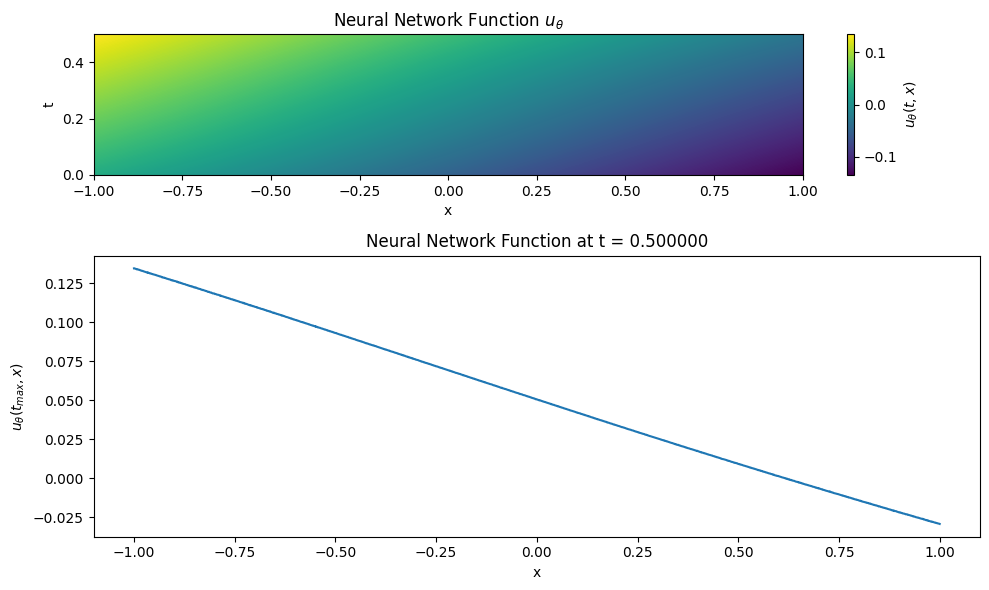


Training segment [0.0000, 0.5000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 0.204637, loss_eqn_from_kh: 0.204636, loss_eqn_abs: 0.204636, loss_ibc: 0.467140
Grade 0, Iter 100, loss_eqn: 0.536331, loss_eqn_from_kh: 0.536317, loss_eqn_abs: 0.536317, loss_ibc: 0.049528
Grade 0, Iter 200, loss_eqn: 0.372386, loss_eqn_from_kh: 0.372369, loss_eqn_abs: 0.372372, loss_ibc: 0.008679
Grade 0, Iter 300, loss_eqn: 0.247993, loss_eqn_from_kh: 0.247969, loss_eqn_abs: 0.247970, loss_ibc: 0.008688
Grade 0, Iter 400, loss_eqn: 0.196765, loss_eqn_from_kh: 0.196711, loss_eqn_abs: 0.196713, loss_ibc: 0.006674
Grade 0, Iter 500, loss_eqn: 0.139682, loss_eqn_from_kh: 0.139561, loss_eqn_abs: 0.139573, loss_ibc: 0.007157
Grade 0, Iter 600, loss_eqn: 0.129714, loss_eqn_from_kh: 0.129583, loss_eqn_abs: 0.129871, loss_ibc: 0.004383
Grade 0, Iter 700, loss_eqn: 0.131815, loss_eqn_from_kh: 0.131676, loss_eqn_abs: 0.131923, loss_ibc: 0.005072
G

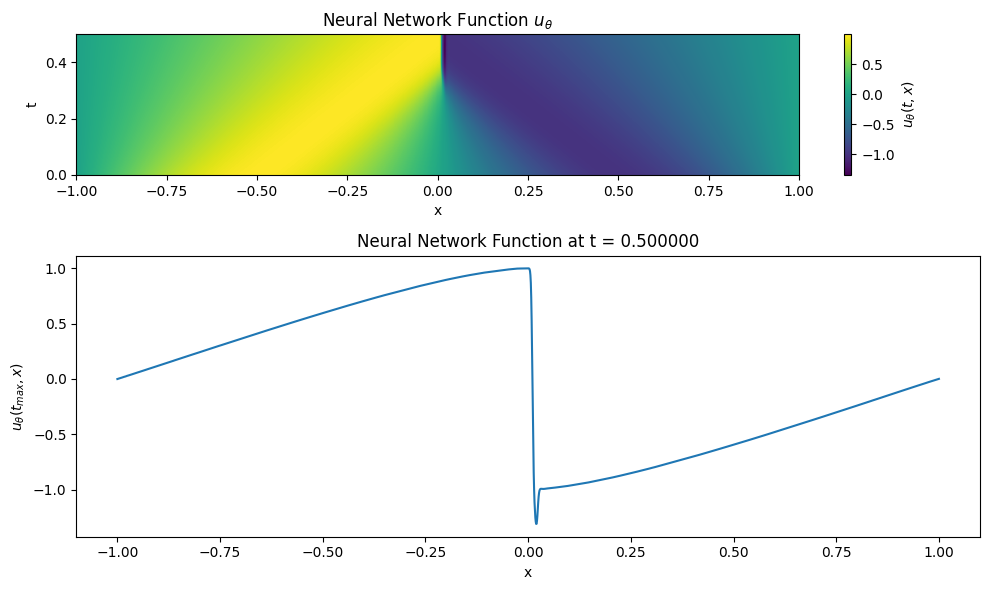

Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.5000, 1.0000]


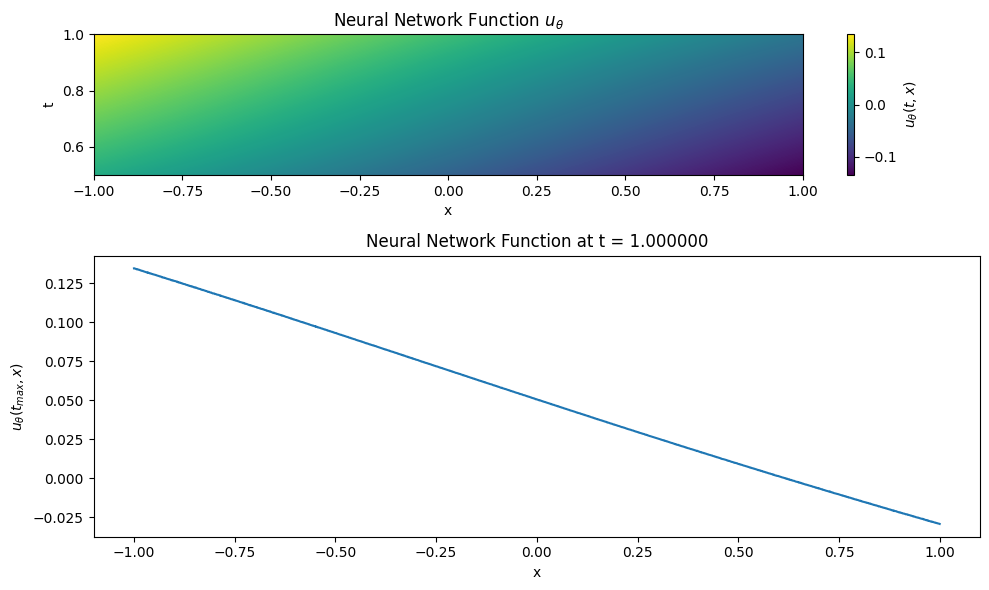


Training segment [0.5000, 1.0000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 0.204574, loss_eqn_from_kh: 0.204573, loss_eqn_abs: 0.204573, loss_ibc: 0.403934
Grade 0, Iter 100, loss_eqn: 0.533263, loss_eqn_from_kh: 0.533241, loss_eqn_abs: 0.533241, loss_ibc: 0.071674
Grade 0, Iter 200, loss_eqn: 0.362074, loss_eqn_from_kh: 0.362073, loss_eqn_abs: 0.362275, loss_ibc: 0.021846
Grade 0, Iter 300, loss_eqn: 0.307649, loss_eqn_from_kh: 0.307640, loss_eqn_abs: 0.366557, loss_ibc: 0.010986
Grade 0, Iter 400, loss_eqn: 0.210406, loss_eqn_from_kh: 0.210382, loss_eqn_abs: 0.384889, loss_ibc: 0.004316
Grade 0, Iter 500, loss_eqn: 0.127627, loss_eqn_from_kh: 0.127627, loss_eqn_abs: 0.394326, loss_ibc: 0.003175
Grade 0, Iter 600, loss_eqn: 0.123507, loss_eqn_from_kh: 0.123491, loss_eqn_abs: 0.452249, loss_ibc: 0.001790
Grade 0, Iter 700, loss_eqn: 0.081777, loss_eqn_from_kh: 0.081702, loss_eqn_abs: 0.516065, loss_ibc: 0.000785
G

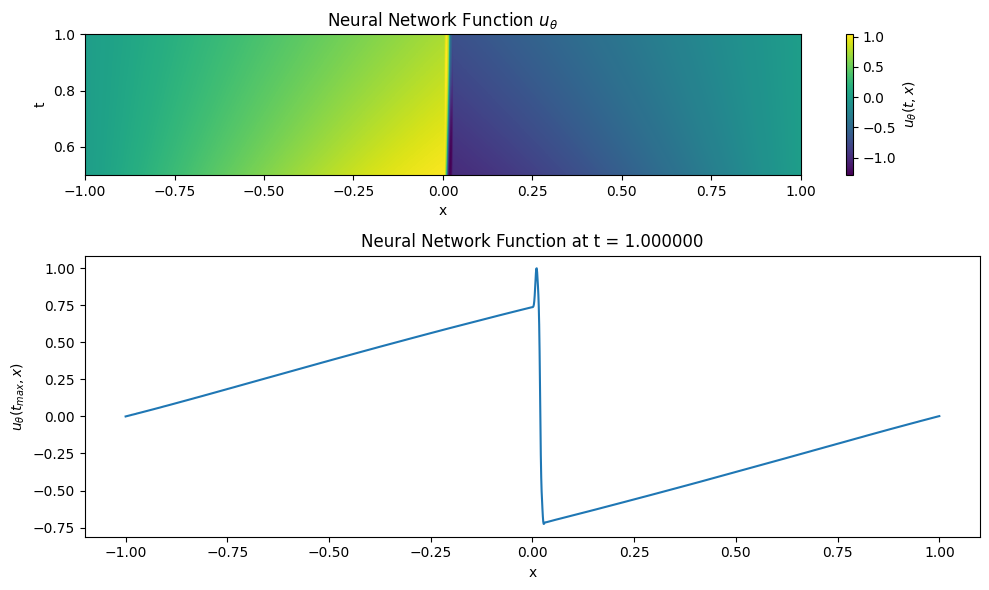


Plotting combined output across all segments from t=0 to total_t_max


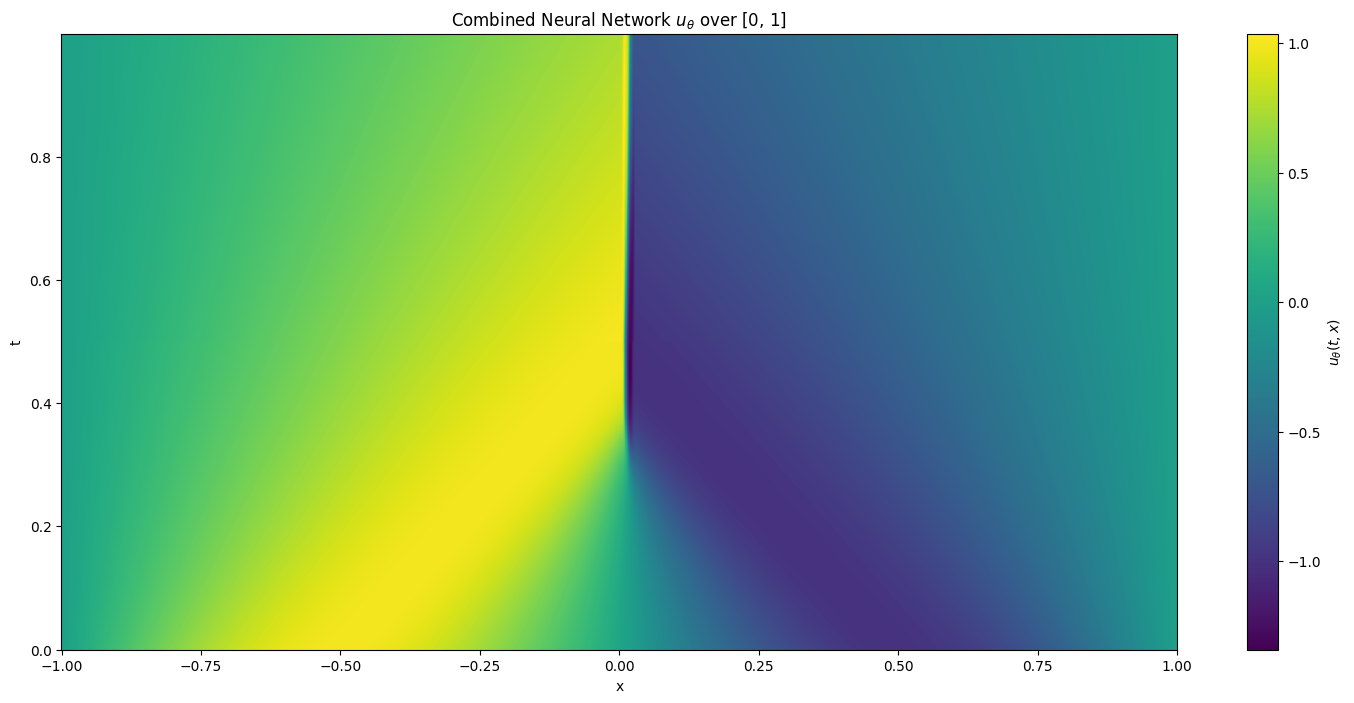

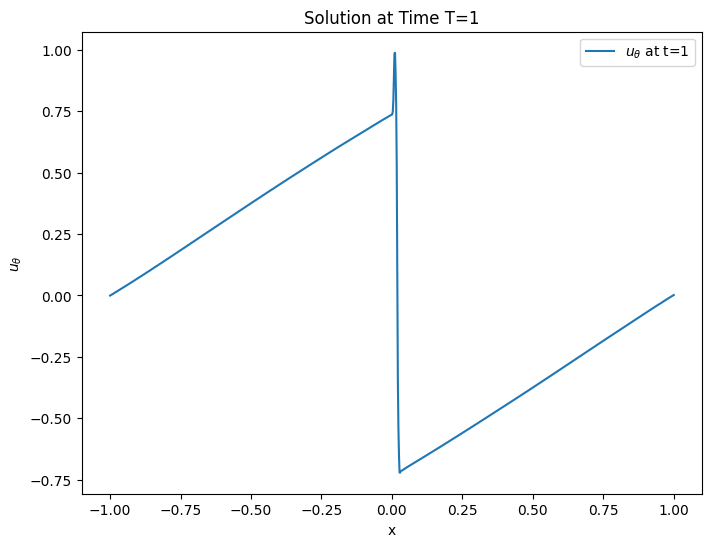

step,▁▁▂▂▂▃▃▄▄▅▅▅▆▆▆▆▇▇▇▇█▁▁▂▂▃▃▃▃▄▅▅▅▆▆▆▇▇▇█
tmin0.0_tmax0.5_loss_eqn_grade0,█▃▃▃▂▂▂▂▁▂▂▂▁▁▁▁▁▁▁▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.0_tmax0.5_loss_ibc_grade0,██▆▇▅▆▄▃▃▂▂▂▂▂▂▂▂▁▂▁▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_eqn_grade0,█▇▃▃▃▄▃▃▃▃▂▂▂▁▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_ibc_grade0,█▃▂▂▂▂▂▃▂▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,9900
tmin0.0_tmax0.5_loss_eqn_grade0,0.00282
tmin0.0_tmax0.5_loss_ibc_grade0,0.0003
tmin0.5_tmax1.0_loss_eqn_grade0,0.00131
tmin0.5_tmax1.0_loss_ibc_grade0,1e-05


In [ ]:
seq_trainer.train_seq()

Adding grade 1 with hidden dims [128, 128, 128, 128]

Plotting before training segment [0.0000, 0.5000]


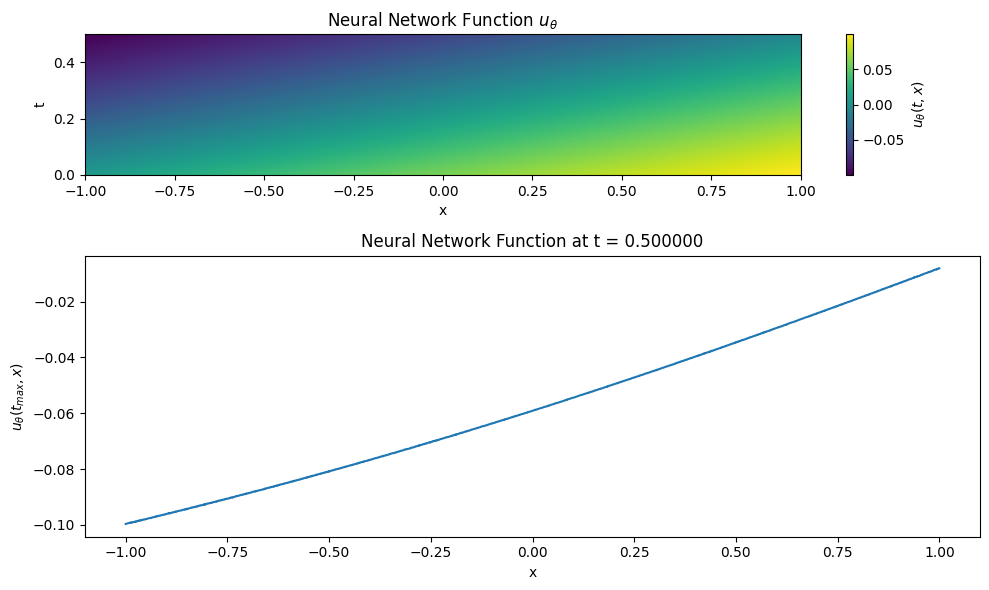


Training segment [0.0000, 0.5000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 9.730865, lambda_bc: 11.067774, lambda_eqn: 1.022727
Grade 0, Iter 0, loss_eqn: 0.228407, loss_eqn_from_kh: 0.228406, loss_eqn_abs: 0.228406, loss_ibc: 0.539963
Grade 0, Iter 100, loss_eqn: 0.118376, loss_eqn_from_kh: 0.118376, loss_eqn_abs: 0.118376, loss_ibc: 0.413318
Grade 0, Iter 200, loss_eqn: 0.444869, loss_eqn_from_kh: 0.444853, loss_eqn_abs: 0.444853, loss_ibc: 0.024301
Grade 0, Iter 300, loss_eqn: 0.331100, loss_eqn_from_kh: 0.331097, loss_eqn_abs: 0.331100, loss_ibc: 0.013102
Grade 0, Iter 400, loss_eqn: 0.251201, loss_eqn_from_kh: 0.251169, loss_eqn_abs: 0.251171, loss_ibc: 0.006061
Grade 0, Iter 500, loss_eqn: 0.205935, loss_eqn_from_kh: 0.205881, loss_eqn_abs: 0.205883, loss_ibc: 0.008408
Grade 0, Iter 600, loss_eqn: 0.177965, loss_eqn_from_kh: 0.177884, loss_eqn_abs: 0.177892, loss_ibc: 0.008008
Grade 0, Iter 700, loss_eqn: 0

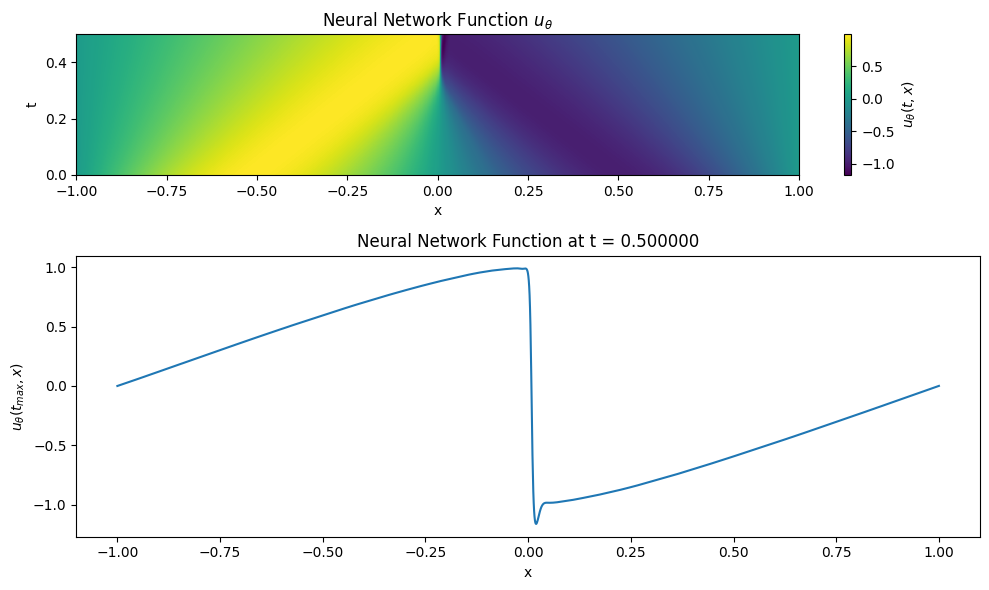

Adding grade 1 with hidden dims [128, 128, 128, 128]

Plotting before training segment [0.5000, 1.0000]


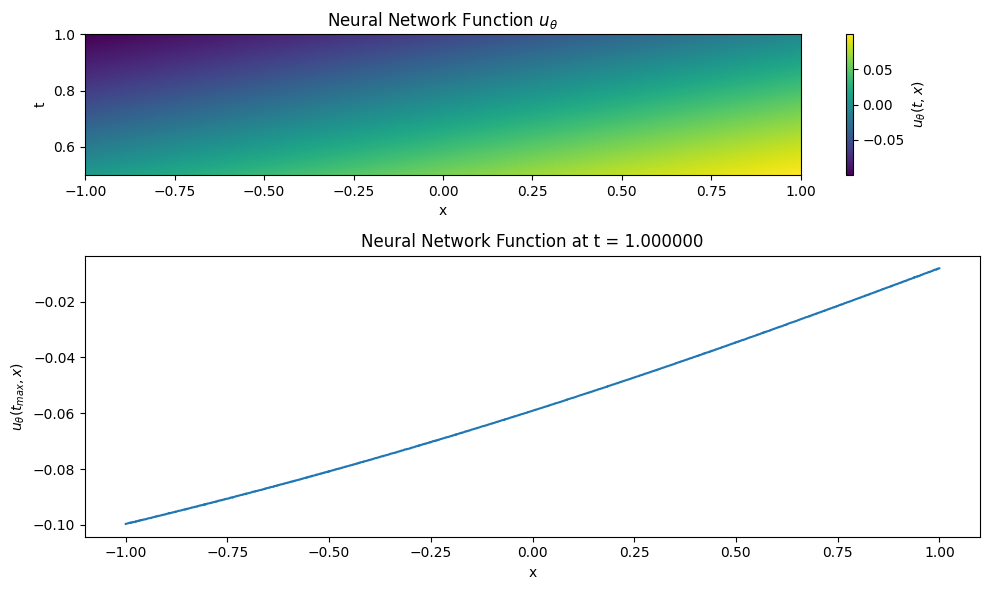


Training segment [0.5000, 1.0000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 10.052274, lambda_bc: 10.972286, lambda_eqn: 1.017060
Grade 0, Iter 0, loss_eqn: 0.228312, loss_eqn_from_kh: 0.228311, loss_eqn_abs: 0.228311, loss_ibc: 0.441596
Grade 0, Iter 100, loss_eqn: 0.042523, loss_eqn_from_kh: 0.042523, loss_eqn_abs: 0.042523, loss_ibc: 0.388595
Grade 0, Iter 200, loss_eqn: 0.397959, loss_eqn_from_kh: 0.397958, loss_eqn_abs: 0.397961, loss_ibc: 0.034705
Grade 0, Iter 300, loss_eqn: 0.372731, loss_eqn_from_kh: 0.372731, loss_eqn_abs: 0.374337, loss_ibc: 0.020366
Grade 0, Iter 400, loss_eqn: 0.318711, loss_eqn_from_kh: 0.318715, loss_eqn_abs: 0.355654, loss_ibc: 0.010995
Grade 0, Iter 500, loss_eqn: 0.249740, loss_eqn_from_kh: 0.249731, loss_eqn_abs: 0.356658, loss_ibc: 0.009161
Grade 0, Iter 600, loss_eqn: 0.160777, loss_eqn_from_kh: 0.160774, loss_eqn_abs: 0.369635, loss_ibc: 0.003030
Grade 0, Iter 700, loss_eqn: 

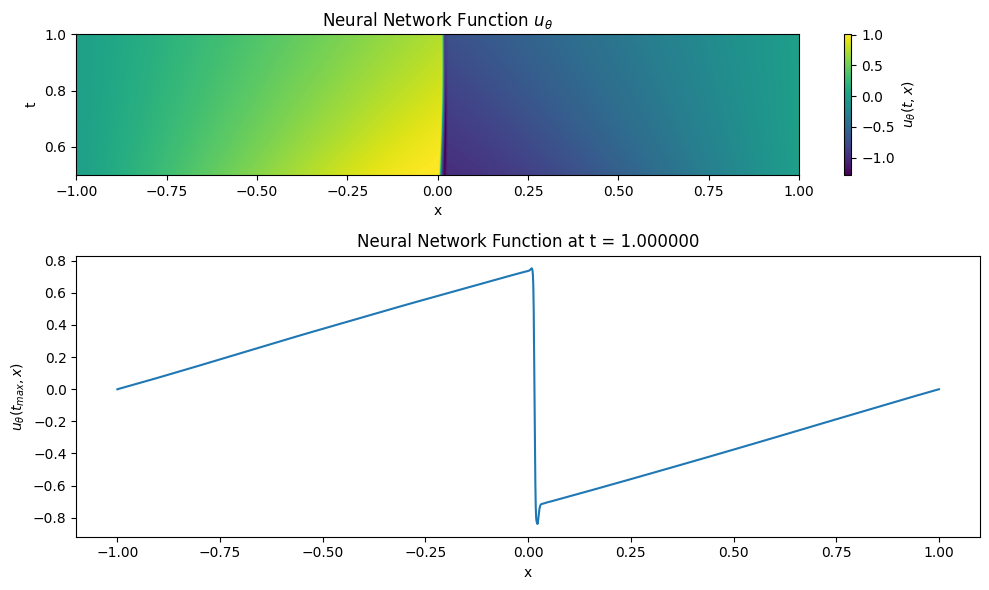


Plotting combined output across all segments from t=0 to total_t_max


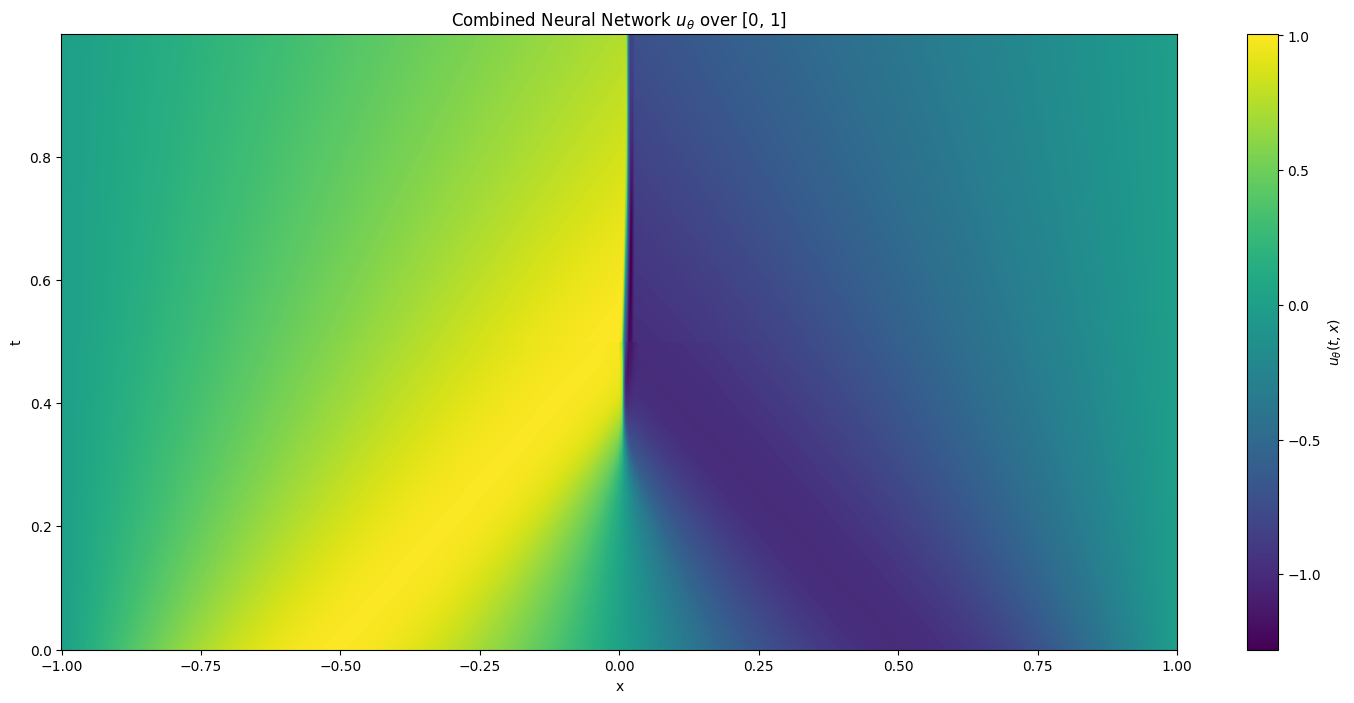

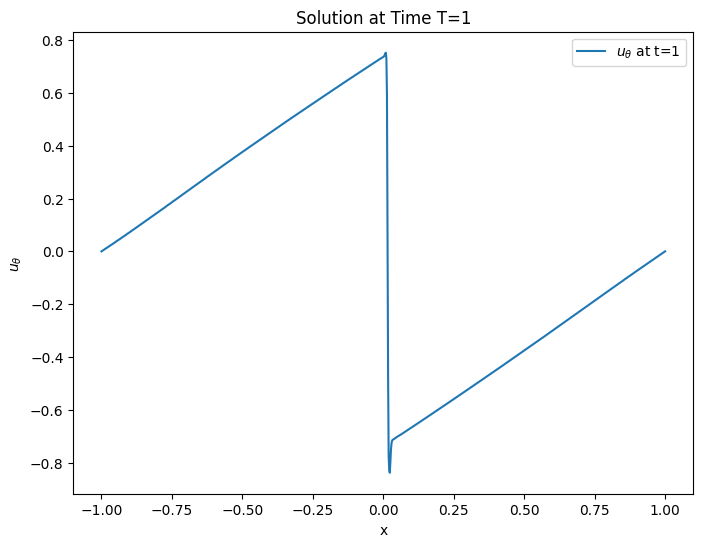

step,▁▁▂▂▂▃▃▃▃▄▄▅▅▅▅▆▇▇▇█▁▁▁▁▂▂▃▃▃▄▅▅▅▅▆▆▇▇██
tmin0.0_tmax0.5_loss_eqn_grade0,▄▃█▆▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.0_tmax0.5_loss_ibc_grade0,█▆▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_eqn_grade0,▅▂██▇▄▃▃▂▄▃▃▃▄▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_ibc_grade0,█▇▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,4900
tmin0.0_tmax0.5_loss_eqn_grade0,0.01869
tmin0.0_tmax0.5_loss_ibc_grade0,0.00017
tmin0.5_tmax1.0_loss_eqn_grade0,0.0059
tmin0.5_tmax1.0_loss_ibc_grade0,0.0001


In [ ]:
seq_trainer.train_seq()

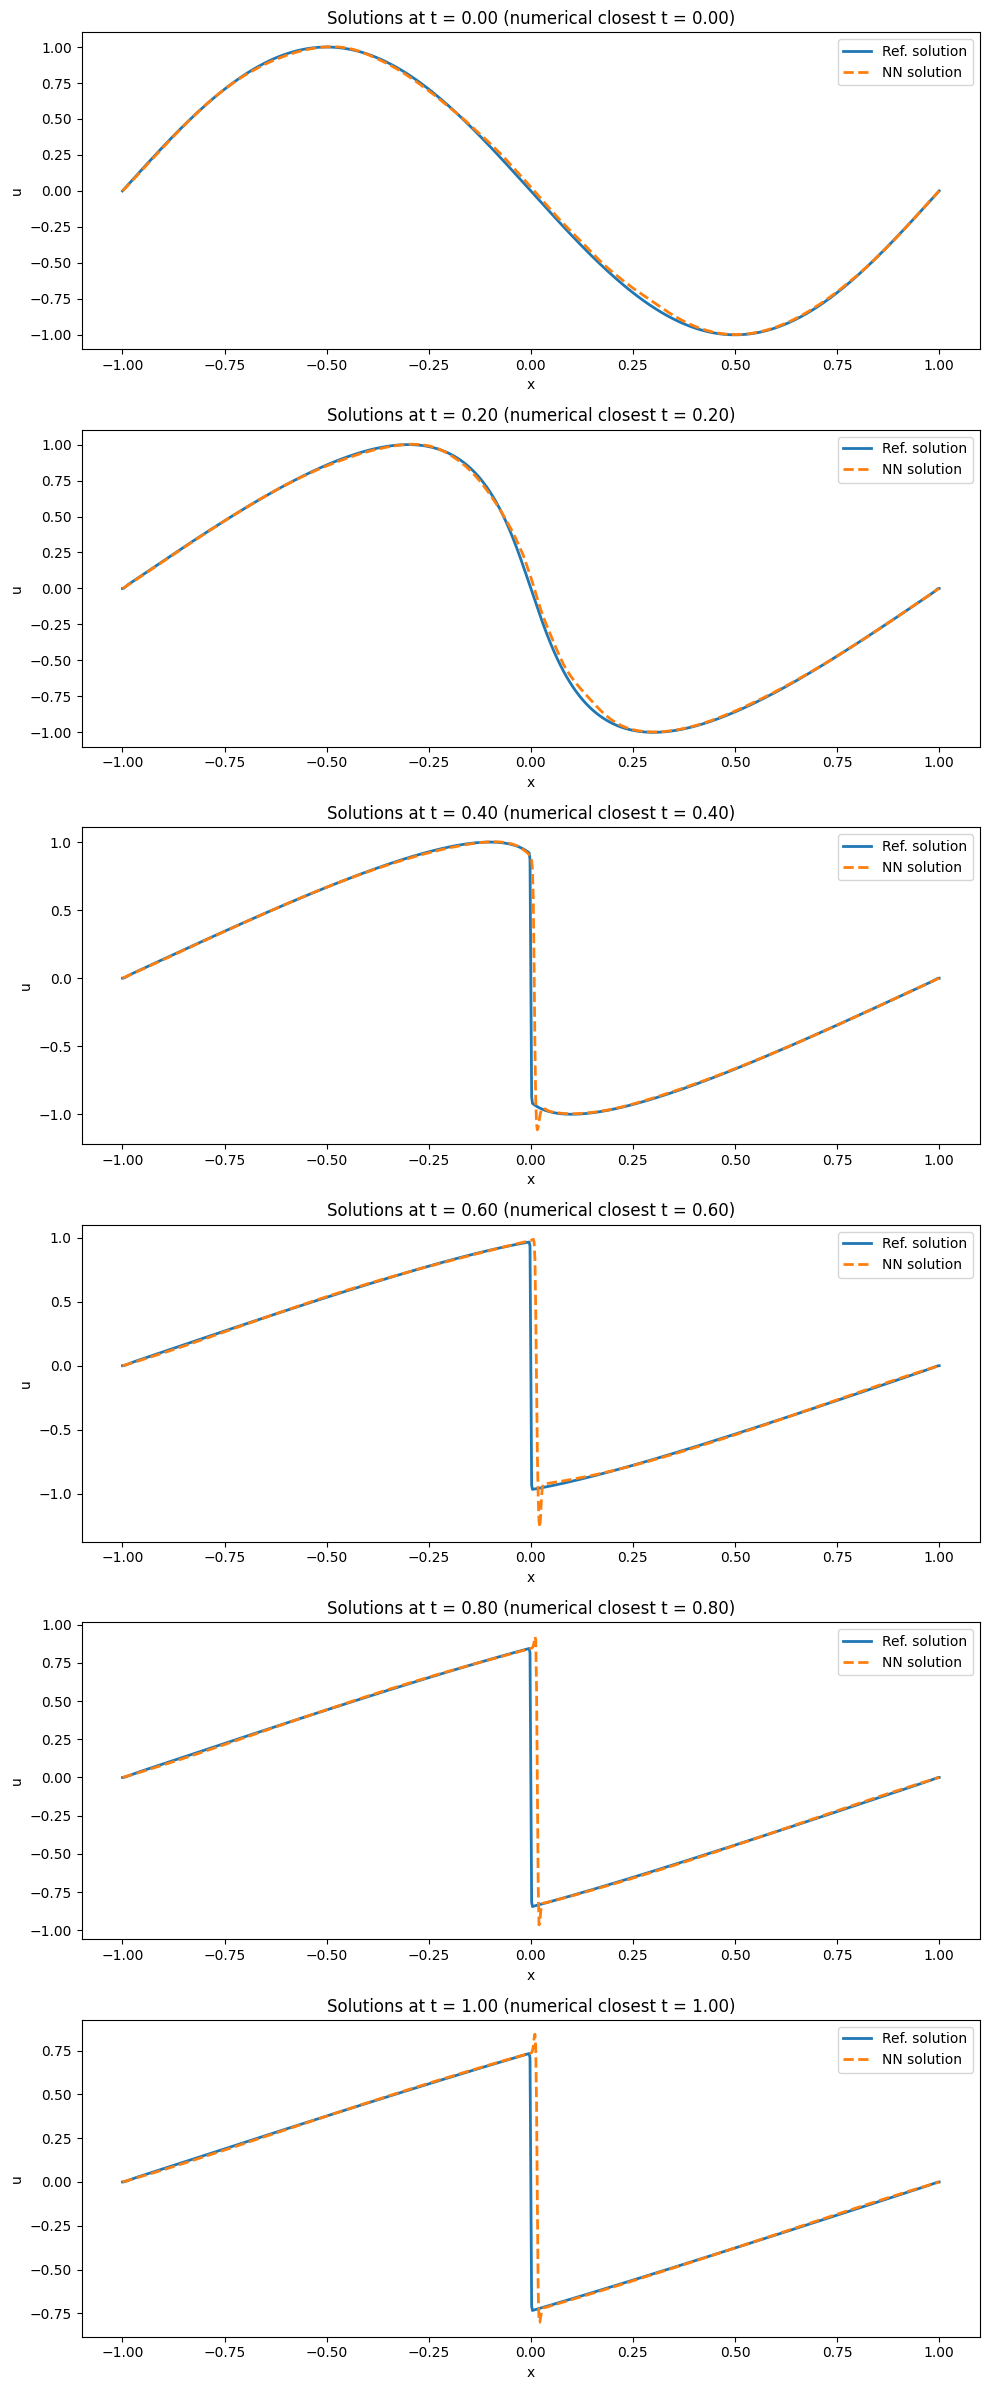

In [ ]:
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta
plot_comparison_seperate_combined_u_theta(seq_trainer, ts=[0.2*i for i in range(6)])

In [ ]:
compute_errors_combined_u_theta(seq_trainer)

Relative error at T: 0.041117876515388604
Space-time relative error: 0.026084324864206934


(np.float64(0.041117876515388604), np.float64(0.026084324864206934))

In [ ]:
data = np.load('data/burgers_sin_ref.npz')
times = data['times']
x = data['x']
u_num = data['u']  # Shape: (n_times, n_x)

In [ ]:
times[-1]

In [ ]:
idx_T = np.argmin(np.abs(times - 1.0))

In [ ]:
idx_T

In [ ]:
def plot_combined_u_theta(self, M_t_per_segment=1000, M_x=2000, upload_fig=False):
        """
        Plot the combined output of all trained segments over the full time domain [0, total_t_max].

        Args:
            M_t_per_segment (int): Number of grid points in t per segment.
            M_x (int): Number of grid points in x.
        """
        # Generate time grids for each segment based on self.seq_T
        t_grids = []
        for i in range(self.num_segments):
            t_min = self.seq_T[i]
            t_max = self.seq_T[i + 1]
            t_segment = jnp.linspace(t_min, t_max, M_t_per_segment+1)[:-1]
            t_grids.append(t_segment)

        # Concatenate all segment time grids into a full time grid
        t_grid_full = jnp.concatenate(t_grids)
        # Create the spatial grid
        x_grid = jnp.linspace(self.x_min, self.x_max, M_x)

        # Create a meshgrid for t and x
        t, x = jnp.meshgrid(t_grid_full, x_grid, indexing='ij')  # Shapes: (total_M_t, M_x)

        # Flatten the grid for evaluation
        tx_points_full = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (total_M_t * M_x, 2)

        # Determine which segment each time point belongs to
        segment_indices = jnp.digitize(tx_points_full[:, 0], self.seq_T) - 1
        segment_indices = jnp.clip(segment_indices, 0, self.num_segments - 1)

        # Collect outputs from each segment
        u_values_full = []
        for i in range(self.num_segments):
            mask = (segment_indices == i)
            tx_points_segment = tx_points_full[mask]
            if tx_points_segment.size > 0:
                segment = self.segments[i]
                u_values_segment = segment.model.forward(tx_points_segment)
                u_values_full.append(u_values_segment)

        # Combine all segment outputs into a single array
        u_values_full = jnp.concatenate(u_values_full)
        u_values_full = u_values_full.reshape(len(t_grid_full), M_x)

        # Create the plot
        t_range = self.total_t_max - self.total_t_min
        fig = plt.figure(figsize=(10, 4 + 4 * t_range))
        gs = gridspec.GridSpec(2, 1, height_ratios=[t_range, 1])
        ax1 = fig.add_subplot(gs[0])
        ax2 = fig.add_subplot(gs[1])

        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, t_grid_full, u_values_full, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1, label='$u_\\theta(t, x)$')
        ax1.set_xlabel('x')
        ax1.set_ylabel('t')
        ax1.set_title(f'Combined Neural Network $u_\\theta$ over [{self.total_t_min}, {self.total_t_max}]')

        # 1D plot at t = t_max
        # Get the last segment
        segment = self.segments[-1]
        t_jnp = jnp.full_like(x_grid, self.total_t_max)
        tx_points_max = jnp.stack([t_jnp, x_grid], axis=1)  # Shape: (M_x, 2)
        u_at_max = segment.model.forward(tx_points_max)
        ax2.plot(x_grid, u_at_max)
        ax2.set_xlabel('x')
        ax2.set_ylabel('$u_\\theta(t_{max}, x)$')
        ax2.set_title(f'Neural Network Function at t = {self.total_t_max:.2f}')

        # Adjust layout and display the main plot
        plt.tight_layout()
        # Upload the figure to wandb
        plt.show()

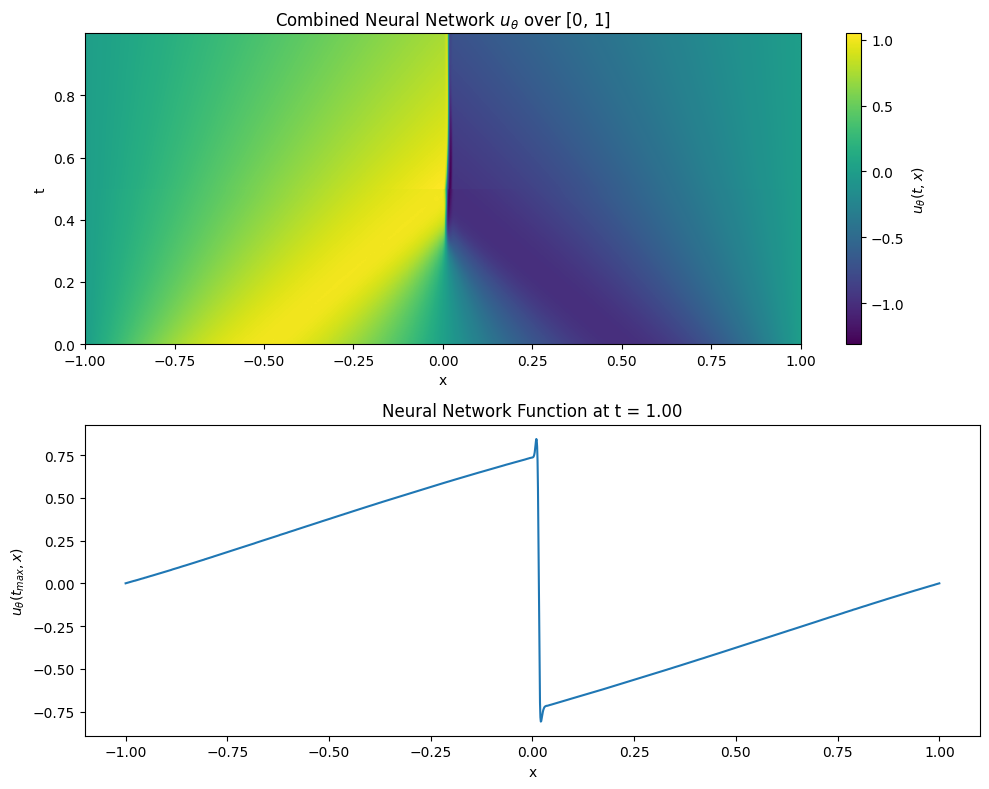

In [ ]:
seq_trainer.plot_combined_u_theta()